# Proyecto Final · Cuarto entregable · Modelo original para predecir la suscripción a depósitos a término (*Bank Marketing*, UCI)

**Logística de estado latente en dos escalas (L2E): diseño, implementación algorítmica y validación estadística frente a los modelos del tercer entregable**

| | |
|---|---|
| **Autor** | Donny Torres |
| **Programa** | Maestría en Analítica de Datos, Universidad del Norte (Barranquilla) |
| **Asignatura** | Machine Learning |
| **Fecha** | Octubre de 2026 |
| **Conjunto de datos** | *Bank Marketing* con contexto social y económico (`bank-additional-full.csv`) y tres conjuntos adicionales de OpenML |
| **Fuente** | UCI Machine Learning Repository: <https://archive.ics.uci.edu/dataset/222/bank+marketing> (licencia CC BY 4.0) |
| **Tarea** | Clasificación de `y` (suscribe o no) con información previa a la llamada y validación cronológica |
| **Guía** | *Proyecto Final: Dashboard Predictivo, Modelo Original e Informe Reproducible* |

## 0. Introducción

Este cuaderno desarrolla el componente de investigación del proyecto: **un modelo propio**, que no proviene de un `import`, se implementa algorítmicamente y se compara estadísticamente contra los modelos del tercer entregable. Mantiene las mismas condiciones de ese entregable, esto es, el mismo conjunto de datos, la misma partición cronológica 80/20, el mismo preprocesamiento, los mismos pliegues externos e internos de la validación anidada, la misma semilla y el mismo presupuesto de optimización, de modo que cualquier diferencia se debe al modelo y no al protocolo.

**Pregunta de investigación.** ¿Un modelo que sigue día a día la tasa de suscripción puede predecir, antes de la llamada, qué clientes suscribirán un depósito a término mejor que los clasificadores estáticos?

Retoma la pregunta del Entregable 1 (sección 1.1), que medía la capacidad de discriminación de una regresión logística con información previa a la llamada y su estabilidad en el orden temporal, y la lleva al modelo original. Los clasificadores estáticos son los siete modelos del tercer entregable (logística, Naive Bayes, KNN, árbol de decisión, Random Forest, XGBoost y SVM), que asumen que la relación entre el cliente y la suscripción no cambia en el tiempo.

**Productos en línea.**

- **Dashboard predictivo:** <https://proyecto-final-bank-marketing.onrender.com> (páginas Contexto, EDA y Modelos, con el L2E integrado; en el plan gratuito de Render la primera carga tras 15 minutos sin visitas tarda cerca de un minuto).
- **Jupyter Book:** <https://dtl-da.github.io/proyecto-final-bank-marketing/cuarto-entregable/>.
- **Repositorio:** <https://github.com/DTL-DA/proyecto-final-bank-marketing>; este cuaderno, su código y sus resultados están en la carpeta `cuarto_entregable/`.

El punto de partida es una evaluación crítica de lo que ya se hizo. Las 140 combinaciones del tercer entregable no se distinguen entre sí, dentro de 2008 ninguna discrimina mejor que el azar y la mejor mejora en la prueba no vino de un modelo más flexible sino de recalibrar el intercepto cada mes. Ese patrón tiene una explicación: la tasa de suscripción de cada día es un **nivel latente persistente** que los modelos estáticos no pueden seguir. Sobre ese diagnóstico se propone el modelo L2E, una regresión logística cuyo intercepto es un estado latente diario que se mueve en una escala rápida y cuyas pendientes derivan en una escala lenta, que se ajusta por máxima verosimilitud penalizada con un algoritmo de Newton por bloques y que, en producción, se actualiza con un filtro de Laplace a medida que se conocen las etiquetas de los días ya cerrados.

**Organización.** La numeración de las secciones sigue los capítulos del Jupyter Book que pide la guía (cuadro 4), así que cada sección del cuaderno es un capítulo del libro:

| Sección | Contenido | Bloque o sección de la guía |
|---|---|---|
| 0. Introducción | Resumen ejecutivo, configuración y carga de resultados | 9.1 |
| 1. Trazabilidad de correcciones | Evaluación crítica del tercer entregable y tabla de correcciones | Bloque A |
| 2. Datos: ETL y EDA | Partición heredada y nuevo hallazgo: el nivel diario latente | 9.1 |
| 3. Modelos benchmark | Mejores combinaciones por modelo y mejor combinación global | Bloque B |
| 4. Revisión de literatura y novedad | Protocolo, matriz de novedad, trabajos cercanos y declaración | 5.2 |
| 5. Modelo original | Formulación, pseudocódigo, propiedades, código, pruebas unitarias, complejidad, optimización y ablación | Bloque C, 5.3 y 5.4 |
| 6. Validación estadística | Protocolo, pruebas de hipótesis, controles, robustez, conjuntos adicionales e interpretabilidad | Bloque D y sección 6 |
| 7. Dashboard y despliegue | Artefacto del modelo original, prueba de ida y vuelta, predicción en vivo, arquitectura, decisiones de diseño, guía de despliegue, capturas y URL pública | Bloques B, E y F |
| 8. Conclusiones y limitaciones | Hallazgos, veredicto sobre R1, R2 y R3, limitaciones, trabajo futuro y uso de IA | 9.1 y 13 |
| 9. Reproducibilidad y bibliografía | Entorno, semillas, tabla maestra de experimentos y referencias | 9.1 y 10 |

**Ejecución.** La validación anidada del modelo original (7 variantes × 5 pliegues, con Optuna en el bucle interno), los modelos finales, los tres conjuntos adicionales, los análisis de sensibilidad y la revisión de literatura se ejecutan con los *scripts* de `scripts/` y quedan registrados en `resultados/`; este cuaderno los lee y calcula aquí todas las pruebas estadísticas. Con `RECALCULAR = True` en la celda de configuración se vuelven a lanzar los *scripts*. Todas las interpretaciones se generan con los valores calculados en la misma ejecución, de forma que las cifras del texto coinciden siempre con las salidas.

### 0.1 Configuración del entorno y reproducibilidad

La semilla global es la misma del tercer entregable (`SEED = 42`, en `src/bm/config.py`) y se propaga a `numpy`, scikit-learn, SMOTE y ADASYN, XGBoost, Optuna y DEAP. El modelo L2E es determinista: su ajuste maximiza un objetivo estrictamente cóncavo con Newton, así que la semilla solo afecta al optimizador de hiperparámetros, cuya estabilidad se mide con tres semillas adicionales (sección 6.9). El entorno es `bm_e3` (Python 3.12) y las versiones exactas están en `requirements.txt`.

In [1]:
import json
import pickle
import platform
import subprocess
import sys
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import Markdown, display
from scipy import stats
from scipy.special import expit
from sklearn.metrics import (average_precision_score, brier_score_loss, log_loss, precision_recall_curve,
                             roc_auc_score)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message=".*Pandas4Warning.*")
sys.path.insert(0, str(Path("src").resolve()))

import optuna
import scikit_posthocs as sp

from bm import config as cfg
from bm import estadistica as st
from bm import estadistica_e4 as st4
from bm import evaluacion as evm
from bm.adicionales import DESCRIPCION as DESC_ADIC
from bm.anidada import particion
from bm.datos import cv_externa, cv_interna
from bm.evaluacion import elegir_finalistas
from bm.modelo_original import LogisticaDosEscalas, filtrar_nivel
from bm.protocolo_original import (NOMBRE_VARIANTE, VARIANTES, con_dia, construir_pipeline_original, em_por_dia,
                                   logit_seguro, puntaje_secuencial)

SEED = cfg.SEED
np.random.seed(SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
RECALCULAR = False  # True: vuelve a ejecutar todos los scripts de resultados/ (cerca de 45 minutos con 10 núcleos)
if RECALCULAR:
    for script in ("importar_e3.py", "ejecutar_original.py", "ejecutar_adicionales.py", "ejecutar_analisis.py",
                   "revision_literatura.py", "verificar_referencias.py"):
        subprocess.run([sys.executable, f"scripts/{script}"], check=True)

# Paleta validada del proyecto: categórica en orden fijo, tinta y rejilla recesivas
AZUL, NARANJA, AGUAMARINA, AMARILLO, ROJO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948"
TINTA, TINTA_2, GRIS, REJILLA, FONDO = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
CMAP_SEQ = mpl.colors.LinearSegmentedColormap.from_list("secuencial", ["#f0efec", "#9ec5f4", "#2a78d6", "#0d366b"])
CMAP_DIV = mpl.colors.LinearSegmentedColormap.from_list("divergente", [AZUL, "#f0efec", ROJO])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.facecolor": FONDO, "axes.facecolor": FONDO,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA, "axes.titlesize": 10.5,
    "axes.titleweight": "bold", "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": GRIS, "ytick.color": GRIS, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.frameon": False, "legend.fontsize": 8, "figure.titlesize": 12, "figure.titleweight": "bold",
    "axes.prop_cycle": mpl.cycler(color=[AZUL, NARANJA, AGUAMARINA, AMARILLO]), "lines.linewidth": 2,
})


def num(x, d=0):
    """Número con coma decimal y espacio de miles."""
    return f"{x:,.{d}f}".replace(",", " ").replace(".", ",")


def num_c(x):
    """Valor de un hiperparámetro sin ceros sobrantes (0,001; 0,1; 100)."""
    return f"{x:.3g}".replace(".", ",")


def pct(x, d=1):
    return f"{num(100 * x, d)} %"


def pval(p):
    return "< 0,001" if p < 0.001 else num(p, 3)


def p_txt(p):
    return "p < 0,001" if p < 0.001 else f"p = {num(p, 3)}"


def p_frase(p):
    """Valor p para insertar en una frase: «menor que 0,001» o «de 0,123»."""
    return "menor que 0,001" if p < 0.001 else f"de {num(p, 3)}"


def interpretar(interpretacion, implicacion, accion):
    display(Markdown(f"**Interpretación.** {interpretacion}\n\n{implicacion}\n\n{accion}"))


def conectar(conector, texto):
    """Antepone un conector al texto y pasa a minúscula su primera letra."""
    return f"{conector} {texto[:1].lower()}{texto[1:]}" if texto else texto


def tabla(df, dec=3, indice=True):
    sty = df.style.format(precision=dec, decimal=",", thousands=" ", na_rep="—")
    if not indice:
        sty = sty.hide(axis="index")
    display(sty)


def enumerar(items, codigo=False):
    """Une una lista en español: a, b y c."""
    items = [f"`{i}`" if codigo else str(i) for i in items]
    if not items:
        return ""
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " y " + items[-1]


def para_guion(nombre, obj):
    """Guarda una tabla o un diccionario para el guion de sustentación (mismas cifras que el cuaderno)."""
    destino = Path("resultados") / "guion"
    destino.mkdir(parents=True, exist_ok=True)
    if isinstance(obj, pd.DataFrame):
        obj.to_parquet(destino / f"{nombre}.parquet")
    else:
        (destino / f"{nombre}.json").write_text(json.dumps(obj, default=float, ensure_ascii=False, indent=1),
                                               encoding="utf-8")


def ms(serie, d=3):
    """Media ± desviación estándar con coma decimal."""
    return f"{num(np.mean(serie), d)} ± {num(np.std(serie, ddof=1), d)}"


versiones = pd.DataFrame({
    "Componente": ["Python", "numpy", "pandas", "scipy", "scikit-learn", "optuna", "scikit-posthocs", "matplotlib"],
    "Versión": [platform.python_version(), np.__version__, pd.__version__, scipy.__version__, sklearn.__version__,
                optuna.__version__, sp.__version__, mpl.__version__]})
tabla(versiones, indice=False)
print(f"Semilla global: SEED = {SEED}")

Componente,Versión
Python,3.12.14
numpy,2.5.4
pandas,3.0.6
scipy,1.18.1
scikit-learn,1.9.1
optuna,5.0.0
scikit-posthocs,0.17.1
matplotlib,3.11.2


Semilla global: SEED = 42


### 0.2 Carga de la partición y de los resultados

Se reconstruye la partición cronológica con el mismo código del tercer entregable (`bm.anidada.particion`) y se leen tres grupos de resultados: los del tercer entregable (`resultados/e3`, importados con `scripts/importar_e3.py`), los del modelo original (validación anidada, ablación, semillas y modelos finales) y los complementarios (conjuntos adicionales, sensibilidad, SHAP, complejidad y revisión de literatura).

In [2]:
part = particion()
X_tr, X_te, y_tr, y_te = part.X_tr, part.X_te, part.y_tr, part.y_te
tiempo_tr, tiempo_te, GAP = part.tiempo_tr, part.tiempo_te, part.gap
periodo_tr, periodo_te = tiempo_tr["periodo"], tiempo_te["periodo"]
dia_tr, dia_te = tiempo_tr["dia"].to_numpy(), tiempo_te["dia"].to_numpy()
tiempo = pd.concat([tiempo_tr, tiempo_te])
yte = y_te.to_numpy()

RES = cfg.RUTA_RESULTADOS
E3 = RES / "e3"
maestra = pd.read_parquet(E3 / "tabla_maestra.parquet")
pliegues_e3 = pd.read_parquet(E3 / "pliegues.parquet")
oof_e3 = pd.read_parquet(E3 / "oof_finalistas.parquet")
with open(E3 / "finales_clf.pkl", "rb") as f:
    fin_e3 = pickle.load(f)
fin_ext = elegir_finalistas(maestra, "clf")
MODELOS = fin_ext["modelo"].tolist()  # ordenados por AUC-PR externo medio (el primero es el mejor global)
MEJOR = MODELOS[0]


def leer(ruta):
    with open(ruta, "rb") as f:
        return pickle.load(f)


corr = {v: [leer(RES / "corridas_original" / f"{v}_{k}.pkl") for k in range(cfg.K_EXTERNO)] for v in VARIANTES}
corr_sem = {s: [leer(RES / "corridas_original" / f"l2e_{k}_s{s}.pkl") for k in range(cfg.K_EXTERNO)] for s in (1, 2, 3)}
fin_l2e = {v: leer(RES / "finales_original" / f"{v}.pkl") for v in VARIANTES}
fin_sem = {s: leer(RES / "finales_original" / f"l2e_s{s}.pkl") for s in (1, 2, 3)}
L2E = fin_l2e["l2e"]
adic = pd.read_parquet(RES / "adicionales.parquet")
ANA = RES / "analisis"
literatura = json.loads((RES / "literatura" / "consultas.json").read_text(encoding="utf-8"))

# Nombres y colores: la identidad sigue a la entidad, nunca al rango
NOMBRE = {"L2E": "L2E (modelo original)", "referencia_e2": "Referencia E2 (logística C = 0,01)"}
for r_ in fin_ext.itertuples():
    NOMBRE[r_.modelo] = f"{cfg.NOMBRE_MODELO[r_.modelo]} · {cfg.NOMBRE_BALANCEO[r_.balanceo]} · " \
                        f"{cfg.NOMBRE_OPTIMIZADOR[r_.optimizador]}"
CORTO = {"L2E": "L2E", "referencia_e2": "Referencia E2", **{m: cfg.NOMBRE_MODELO[m] for m in MODELOS}}
COLOR = {"L2E": TINTA, "referencia_e2": GRIS, **{m: CAT[cfg.MODELOS_CLF.index(m)] for m in MODELOS}}

# Puntajes de prueba de todos los modelos comparados (mismas 8 236 observaciones, mismo orden)
PUNTAJE_TE = {"L2E": L2E["puntaje_te"], **{m: fin_e3[f"clf_{m}"]["puntaje_te"] for m in MODELOS},
              "referencia_e2": fin_e3["clf_referencia_e2"]["puntaje_te"]}
ES_PROBA = {"L2E": True, **{m: fin_e3[f"clf_{m}"]["es_proba"] for m in MODELOS}, "referencia_e2": True}

# Predicciones fuera de muestra del bucle externo (mismos pliegues para todos)
oof_l2e = pd.concat([pd.DataFrame({"modelo": "L2E", "pliegue": c["pliegue"], "indice": c["oof"]["indice"],
                                   "y": c["oof"]["y"], "puntaje": c["oof"]["puntaje"]}) for c in corr["l2e"]])
oof = pd.concat([oof_e3[["modelo", "pliegue", "indice", "y", "puntaje"]].astype({"modelo": str}), oof_l2e],
                ignore_index=True)
oof["periodo"] = tiempo.loc[oof["indice"], "periodo"].to_numpy()
oof["dia"] = tiempo.loc[oof["indice"], "dia"].to_numpy()
assert oof.groupby("modelo")["indice"].apply(lambda s: tuple(np.sort(s))).nunique() == 1  # mismas observaciones

print(f"Partición: {num(len(X_tr))} registros de entrenamiento y {num(len(X_te))} de prueba · "
      f"{len(maestra)} combinaciones del tercer entregable · {sum(len(v) for v in corr.values())} corridas anidadas "
      f"del modelo original ({len(VARIANTES)} variantes) · {len(adic)} corridas en conjuntos adicionales")

Partición: 32 940 registros de entrenamiento y 8 236 de prueba · 140 combinaciones del tercer entregable · 35 corridas anidadas del modelo original (7 variantes) · 150 corridas en conjuntos adicionales


In [3]:
ext_l2e = np.array([c["auc_pr"] for c in corr["l2e"]])
ext_mejor = pliegues_e3.merge(fin_ext.iloc[[0]][["modelo", "balanceo", "optimizador"]])["auc_pr"].to_numpy()
ap_te = {k: average_precision_score(yte, s) for k, s in PUNTAJE_TE.items()}
auc_te = {k: roc_auc_score(yte, s) for k, s in PUNTAJE_TE.items()}
mejor_te = max((k for k in ap_te if k != "L2E"), key=ap_te.get)
display(Markdown(f"""### Resumen ejecutivo

- **Problema.** Predecir, antes de la llamada, qué clientes suscribirán un depósito a término, en un periodo en que la tasa de suscripción pasa del {pct(y_tr.mean())} (entrenamiento, 2008-2009) al {pct(y_te.mean())} (prueba, 2009-2010).
- **Pregunta de investigación.** ¿Un modelo que sigue día a día la tasa de suscripción puede predecir, antes de la llamada, qué clientes suscribirán un depósito a término mejor que los clasificadores estáticos?
- **Diagnóstico del tercer entregable.** La mejor de las 140 combinaciones, {NOMBRE[MEJOR]}, logra un AUC-PR externo de {ms(ext_mejor)}; en los pliegues de 2008 ningún modelo supera de forma apreciable a la prevalencia, y en la prueba el mejor AUC-PR es el de {CORTO[mejor_te]} ({num(ap_te[mejor_te], 3)}). La señal que falta es temporal: la tasa diaria de suscripción es un nivel latente persistente (sección 2.2).
- **Modelo original.** L2E: regresión logística con un nivel diario latente en paseo aleatorio (escala rápida), pendientes que derivan lentamente (escala lenta), ajuste por moda posterior con Newton por bloques en O(T) y filtro de Laplace con etiquetas diferidas un día. Implementado desde cero con `numpy` y `scipy` (`src/bm/modelo_original.py`), con {len([l for l in Path('tests/test_modelo_original.py').read_text(encoding='utf-8').splitlines() if l.startswith('def test_')])} funciones de prueba unitaria.
- **Resultado.** En el bucle externo, L2E obtiene {ms(ext_l2e)} frente a {ms(ext_mejor)} de la mejor combinación benchmark; en la prueba, AUC-PR de {num(ap_te['L2E'], 3)} y AUC de {num(auc_te['L2E'], 3)}, frente a {num(ap_te[mejor_te], 3)} y {num(max(v for k, v in auc_te.items() if k != 'L2E'), 3)} del mejor benchmark en cada métrica. La sección 6 verifica si la diferencia es significativa, con qué pruebas y de qué magnitud, y dónde el modelo no supera a los benchmarks."""))

### Resumen ejecutivo

- **Problema.** Predecir, antes de la llamada, qué clientes suscribirán un depósito a término, en un periodo en que la tasa de suscripción pasa del 6,4 % (entrenamiento, 2008-2009) al 30,8 % (prueba, 2009-2010).
- **Pregunta de investigación.** ¿Un modelo que sigue día a día la tasa de suscripción puede predecir, antes de la llamada, qué clientes suscribirán un depósito a término mejor que los clasificadores estáticos?
- **Diagnóstico del tercer entregable.** La mejor de las 140 combinaciones, Naive Bayes · class_weight · Bayesiana (Optuna TPE), logra un AUC-PR externo de 0,103 ± 0,108; en los pliegues de 2008 ningún modelo supera de forma apreciable a la prevalencia, y en la prueba el mejor AUC-PR es el de Referencia E2 (0,548). La señal que falta es temporal: la tasa diaria de suscripción es un nivel latente persistente (sección 2.2).
- **Modelo original.** L2E: regresión logística con un nivel diario latente en paseo aleatorio (escala rápida), pendientes que derivan lentamente (escala lenta), ajuste por moda posterior con Newton por bloques en O(T) y filtro de Laplace con etiquetas diferidas un día. Implementado desde cero con `numpy` y `scipy` (`src/bm/modelo_original.py`), con 18 funciones de prueba unitaria.
- **Resultado.** En el bucle externo, L2E obtiene 0,111 ± 0,116 frente a 0,103 ± 0,108 de la mejor combinación benchmark; en la prueba, AUC-PR de 0,602 y AUC de 0,772, frente a 0,548 y 0,724 del mejor benchmark en cada métrica. La sección 6 verifica si la diferencia es significativa, con qué pruebas y de qué magnitud, y dónde el modelo no supera a los benchmarks.

## 1. Trazabilidad de correcciones

### 1.1 Evaluación crítica del tercer entregable

Antes de proponer un modelo nuevo conviene preguntarse qué limitó a los 140 anteriores. La guía pide superar a los benchmarks, y eso solo tiene sentido si se entiende por qué ninguno de ellos se distinguió de los demás. Se revisan tres evidencias del tercer entregable: el desempeño por pliegue externo frente a la prevalencia de cada bloque (el AUC-PR de un clasificador aleatorio es igual a la prevalencia, así que su cociente, la **mejora sobre el azar**, es lo que mide la discriminación), el desempeño en la prueba y el efecto de la recalibración mensual del intercepto.

,Valida desde,Valida hasta,Prevalencia,Mejor AUC-PR (140 combinaciones),Mejora sobre el azar (mediana de finalistas),AUC máx. (finalistas)
Pliegue,,,,,,
1,2008-05,2008-06,"0,039","0,046","1,043","0,523"
2,2008-06,2008-07,"0,060","0,069","1,020","0,522"
3,2008-07,2008-08,"0,059","0,070","1,050","0,521"
4,2008-08,2008-11,"0,054","0,058","0,950","0,491"
5,2008-11,2009-05,"0,140","0,296","1,815","0,716"


Modelo,AUC-PR prueba,AUC prueba,AUC-PR con recalibración mensual,AUC con recalibración mensual
Naive Bayes · class_weight · Bayesiana (Optuna TPE),"0,534","0,714","0,478","0,677"
Logística L1/L2 · SMOTE · Random Search,"0,530","0,681","0,584","0,761"
Random Forest · Sin balanceo · Bayesiana (Optuna TPE),"0,503","0,720","0,541","0,742"
SVM · class_weight · Grid Search,"0,538","0,724",—,—
XGBoost · class_weight · Genético (DEAP),"0,369","0,559","0,482","0,721"
Árbol de decisión · SMOTE · Bayesiana (Optuna TPE),"0,374","0,567","0,423","0,615"
KNN · class_weight · Grid Search,"0,500","0,688","0,577","0,756"
"Referencia E2 (logística C = 0,01)","0,548","0,710","0,579","0,758"


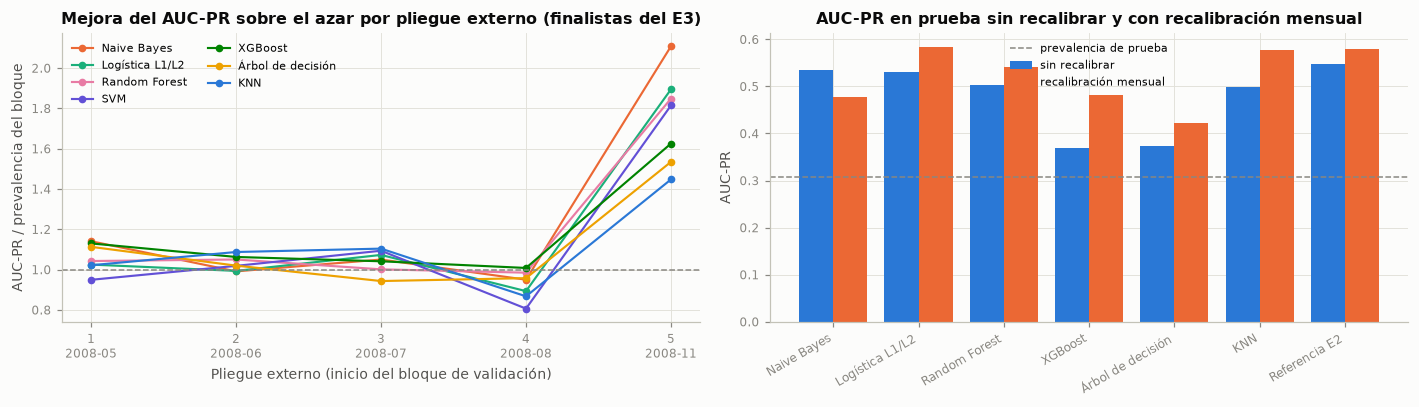

**Interpretación.** En 4 de los 4 primeros pliegues externos (validación dentro de 2008) la mediana de los finalistas apenas supera a la prevalencia (mejora sobre el azar entre 0,95 y 1,05), con AUC máximo de 0,523; solo el último pliegue, que valida de 2008-11 a 2009-05, muestra señal (mejora mediana de 1,81). En la prueba, el AUC-PR de los finalistas va de 0,369 a 0,548, y la recalibración mensual del intercepto lo sube en 6 de los 7 modelos con probabilidades (mediana de 0,049).

Esto significa que el ordenamiento de las 140 combinaciones lo decide casi por completo un solo bloque de validación, y que la mejora más grande del tercer entregable no vino de un modelo más flexible ni de una mejor búsqueda de hiperparámetros, sino de ajustar el intercepto a la tasa del mes que acaba de cerrar. Si desplazar un solo número por mes mejora el ordenamiento global más que cambiar de familia de modelos, la información que falta no está en las variables del cliente: está en el **momento** de la llamada, en un nivel de conversión que cambia con el tiempo y que un modelo estático no puede seguir.

Por tal motivo, se opta por dirigir el modelo original a ese vacío: en lugar de otro clasificador estático, un modelo que trate el nivel de conversión como un estado latente y lo actualice con las etiquetas que la operación genera cada día. La sección 2.2 verifica con el entrenamiento que ese nivel existe y es persistente, y la sección 5 lo formaliza.

In [4]:
esquema = []
for k_, (i_e, i_v) in enumerate(cv_externa(GAP).split(X_tr)):
    esquema.append({"Pliegue": k_ + 1, "Valida desde": periodo_tr.iloc[i_v[0]], "Valida hasta": periodo_tr.iloc[i_v[-1]],
                    "Prevalencia": y_tr.iloc[i_v].mean()})
esquema = pd.DataFrame(esquema).set_index("Pliegue")
pl_clf = pliegues_e3[pliegues_e3["tarea"] == "clf"].copy()
pl_fin = pl_clf.merge(fin_ext[["modelo", "balanceo", "optimizador"]])
ap_fold = pl_fin.pivot_table(index="pliegue", columns="modelo", values="auc_pr")[MODELOS]
ap_fold.index = ap_fold.index + 1
mejora = ap_fold.div(esquema["Prevalencia"], axis=0)
diag = esquema.assign(**{"Mejor AUC-PR (140 combinaciones)": pl_clf.groupby("pliegue")["auc_pr"].max().to_numpy(),
                         "Mejora sobre el azar (mediana de finalistas)": mejora.median(axis=1),
                         "AUC máx. (finalistas)": pl_fin.groupby("pliegue")["auc"].max().to_numpy()})
tabla(diag, dec=3)

ult_mes = periodo_tr.iloc[-1]
m_ult = (periodo_tr == ult_mes).to_numpy()
filas = []
for k in MODELOS + ["referencia_e2"]:
    f_ = fin_e3[f"clf_{k}"]
    fila = {"Modelo": NOMBRE[k], "AUC-PR prueba": average_precision_score(yte, f_["puntaje_te"]),
            "AUC prueba": roc_auc_score(yte, f_["puntaje_te"])}
    if f_["es_proba"]:
        rec = evm.recalibracion_mensual(f_["puntaje_te"], yte, periodo_te.to_numpy(), f_["puntaje_tr"][m_ult],
                                        y_tr.to_numpy()[m_ult])
        fila.update({"AUC-PR con recalibración mensual": average_precision_score(yte, rec),
                     "AUC con recalibración mensual": roc_auc_score(yte, rec)})
    filas.append(fila)
diag_te = pd.DataFrame(filas)
tabla(diag_te, dec=3, indice=False)

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for m in MODELOS:
    axs[0].plot(mejora.index, mejora[m], marker="o", ms=4, color=COLOR[m], lw=1.4, label=CORTO[m])
axs[0].axhline(1, color=GRIS, lw=1, ls="--")
axs[0].set_xticks(mejora.index, [f"{i}\n{esquema.loc[i, 'Valida desde']}" for i in mejora.index])
axs[0].set(title="Mejora del AUC-PR sobre el azar por pliegue externo (finalistas del E3)",
           ylabel="AUC-PR / prevalencia del bloque", xlabel="Pliegue externo (inicio del bloque de validación)")
axs[0].legend(ncol=2, fontsize=7)
d_ = diag_te.dropna()
xx = np.arange(len(d_))
axs[1].bar(xx - 0.2, d_["AUC-PR prueba"], 0.4, color=AZUL, label="sin recalibrar")
axs[1].bar(xx + 0.2, d_["AUC-PR con recalibración mensual"], 0.4, color=NARANJA, label="recalibración mensual")
axs[1].axhline(yte.mean(), color=GRIS, lw=1, ls="--", label="prevalencia de prueba")
axs[1].set_xticks(xx, [CORTO.get(k, k) for k in [m for m in MODELOS + ["referencia_e2"] if fin_e3[f"clf_{m}"]["es_proba"]]],
                  rotation=30, ha="right")
axs[1].set(title="AUC-PR en prueba sin recalibrar y con recalibración mensual", ylabel="AUC-PR")
axs[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

n_sin_senal = int((diag["Mejora sobre el azar (mediana de finalistas)"].iloc[:-1] < 1.15).sum())
ganancia_rec = (d_["AUC-PR con recalibración mensual"] - d_["AUC-PR prueba"])
interpretar(
    f"En {n_sin_senal} de los {len(diag) - 1} primeros pliegues externos (validación dentro de 2008) la mediana de los "
    f"finalistas apenas supera a la prevalencia (mejora sobre el azar entre "
    f"{num(diag['Mejora sobre el azar (mediana de finalistas)'].iloc[:-1].min(), 2)} y "
    f"{num(diag['Mejora sobre el azar (mediana de finalistas)'].iloc[:-1].max(), 2)}), con AUC máximo de "
    f"{num(diag['AUC máx. (finalistas)'].iloc[:-1].max(), 3)}; solo el último pliegue, que valida de "
    f"{esquema['Valida desde'].iloc[-1]} a {esquema['Valida hasta'].iloc[-1]}, muestra señal (mejora mediana de "
    f"{num(diag['Mejora sobre el azar (mediana de finalistas)'].iloc[-1], 2)}). En la prueba, el AUC-PR de los "
    f"finalistas va de {num(diag_te['AUC-PR prueba'].min(), 3)} a {num(diag_te['AUC-PR prueba'].max(), 3)}, y la "
    f"recalibración mensual del intercepto lo sube en {int((ganancia_rec > 0).sum())} de los {len(ganancia_rec)} "
    f"modelos con probabilidades (mediana de {num(ganancia_rec.median(), 3)}).",
    conectar("Esto significa que", "El ordenamiento de las 140 combinaciones lo decide casi por completo un solo bloque "
             "de validación, y que la mejora más grande del tercer entregable no vino de un modelo más flexible ni de "
             "una mejor búsqueda de hiperparámetros, sino de ajustar el intercepto a la tasa del mes que acaba de "
             "cerrar. Si desplazar un solo número por mes mejora el ordenamiento global más que cambiar de familia de "
             "modelos, la información que falta no está en las variables del cliente: está en el **momento** de la "
             "llamada, en un nivel de conversión que cambia con el tiempo y que un modelo estático no puede seguir."),
    conectar("Por tal motivo, se opta por", "Dirigir el modelo original a ese vacío: en lugar de otro clasificador "
             "estático, un modelo que trate el nivel de conversión como un estado latente y lo actualice con las "
             "etiquetas que la operación genera cada día. La sección 2.2 verifica con el entrenamiento que ese nivel "
             "existe y es persistente, y la sección 5 lo formaliza."))

#### ¿Por qué ningún modelo más flexible supera a la logística?

En el Entregable 2 ningún modelo más flexible superó a la logística (sección 4.11) y en el tercero los finalistas de árboles quedaron por debajo de ella en la prueba. Un resultado así obliga a descartar un error del *pipeline* antes de interpretarlo. La prueba es simple: si el código estuviera mal, los modelos flexibles también perderían cuando no hay cambio de régimen. Se comparan la logística con C = 0,01, un Random Forest y un XGBoost con hiperparámetros fijos y razonables en tres escenarios: validación cruzada **aleatoria** dentro del entrenamiento (sin cambio de régimen), validación **temporal** (los cinco pliegues externos) y **prueba** (2009-2010). Además se mide qué parte de la prueba cae fuera del rango de las variables macroeconómicas vistas en el entrenamiento, porque un árbol no extrapola: fuera de ese rango su predicción es constante.

In [5]:
from sklearn.model_selection import StratifiedKFold
from bm.modelos import construir_pipeline


def modelos_flexibles():
    return {"Logística C = 0,01": construir_pipeline("clf", "logistica", "ninguno").set_params(
                modelo__C=0.01, modelo__l1_ratio=0.0, modelo__solver="lbfgs", modelo__max_iter=5000),
            "Random Forest": construir_pipeline("clf", "bosque", "ninguno").set_params(
                modelo__n_estimators=300, modelo__min_samples_leaf=20, modelo__n_jobs=8),
            "XGBoost": construir_pipeline("clf", "xgboost", "ninguno").set_params(
                modelo__n_estimators=300, modelo__learning_rate=0.05, modelo__max_depth=4, modelo__n_jobs=8)}


escenarios = {"aleatoria": StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_tr, y_tr),
              "temporal": cv_externa(GAP).split(X_tr)}
escenarios = {k: list(v) for k, v in escenarios.items()}
filas = []
for nombre in modelos_flexibles():
    fila = {"Modelo": nombre}
    for esc, cortes in escenarios.items():
        s_auc, s_ap = [], []
        for i_e, i_v in cortes:
            m_ = modelos_flexibles()[nombre].fit(X_tr.iloc[i_e], y_tr.iloc[i_e])
            s_ = m_.predict_proba(X_tr.iloc[i_v])[:, 1]
            s_auc.append(roc_auc_score(y_tr.iloc[i_v], s_))
            s_ap.append(average_precision_score(y_tr.iloc[i_v], s_))
        fila[f"AUC {esc}"], fila[f"AUC-PR {esc}"] = np.mean(s_auc), np.mean(s_ap)
    s_ = modelos_flexibles()[nombre].fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
    fila["AUC prueba"], fila["AUC-PR prueba"] = roc_auc_score(y_te, s_), average_precision_score(y_te, s_)
    filas.append(fila)
flex = pd.DataFrame(filas).set_index("Modelo")
tabla(flex, dec=3)

rango = pd.DataFrame([{"Variable": c, "Mínimo entrenamiento": X_tr[c].min(), "Máximo entrenamiento": X_tr[c].max(),
                       "Mínimo prueba": X_te[c].min(), "Máximo prueba": X_te[c].max(),
                       "Prueba fuera del rango de entrenamiento": ((X_te[c] < X_tr[c].min()) | (X_te[c] > X_tr[c].max())).mean()}
                      for c in ("nr.employed", "cons.price.idx", "cons.conf.idx")])
tabla(rango, dec=3, indice=False)
(RES / "mejoras").mkdir(parents=True, exist_ok=True)
flex.to_parquet(RES / "mejoras" / "flexibles.parquet")
rango.to_parquet(RES / "mejoras" / "rango_macro.parquet", index=False)

base_f = flex.loc["Logística C = 0,01"]
mejor_alea = flex["AUC-PR aleatoria"].idxmax()
fuera_nr = rango.set_index("Variable").loc["nr.employed", "Prueba fuera del rango de entrenamiento"]
interpretar(
    f"Con validación aleatoria, el mejor AUC-PR es el de {mejor_alea} ({num(flex.loc[mejor_alea, 'AUC-PR aleatoria'], 3)}, "
    f"frente a {num(base_f['AUC-PR aleatoria'], 3)} de la logística); con validación temporal, los tres modelos quedan "
    f"entre {num(flex['AUC temporal'].min(), 3)} y {num(flex['AUC temporal'].max(), 3)} de AUC, y en la prueba la logística "
    f"obtiene el mayor AUC-PR ({num(base_f['AUC-PR prueba'], 3)}, frente a {num(flex['AUC-PR prueba'].drop(base_f.name).max(), 3)} "
    f"del mejor modelo flexible). El {pct(fuera_nr)} de los registros de prueba tiene un `nr.employed` por debajo del mínimo "
    f"visto en el entrenamiento ({num(X_tr['nr.employed'].min(), 1)}).",
    conectar("Esto significa que", "No hay un error en el *pipeline*: cuando el periodo de validación se parece al de "
             "ajuste, los modelos flexibles aprovechan las interacciones y superan a la logística, como se espera. Pierden "
             "su ventaja cuando el régimen cambia, porque aprendieron relaciones de 2008 que luego cambian (deriva de "
             "concepto) y porque un árbol no extrapola: con la mayoría de la prueba fuera del rango macroeconómico del "
             "entrenamiento, sus predicciones quedan planas donde la logística sigue la tendencia. El límite de este "
             "problema no es la forma funcional del modelo sino el cambio de régimen en el tiempo."),
    conectar("Por lo anterior, conviene", "Buscar la mejora en un modelo que trate el tiempo de forma explícita y no en "
             "un clasificador más flexible, que es la decisión que guía el modelo original de este entregable."))

,AUC aleatoria,AUC-PR aleatoria,AUC temporal,AUC-PR temporal,AUC prueba,AUC-PR prueba
Modelo,,,,,,
"Logística C = 0,01","0,667","0,190","0,517","0,098","0,705","0,543"
Random Forest,"0,669","0,207","0,517","0,087","0,716","0,497"
XGBoost,"0,672","0,203","0,533","0,090","0,642","0,449"


Variable,Mínimo entrenamiento,Máximo entrenamiento,Mínimo prueba,Máximo prueba,Prueba fuera del rango de entrenamiento
nr.employed,"5 099,100","5 228,100","4 963,600","5 099,100","0,602"
cons.price.idx,"92,756","94,465","92,201","94,767","0,306"
cons.conf.idx,"-50,000","-36,100","-50,800","-26,900","0,335"


**Interpretación.** Con validación aleatoria, el mejor AUC-PR es el de Random Forest (0,207, frente a 0,190 de la logística); con validación temporal, los tres modelos quedan entre 0,517 y 0,533 de AUC, y en la prueba la logística obtiene el mayor AUC-PR (0,543, frente a 0,497 del mejor modelo flexible). El 60,2 % de los registros de prueba tiene un `nr.employed` por debajo del mínimo visto en el entrenamiento (5 099,1).

Esto significa que no hay un error en el *pipeline*: cuando el periodo de validación se parece al de ajuste, los modelos flexibles aprovechan las interacciones y superan a la logística, como se espera. Pierden su ventaja cuando el régimen cambia, porque aprendieron relaciones de 2008 que luego cambian (deriva de concepto) y porque un árbol no extrapola: con la mayoría de la prueba fuera del rango macroeconómico del entrenamiento, sus predicciones quedan planas donde la logística sigue la tendencia. El límite de este problema no es la forma funcional del modelo sino el cambio de régimen en el tiempo.

Por lo anterior, conviene buscar la mejora en un modelo que trate el tiempo de forma explícita y no en un clasificador más flexible, que es la decisión que guía el modelo original de este entregable.

### 1.2 Tabla de trazabilidad de correcciones

La retroalimentación escrita del docente (nota de 4,8) señaló tres faltas y dos tareas para la siguiente entrega: *"Te resto porque no atendiste aún el cambio de prevalencia ni la inestabilidad de coeficientes con C = 100, y porque el componente temporal quedó parcial. Para la próxima entrega, recalibra el intercepto con datos recientes y compara modelos más flexibles."* La columna «Antes» resume cómo estaba cada punto en la versión calificada del Entregable 1 (cuaderno `Entregable 1 - Bank Marketing.ipynb`, incluido en esta carpeta). Las cinco quedaron resueltas desde el Entregable 2 (cuaderno `Entregable 2 - Bank Marketing.ipynb`, también incluido) y se mantienen en el tercero; este entregable las retoma como punto de partida del modelo original. Al valorar la interpretación, la misma retroalimentación anota además que *"el AUC de 0,677 es moderado, las probabilidades subestiman la prevalencia y el umbral elegido empeora en prueba"*; también quedaron resueltos en el Entregable 2, y la fila 6 documenta dónde y cómo se mantienen con el modelo de este entregable. La tabla separa cada observación en una fila, con la acción, la sección donde se resolvió y la evidencia que la respalda; la celda siguiente reproduce aquí la evidencia de las filas 1, 2 y 6. Al final se agregan los hallazgos de la evaluación crítica de la sección 1.1.

| N.º | Observación del docente | Antes: Entregable 1 (versión calificada con 4,8) | Acción realizada | Dónde se resolvió | Ubicación en este cuaderno (capítulo del libro) | Evidencia |
|---|---|---|---|---|---|---|
| 1 | No se atendió el cambio de prevalencia (6,4 % en entrenamiento frente a 30,8 % en prueba) | Probabilidad media en prueba de 0,243 frente a una tasa real de 0,308; la recalibración solo se anuncia para el siguiente entregable (sección 4.7) | Recalibración mensual del intercepto con los meses ya cerrados; en este entregable, el nivel de conversión se modela como estado latente y se filtra cada día | Entregable 2, sección 4.7.1; tercer entregable, sección 7.4 | Secciones 1.1, 1.2, 5.2 y 6.6 | Entregable 2: la probabilidad media en prueba pasa de 0,167 a 0,300 (tasa de 0,308), el error mensual baja de 22,8 a 8,5 puntos y el Brier de 0,206 a 0,178. Aquí: tabla de calibración mensual de la celda siguiente y Diebold-Mariano (sección 6.6) |
| 2 | Inestabilidad de los coeficientes con C = 100 | C = 100, elegido por el AUC de validación temporal (0,542), sin análisis de la estabilidad de los coeficientes (sección 4.1) | C elegido por pérdida logarítmica en validación temporal (C = 0,01) y estabilidad *bootstrap* de los coeficientes según C; en el L2E, λ se optimiza dentro de la validación anidada | Entregable 2, secciones 4.1 y 4.9.1; tercer entregable, modelo de referencia con C = 0,01 | Secciones 1.2, 5.8 y 6.11 | Entregable 2: pérdida logarítmica de validación de 0,2510 con C = 0,01 frente a 0,4947 con C = 100, y desviación *bootstrap* media de los coeficientes de 0,250 a 0,053. Aquí: estabilidad por pliegue en la celda siguiente y trayectorias de las pendientes (sección 6.11) |
| 3 | El componente temporal quedó parcial | Sección 3.6 marcada como de alcance parcial: solo contexto económico (3.6.1) y validación aleatoria frente a temporal (3.6.2), sin serie diaria, descomposición ni deriva de concepto | Serie diaria, cambios de régimen, descomposición, estacionariedad, dependencia temporal y deriva de concepto; evaluación de las variables de calendario y diagnóstico temporal por año y por residuos; en este entregable, el nivel diario latente como componente del modelo | Entregable 2, secciones 3.6.3, 3.6.4, 3.6.5, 4.9.2 y 4.10; tercer entregable, sección 3.6 | Secciones 2.2 y 5.2 | Entregable 2: AUC de 0,667 con validación aleatoria frente a 0,514 con validación temporal, y residuos autocorrelacionados (Ljung-Box, p < 0,001). Aquí: autocorrelación del logit diario y puntaje de solo nivel (sección 2.2) y trayectoria del nivel latente (sección 6.11) |
| 4 | Recalibrar el intercepto con datos recientes | Sin recalibración: AUC de prueba de 0,677 y AUC-PR de 0,489 con probabilidades sin ajustar (secciones 4.4 y 4.7) | Recalibración mensual con el mes anterior cerrado, generalizada a todos los finalistas; en este entregable se demuestra que es un caso límite del filtro del L2E y se compara contra él | Entregable 2, sección 4.7.1; tercer entregable, sección 7.4 | Secciones 1.1, 5.4 (propiedad P5) y 6.8 | Entregable 2: AUC de prueba de 0,710 a 0,752 con la recalibración mensual. Aquí: tabla de la sección 1.1, demostración P5 y controles con igual información (sección 6.8) |
| 5 | Comparar modelos más flexibles | Solo la regresión logística frente al Dummy (secciones 4.2 y 4.4) | Splines, Random Forest y Gradient Boosting en el Entregable 2; 140 combinaciones (7 modelos, 4 balanceos y 4 optimizadores) en el tercer entregable; el L2E se compara contra los 7 finalistas | Entregable 2, sección 4.11; tercer entregable, secciones 5 a 8 | Secciones 3.1 y 6 | Entregable 2: con la misma recalibración, AUC de prueba de 0,752 del modelo base frente a 0,751 (splines), 0,735 (Random Forest) y 0,697 (Gradient Boosting). Aquí: tabla de finalistas (sección 3.1) y pruebas de la sección 6 |
| 6 | AUC moderado, probabilidades que subestiman la prevalencia y umbral que empeora en prueba (anotados al valorar la interpretación) | AUC de prueba de 0,677 y AUC-PR de 0,489; probabilidad media de 0,243 frente a 0,308; el umbral de 0,60, elegido con el pliegue más reciente, baja el F1 de prueba de 0,428 (umbral 0,5) a 0,383 (secciones 4.3 y 4.4) | Con C = 0,01 el umbral se vuelve a elegir con el pliegue más reciente y se recalcula sobre las probabilidades recalibradas; en este entregable, el L2E corrige el nivel cada día, de modo que sus probabilidades siguen la prevalencia y la misma regla de umbral del Entregable 1 (F1 máximo en el pliegue de validación más reciente, sin la prueba) se traslada a la prueba sin degradarse | Entregable 2, secciones 4.3, 4.4 y 4.7.1 | Secciones 1.2, 6.2 y 6.6 | Entregable 2: el umbral elegido (0,11) sube el F1 de prueba de 0,157 a 0,525; con la recalibración mensual, umbral de 0,13, F1 de 0,563 y AUC de 0,752, con probabilidad media de 0,300. Aquí: probabilidad media del L2E frente a la tasa observada y umbral elegido sin la prueba frente al óptimo a posteriori (celda siguiente); AUC de prueba en la tabla resumen (sección 6.2) |

**Hallazgos de la evaluación crítica del tercer entregable** (sección 1.1), atendidos en este entregable:

| N.º | Hallazgo | Acción realizada | Ubicación en este cuaderno | Evidencia |
|---|---|---|---|---|
| 7 | Friedman con cinco bloques no tiene potencia para separar modelos | Pruebas sobre bloques mensuales y semanales en orden temporal, *bootstrap* estacionario y permutación por días | Secciones 6.3 a 6.7 | Tablas de las secciones 6.3 a 6.7 |
| 8 | DeLong supone independencia, pero los registros de un mismo día comparten el nivel de conversión | DeLong se acompaña de *bootstrap* estacionario y permutación por días, y se verifica el supuesto | Sección 6.5 | ANOVA por día y prueba de Ljung-Box (sección 6.5) |
| 9 | En 2008 ningún modelo discrimina y el ranking lo decide un solo pliegue | Se reporta el desempeño por pliegue y por mes, y se discute en qué periodos el modelo original no supera a los benchmarks | Secciones 1.1, 6.9 y 8.3 | Análisis de errores (sección 6.9) |

In [6]:
from bm.modelos import construir_pipeline

# Evidencia de la observación 2: estabilidad de los coeficientes entre los cinco pliegues externos
coefs = {"Logística C = 100 (Entregable 1)": [], "Logística C = 0,01 (corrección del Entregable 2)": [],
         "L2E (λ optimizado en cada pliegue)": []}
for k_, (i_e, i_v) in enumerate(cv_externa(GAP).split(X_tr)):
    for nombre, C_ in (("Logística C = 100 (Entregable 1)", 100.0),
                       ("Logística C = 0,01 (corrección del Entregable 2)", 0.01)):
        m_ = construir_pipeline("clf", "logistica", "ninguno").set_params(
            modelo__C=C_, modelo__l1_ratio=0.0, modelo__solver="lbfgs", modelo__max_iter=5000, modelo__tol=1e-4)
        m_.fit(X_tr.iloc[i_e], y_tr.iloc[i_e])
        coefs[nombre].append(pd.Series(m_.named_steps["modelo"].coef_.ravel(),
                                       index=m_.named_steps["pre"].get_feature_names_out()))
    p_ = {k.split("__")[1]: v for k, v in corr["l2e"][k_]["params"].items()}
    m_ = construir_pipeline_original("l2e", **p_).fit(con_dia(X_tr.iloc[i_e], tiempo_tr.iloc[i_e]), y_tr.iloc[i_e])
    coefs["L2E (λ optimizado en cada pliegue)"].append(pd.Series(m_[-1].coef_, index=m_[:-1].get_feature_names_out()[:-1]))
estab = []
for nombre, lista in coefs.items():
    D_ = pd.concat(lista, axis=1).dropna()
    estab.append({"Modelo": nombre, "Coeficientes comunes a los 5 pliegues": len(D_),
                  "Desviación estándar mediana entre pliegues": D_.std(axis=1).median(),
                  "Desviación estándar máxima": D_.std(axis=1).max(), "|Coeficiente| máximo": D_.abs().max().max()})
estab = pd.DataFrame(estab)
tabla(estab, dec=3, indice=False)

# Evidencia de la observación 1: probabilidad media frente a la tasa observada en cada mes de la prueba
ref_ = fin_e3["clf_referencia_e2"]
m_ult = (periodo_tr == periodo_tr.iloc[-1]).to_numpy()
cal_mes = pd.DataFrame({"periodo": periodo_te.to_numpy(), "y": yte, "Referencia E2 sin recalibrar": ref_["puntaje_te"],
                        "Referencia E2 con recalibración mensual": evm.recalibracion_mensual(
                            ref_["puntaje_te"], yte, periodo_te.to_numpy(), ref_["puntaje_tr"][m_ult], y_tr.to_numpy()[m_ult]),
                        "L2E": PUNTAJE_TE["L2E"]}).groupby("periodo").mean()
err_mes = cal_mes.drop(columns="y").sub(cal_mes["y"], axis=0).abs()
resumen_cal = pd.DataFrame({"Error absoluto medio mensual (prob. media − tasa)": err_mes.mean(),
                            "Error máximo mensual": err_mes.max(),
                            "Probabilidad media en prueba": cal_mes.drop(columns="y").mul(
                                pd.Series(periodo_te).value_counts().reindex(cal_mes.index), axis=0).sum() / len(yte)})
tabla(resumen_cal, dec=3)
print(f"Tasa observada en prueba: {num(yte.mean(), 3)}")

# Evidencia de la observación 6: la regla de umbral del Entregable 1 (F1 máximo en el pliegue de validación más
# reciente, sin la prueba) aplicada a las predicciones precuenciales del L2E
from sklearn.metrics import f1_score

oof_ = corr["l2e"][cfg.K_EXTERNO - 1]["oof"]
rejilla_u = np.round(np.arange(0.05, 0.951, 0.01), 2)
u_val = rejilla_u[np.argmax([f1_score(oof_["y"], np.asarray(oof_["puntaje"]) >= u) for u in rejilla_u])]
f1_te = {u: f1_score(yte, PUNTAJE_TE["L2E"] >= u) for u in rejilla_u}
u_opt = max(f1_te, key=f1_te.get)
umbrales = pd.DataFrame({"Umbral": [0.5, u_val, u_opt],
                         "F1 en prueba": [f1_score(yte, PUNTAJE_TE["L2E"] >= 0.5), f1_te[u_val], f1_te[u_opt]]},
                        index=["Umbral fijo de 0,5", "Elegido sin la prueba (regla del Entregable 1)",
                               "Óptimo a posteriori en la prueba (solo referencia)"])
tabla(umbrales, dec=3)
para_guion("correcciones", {
    "de_c100": estab.iloc[0]["Desviación estándar mediana entre pliegues"],
    "de_c001": estab.iloc[1]["Desviación estándar mediana entre pliegues"],
    "de_l2e": estab.iloc[2]["Desviación estándar mediana entre pliegues"],
    "err_sin": resumen_cal.iloc[0, 0], "err_rec": resumen_cal.iloc[1, 0], "err_l2e": resumen_cal.iloc[2, 0],
    "prob_l2e": resumen_cal.iloc[2, 2], "tasa": yte.mean(), "lam": L2E["params"]["modelo__lam"],
    "u_val": u_val, "f1_val": umbrales.iloc[1, 1], "f1_05": umbrales.iloc[0, 1], "u_opt": u_opt,
    "f1_opt": umbrales.iloc[2, 1]})

e_ = estab.set_index("Modelo")["Desviación estándar mediana entre pliegues"]
interpretar(
    f"Entre los cinco pliegues externos, la desviación estándar mediana de los coeficientes es de {num(e_.iloc[0], 3)} con "
    f"C = 100 y de {num(e_.iloc[1], 3)} con C = 0,01, es decir, {num(e_.iloc[0] / e_.iloc[1], 1)} veces menor, y el "
    f"coeficiente más grande pasa de {num(estab.iloc[0]['|Coeficiente| máximo'], 2)} a "
    f"{num(estab.iloc[1]['|Coeficiente| máximo'], 2)}; el L2E queda en {num(e_.iloc[2], 3)}. En la prueba, la probabilidad "
    f"media de la referencia sin recalibrar se aleja de la tasa de cada mes en {num(resumen_cal.iloc[0, 0], 3)} en promedio; "
    f"con la recalibración mensual, en {num(resumen_cal.iloc[1, 0], 3)}, y con el L2E, en {num(resumen_cal.iloc[2, 0], 3)}. "
    "La cifra de la recalibración difiere de los 8,5 puntos del Entregable 2 porque allí el desplazamiento se estima "
    "con el mes anterior y, si tiene menos de 500 contactos, con los previos hasta reunirlos, mientras que aquí se usa "
    "la versión del tercer entregable, que toma solo el mes inmediatamente anterior. La probabilidad media del L2E en "
    f"la prueba es de {num(resumen_cal.iloc[2, 2], 3)}, frente a una tasa observada de {num(yte.mean(), 3)} (en el "
    "Entregable 1 era de 0,243). Con la misma regla de umbral del Entregable 1, el pliegue externo más reciente elige "
    f"un umbral de {num(u_val, 2)}, que en la prueba da un F1 de {num(umbrales.iloc[1, 1], 3)}, frente a "
    f"{num(umbrales.iloc[0, 1], 3)} con 0,5 y {num(umbrales.iloc[2, 1], 3)} con el óptimo a posteriori "
    f"({num(u_opt, 2)}); en el Entregable 1, el umbral elegido bajaba el F1 de 0,428 a 0,383, y desde el Entregable 2 "
    "lo sube (de 0,157 a 0,525).",
    conectar("Esto significa que", "Las correcciones que pidió el docente se sostienen con los datos de "
             "este entregable: la regularización elegida por pérdida logarítmica estabiliza los coeficientes, y la "
             "recalibración con datos recientes reduce el desfase de prevalencia, que el L2E corrige además día a día. "
             "Como las probabilidades del L2E siguen la prevalencia, un umbral elegido con el pasado conserva su sentido "
             "en la prueba, que era lo que fallaba en el Entregable 1, donde el umbral se aprendía con una prevalencia "
             "que ya no era la del periodo siguiente. Hay "
             "que tener en cuenta que el L2E es menos estable que la logística con C = 0,01 entre pliegues, porque Optuna "
             "elige un λ distinto en cada uno (sección 5.8) y en algunos la penalización es débil; el modelo final usa "
             f"λ = {num_c(L2E['params']['modelo__lam'])}, del mismo orden que C = 0,01."),
    conectar("Por tal motivo, se opta por", "Dar por resueltas las observaciones del docente, con la evidencia de "
             "esta celda y de las secciones indicadas en la tabla, y declarar la menor estabilidad del L2E entre pliegues "
             "como una limitación (sección 8.3)."))

Modelo,Coeficientes comunes a los 5 pliegues,Desviación estándar mediana entre pliegues,Desviación estándar máxima,|Coeficiente| máximo
Logística C = 100 (Entregable 1),37,"0,144","0,635","1,529"
"Logística C = 0,01 (corrección del Entregable 2)",37,"0,023","0,063","0,152"
L2E (λ optimizado en cada pliegue),37,"0,092","0,364","0,846"


,Error absoluto medio mensual (prob. media − tasa),Error máximo mensual,Probabilidad media en prueba
Referencia E2 sin recalibrar,"0,228","0,394","0,167"
Referencia E2 con recalibración mensual,"0,102","0,217","0,288"
L2E,"0,015","0,047","0,308"


Tasa observada en prueba: 0,308


,Umbral,F1 en prueba
"Umbral fijo de 0,5","0,500","0,504"
Elegido sin la prueba (regla del Entregable 1),"0,230","0,587"
Óptimo a posteriori en la prueba (solo referencia),"0,260","0,588"


**Interpretación.** Entre los cinco pliegues externos, la desviación estándar mediana de los coeficientes es de 0,144 con C = 100 y de 0,023 con C = 0,01, es decir, 6,3 veces menor, y el coeficiente más grande pasa de 1,53 a 0,15; el L2E queda en 0,092. En la prueba, la probabilidad media de la referencia sin recalibrar se aleja de la tasa de cada mes en 0,228 en promedio; con la recalibración mensual, en 0,102, y con el L2E, en 0,015. La cifra de la recalibración difiere de los 8,5 puntos del Entregable 2 porque allí el desplazamiento se estima con el mes anterior y, si tiene menos de 500 contactos, con los previos hasta reunirlos, mientras que aquí se usa la versión del tercer entregable, que toma solo el mes inmediatamente anterior. La probabilidad media del L2E en la prueba es de 0,308, frente a una tasa observada de 0,308 (en el Entregable 1 era de 0,243). Con la misma regla de umbral del Entregable 1, el pliegue externo más reciente elige un umbral de 0,23, que en la prueba da un F1 de 0,587, frente a 0,504 con 0,5 y 0,588 con el óptimo a posteriori (0,26); en el Entregable 1, el umbral elegido bajaba el F1 de 0,428 a 0,383, y desde el Entregable 2 lo sube (de 0,157 a 0,525).

Esto significa que las correcciones que pidió el docente se sostienen con los datos de este entregable: la regularización elegida por pérdida logarítmica estabiliza los coeficientes, y la recalibración con datos recientes reduce el desfase de prevalencia, que el L2E corrige además día a día. Como las probabilidades del L2E siguen la prevalencia, un umbral elegido con el pasado conserva su sentido en la prueba, que era lo que fallaba en el Entregable 1, donde el umbral se aprendía con una prevalencia que ya no era la del periodo siguiente. Hay que tener en cuenta que el L2E es menos estable que la logística con C = 0,01 entre pliegues, porque Optuna elige un λ distinto en cada uno (sección 5.8) y en algunos la penalización es débil; el modelo final usa λ = 63,8, del mismo orden que C = 0,01.

Por tal motivo, se opta por dar por resueltas las observaciones del docente, con la evidencia de esta celda y de las secciones indicadas en la tabla, y declarar la menor estabilidad del L2E entre pliegues como una limitación (sección 8.3).

## 2. Datos: ETL y EDA

El ETL, la auditoría de calidad, el EDA completo y el preprocesamiento son los del tercer entregable (secciones 1 a 3 de su cuaderno) y no cambian: se eliminan los duplicados exactos, se reconstruye el calendario a partir del orden del archivo (año, mes y día de contacto), se excluye `duration` por fuga, se retiran `euribor3m` y `emp.var.rate` por multicolinealidad, `pdays = 999` se trata como faltante con indicador y las categóricas se codifican con *one-hot*. Esta sección resume la partición heredada y agrega el único análisis nuevo, que es el que motiva el modelo original.

### 2.1 Partición y protocolo heredados

In [7]:
n_dias_tr, n_dias_te = len(np.unique(dia_tr)), len(np.unique(dia_te))
resumen_part = pd.DataFrame({
    "Registros": [len(X_tr), len(X_te)], "Desde": [periodo_tr.iloc[0], periodo_te.iloc[0]],
    "Hasta": [periodo_tr.iloc[-1], periodo_te.iloc[-1]], "Días de contacto": [n_dias_tr, n_dias_te],
    "Positivos": [int(y_tr.sum()), int(y_te.sum())], "Prevalencia": [y_tr.mean(), y_te.mean()]},
    index=["Entrenamiento (primer 80 %)", "Prueba (último 20 %)"])
tabla(resumen_part, dec=3)
print(f"Validación anidada: TimeSeriesSplit de {cfg.K_EXTERNO} pliegues externos y {cfg.K_INTERNO} internos, "
      f"separación de {GAP} registros (un día de contactos), {cfg.PRESUPUESTO} configuraciones por optimizador.")

,Registros,Desde,Hasta,Días de contacto,Positivos,Prevalencia
Entrenamiento (primer 80 %),32 940,2008-05,2009-05,166,2 100,"0,064"
Prueba (último 20 %),8 236,2009-05,2010-11,323,2 539,"0,308"


Validación anidada: TimeSeriesSplit de 5 pliegues externos y 3 internos, separación de 507 registros (un día de contactos), 20 configuraciones por optimizador.


### 2.2 Nuevo hallazgo: la tasa diaria de suscripción es un nivel latente persistente

Si la información que falta está en el momento de la llamada (sección 1.1), debe aparecer como **dependencia temporal en la tasa de suscripción de cada día**. Se calcula, solo con el entrenamiento, el logit empírico diario $\ell_t = \log\{(s_t + 0{,}5)/(n_t - s_t + 0{,}5)\}$, donde $s_t$ son las suscripciones y $n_t$ las llamadas del día $t$, y su autocorrelación. Luego se construye un puntaje que **no usa ninguna variable del cliente**: la tasa de los días ya cerrados, promediada con un suavizado exponencial, y se evalúa en los mismos cinco pliegues externos de los benchmarks.

,Pliegue 1,Pliegue 2,Pliegue 3,Pliegue 4,Pliegue 5,Media
Puntaje,,,,,,
"Solo nivel, semivida de 1 día","0,040","0,067","0,063","0,103","0,241","0,103"
"Solo nivel, semivida de 3 días","0,039","0,066","0,059","0,060","0,202","0,085"
"Solo nivel, semivida de 10 días","0,039","0,066","0,054","0,051","0,125","0,067"
Mejor benchmark: Naive Bayes · class_weight · Bayesiana (Optuna TPE),"0,044","0,060","0,062","0,052","0,296","0,103"


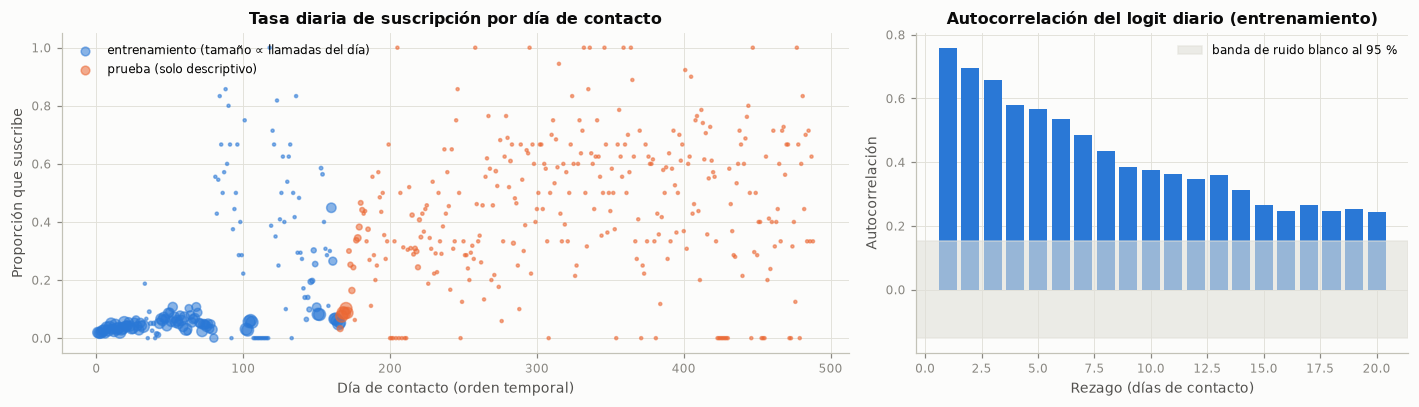

**Interpretación.** En los 166 días de contacto del entrenamiento, la autocorrelación del logit diario es de 0,76 al primer rezago y todavía de 0,57 al quinto y de 0,38 al décimo, muy por encima de la banda de ruido blanco (±0,15). Un puntaje que solo conoce la tasa de los días cerrados, sin ninguna variable del cliente, alcanza un AUC-PR externo medio de 0,103 (semivida de 1 día), frente a 0,103 de la mejor de las 140 combinaciones. Con el nivel suavizado del modelo ajustado al entrenamiento, la proporción de la varianza latente que corresponde al día es de 27,8 %.

Esto quiere decir que la tasa de conversión no es una constante del periodo con ruido alrededor: es un proceso que se mueve con memoria larga, de modo que el día de ayer informa sobre el de hoy. Esa sola estructura, que ningún benchmark modela, vale casi tanto como todo lo que los 140 modelos aprendieron de las variables del cliente; por eso los modelos estáticos se empatan entre sí y por eso la recalibración mensual funcionó. Hay que tener en cuenta que el hallazgo describe asociación temporal, no causa: el nivel resume el contexto de cada día (la lista de clientes llamada, la campaña, la economía), que no está en los datos.

En consecuencia, se decide construir un modelo con dos componentes que se combinan en el logit: un nivel diario latente, que se estima de forma conjunta en el entrenamiento y se actualiza con las etiquetas de los días cerrados, y el efecto de las variables del cliente, que es el que ordena a los clientes de un mismo día. Toda la evidencia de esta sección proviene del entrenamiento y del bucle externo; la prueba se usa una sola vez en la sección 6.

In [8]:
from statsmodels.tsa.stattools import acf

d_tr = pd.DataFrame({"dia": dia_tr, "y": y_tr.to_numpy(), "periodo": periodo_tr.to_numpy()})
g_tr = d_tr.groupby("dia").agg(n=("y", "size"), s=("y", "sum"), periodo=("periodo", "first"))
g_tr["logit"] = np.log((g_tr["s"] + 0.5) / (g_tr["n"] - g_tr["s"] + 0.5))
fac = acf(g_tr["logit"], nlags=20, fft=False)
banda = 1.96 / np.sqrt(len(g_tr))


def puntaje_nivel(semivida):
    """Tasa suavizada de los días anteriores (sin información del cliente), por registro de entrenamiento."""
    a = 1 - 0.5 ** (1 / semivida)
    tasa = (g_tr["s"].ewm(alpha=a).mean() / g_tr["n"].ewm(alpha=a).mean()).shift(1)
    return tasa.reindex(dia_tr).fillna(y_tr.mean()).to_numpy()


filas = []
for sv in (1, 3, 10):
    s_ = puntaje_nivel(sv)
    for k_, (i_e, i_v) in enumerate(cv_externa(GAP).split(X_tr)):
        filas.append({"Puntaje": f"Solo nivel, semivida de {sv} día{'s' if sv > 1 else ''}", "pliegue": k_,
                      "auc_pr": average_precision_score(y_tr.iloc[i_v], s_[i_v])})
solo_nivel = pd.DataFrame(filas).pivot_table(index="Puntaje", columns="pliegue", values="auc_pr", sort=False)
solo_nivel.loc[f"Mejor benchmark: {NOMBRE[MEJOR]}"] = ap_fold[MEJOR].to_numpy()
solo_nivel.columns = [f"Pliegue {c + 1}" for c in range(cfg.K_EXTERNO)]
solo_nivel["Media"] = solo_nivel.mean(axis=1)
tabla(solo_nivel, dec=3)

# Proporción de la variabilidad latente que es diaria, con el nivel suavizado del L2E ajustado al entrenamiento
nivel_tr = L2E["pipeline"][-1].nivel_
icc = np.var(nivel_tr) / (np.var(nivel_tr) + np.pi ** 2 / 3)

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
d_te = pd.DataFrame({"dia": dia_te, "y": yte}).groupby("dia")["y"].agg(["size", "mean"])
axs[0].scatter(g_tr.index, g_tr["s"] / g_tr["n"], s=np.clip(g_tr["n"] / 8, 4, 60), color=AZUL, alpha=0.55,
               label="entrenamiento (tamaño ∝ llamadas del día)")
axs[0].scatter(d_te.index, d_te["mean"], s=np.clip(d_te["size"] / 8, 4, 60), color=NARANJA, alpha=0.55, label="prueba (solo descriptivo)")
axs[0].set(title="Tasa diaria de suscripción por día de contacto", xlabel="Día de contacto (orden temporal)",
           ylabel="Proporción que suscribe")
axs[0].legend(loc="upper left")
axs[1].bar(range(1, 21), fac[1:], color=AZUL)
axs[1].axhspan(-banda, banda, color=REJILLA, alpha=0.6, label="banda de ruido blanco al 95 %")
axs[1].set(title="Autocorrelación del logit diario (entrenamiento)", xlabel="Rezago (días de contacto)",
           ylabel="Autocorrelación")
axs[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

mejor_nivel = solo_nivel.iloc[:3]["Media"].idxmax()
para_guion("solo_nivel", solo_nivel.reset_index())
para_guion("eda", {"dias_tr": len(g_tr), "acf1": fac[1], "acf5": fac[5], "acf10": fac[10], "banda": banda, "icc": icc,
                   "solo_nivel": solo_nivel.loc[mejor_nivel, "Media"], "mejor_140": solo_nivel.iloc[-1]["Media"],
                   "n_tr": len(X_tr), "n_te": len(X_te), "prev_tr": y_tr.mean(), "prev_te": y_te.mean(),
                   "desde_tr": periodo_tr.iloc[0], "hasta_tr": periodo_tr.iloc[-1], "desde_te": periodo_te.iloc[0],
                   "hasta_te": periodo_te.iloc[-1], "dias_te": n_dias_te, "gap": GAP})
interpretar(
    f"En los {len(g_tr)} días de contacto del entrenamiento, la autocorrelación del logit diario es de "
    f"{num(fac[1], 2)} al primer rezago y todavía de {num(fac[5], 2)} al quinto y de {num(fac[10], 2)} al décimo, "
    f"muy por encima de la banda de ruido blanco (±{num(banda, 2)}). Un puntaje que solo conoce la tasa de los días "
    f"cerrados, sin ninguna variable del cliente, alcanza un AUC-PR externo medio de "
    f"{num(solo_nivel.loc[mejor_nivel, 'Media'], 3)} ({mejor_nivel.split(', ')[1]}), frente a "
    f"{num(solo_nivel.iloc[-1]['Media'], 3)} de la mejor de las 140 combinaciones. Con el nivel suavizado del modelo "
    f"ajustado al entrenamiento, la proporción de la varianza latente que corresponde al día es de {pct(icc)}.",
    conectar("Esto quiere decir que", "La tasa de conversión no es una constante del periodo con ruido alrededor: es un "
             "proceso que se mueve con memoria larga, de modo que el día de ayer informa sobre el de hoy. Esa sola "
             "estructura, que ningún benchmark modela, vale casi tanto como todo lo que los 140 modelos aprendieron de "
             "las variables del cliente; por eso los modelos estáticos se empatan entre sí y por eso la recalibración "
             "mensual funcionó. Hay que tener en cuenta que el hallazgo describe asociación temporal, no causa: el nivel "
             "resume el contexto de cada día (la lista de clientes llamada, la campaña, la economía), que no está en "
             "los datos."),
    conectar("En consecuencia, se decide", "Construir un modelo con dos componentes que se combinan en el logit: un "
             "nivel diario latente, que se estima de forma conjunta en el entrenamiento y se actualiza con las "
             "etiquetas de los días cerrados, y el efecto de las variables del cliente, que es el que ordena a los "
             "clientes de un mismo día. Toda la evidencia de esta sección proviene del entrenamiento y del bucle "
             "externo; la prueba se usa una sola vez en la sección 6."))

## 3. Modelos benchmark

### 3.1 Mejores combinaciones por modelo y mejor combinación global

Del universo de 140 combinaciones del tercer entregable, el criterio de la guía (sección 4.1) es estadístico y no visual: para cada uno de los 7 modelos base se toma la combinación de balanceo y optimizador con la mayor **métrica media del bucle externo** (AUC-PR), y la mejor de ellas es la mejor combinación global. Estos siete finalistas, más el modelo base del Entregable 2 como referencia, son los *benchmarks* del modelo original; están serializados con su `metadata.json` y su prueba de ida y vuelta en `artifacts/` del repositorio del dashboard, que es el que los carga en producción.

In [9]:
filas = []
for r_ in fin_ext.itertuples():
    pl_ = pl_fin[pl_fin["modelo"] == r_.modelo]
    filas.append({"Modelo": cfg.NOMBRE_MODELO[r_.modelo], "Balanceo": cfg.NOMBRE_BALANCEO[r_.balanceo],
                  "Optimizador": cfg.NOMBRE_OPTIMIZADOR[r_.optimizador], "AUC-PR externo": ms(pl_["auc_pr"]),
                  "AUC externo": ms(pl_["auc"]), "Ajuste medio (s)": r_.t_fit_medio,
                  "Inferencia media (s)": r_.t_pred_medio})
benchmarks = pd.DataFrame(filas)
tabla(benchmarks, dec=3, indice=False)

# Pertenencia de la mejor combinación global al conjunto de finalistas de Friedman → Nemenyi del E3
mat_fin = pl_fin.pivot_table(index="pliegue", columns="modelo", values="auc_pr")[MODELOS]
fr_e3 = st.friedman(mat_fin)
nem_e3 = sp.posthoc_nemenyi_friedman(mat_fin.to_numpy())
nem_e3.index = nem_e3.columns = MODELOS
cd_e3 = st.diferencia_critica(len(MODELOS), len(mat_fin))
interpretar(
    f"La mejor combinación global es {NOMBRE[MEJOR]}, con un AUC-PR externo de "
    f"{benchmarks.iloc[0]['AUC-PR externo']}; la última de los siete finalistas, {NOMBRE[MODELOS[-1]]}, obtiene "
    f"{benchmarks.iloc[-1]['AUC-PR externo']}. Entre los finalistas, Friedman da χ² = {num(fr_e3['chi2'], 2)} "
    f"({p_txt(fr_e3['p'])}) y la menor p de Nemenyi frente a la mejor combinación es de "
    f"{num(nem_e3.loc[MEJOR].drop(MEJOR).min(), 3)}, con una diferencia crítica de {num(cd_e3, 2)} rangos.",
    conectar("Así mismo,", "La mejor combinación global pertenece al conjunto de modelos estadísticamente equivalentes: "
             "ninguno de los siete se separa de los demás y las desviaciones estándar entre pliegues son del mismo orden "
             "que las medias, porque un solo pliegue concentra la señal (sección 1.1). Superar a estos benchmarks no "
             "exige un clasificador más flexible, sino capturar la estructura que todos dejan sin modelar."),
    conectar("Por ello, se recomienda", "Comparar el modelo original contra los siete finalistas y contra la "
             "referencia del Entregable 2, con la mejor combinación global como contraste principal, tal como define "
             "la guía la condición R3 (sección 6.1), y sin descartar a ninguno de la comparación global de la "
             "sección 6.3."))

Modelo,Balanceo,Optimizador,AUC-PR externo,AUC externo,Ajuste medio (s),Inferencia media (s)
Naive Bayes,class_weight,Bayesiana (Optuna TPE),"0,103 ± 0,108","0,537 ± 0,102","0,662","0,342"
Logística L1/L2,SMOTE,Random Search,"0,096 ± 0,096","0,521 ± 0,083","2,963","0,278"
Random Forest,Sin balanceo,Bayesiana (Optuna TPE),"0,095 ± 0,092","0,538 ± 0,079","9,144","0,769"
SVM,class_weight,Grid Search,"0,092 ± 0,091","0,512 ± 0,098","4,623","0,835"
XGBoost,class_weight,Genético (DEAP),"0,091 ± 0,077","0,525 ± 0,054","2,826","0,406"
Árbol de decisión,SMOTE,Bayesiana (Optuna TPE),"0,086 ± 0,073","0,530 ± 0,073","1,186","0,256"
KNN,class_weight,Grid Search,"0,084 ± 0,067","0,517 ± 0,067","0,515","5,896"


**Interpretación.** La mejor combinación global es Naive Bayes · class_weight · Bayesiana (Optuna TPE), con un AUC-PR externo de 0,103 ± 0,108; la última de los siete finalistas, KNN · class_weight · Grid Search, obtiene 0,084 ± 0,067. Entre los finalistas, Friedman da χ² = 3,17 (p = 0,787) y la menor p de Nemenyi frente a la mejor combinación es de 0,905, con una diferencia crítica de 4,03 rangos.

Así mismo, la mejor combinación global pertenece al conjunto de modelos estadísticamente equivalentes: ninguno de los siete se separa de los demás y las desviaciones estándar entre pliegues son del mismo orden que las medias, porque un solo pliegue concentra la señal (sección 1.1). Superar a estos benchmarks no exige un clasificador más flexible, sino capturar la estructura que todos dejan sin modelar.

Por ello, se recomienda comparar el modelo original contra los siete finalistas y contra la referencia del Entregable 2, con la mejor combinación global como contraste principal, tal como define la guía la condición R3 (sección 6.1), y sin descartar a ninguno de la comparación global de la sección 6.3.

## 4. Revisión de literatura y novedad

La guía es explícita: la novedad no se declara, se demuestra con una revisión documentada. Esta sección sigue su protocolo (sección 5.2) con tres decisiones de diseño: las cadenas combinan la familia del modelo, el problema de aplicación y sinónimos en inglés y español; se agregan dos **cadenas de control** (solo la aplicación y solo la familia del modelo) que verifican que la sintaxis devuelve resultados y dimensionan cada literatura, de modo que un cero en las intersecciones no se confunda con una consulta mal escrita; y todo queda registrado por `scripts/revision_literatura.py` en `resultados/literatura/consultas.json`, con la fecha de cada consulta y los registros revisados, para que la revisión sea reproducible.

### 4.1 Protocolo

- **Bases consultadas:** OpenAlex (más de 250 millones de trabajos; búsqueda booleana en título y resumen), arXiv (preimpresiones de estadística y *machine learning*; búsqueda booleana en todos los campos), Crossref (registro de DOI de las editoriales; búsqueda por relevancia, sin operadores booleanos) y Semantic Scholar (búsqueda por relevancia en título y resumen). Scopus y Web of Science requieren acceso institucional y no tienen API pública; la misma lista de cadenas puede repetirse en ellas desde la biblioteca de la universidad.
- **Cadenas:** 2 de control y 8 de intersección (familia × aplicación), de las cuales una está en español.
- **Revisión:** se leen los primeros 25 registros de cada consulta (todos, si son menos). El tamizaje automático marca como **candidato** un registro cuyo título o resumen menciona a la vez el problema (telemercadeo bancario, depósito a término) y un mecanismo temporal (estado latente, Kalman, logística dinámica, deriva, cambio de prevalencia, flujo de datos, etiquetas diferidas); cada candidato se lee completo y se clasifica a mano como **relevante** si aplica un modelo de la misma familia al mismo problema.
- **Criterio de exclusión de la novedad:** existiría un antecedente si un trabajo aplicara a la predicción de la suscripción en telemercadeo bancario un modelo logístico con estado latente dinámico (intercepto o coeficientes que evolucionan en el tiempo y se actualizan con etiquetas nuevas).

### 4.2 Matriz de novedad

In [10]:
# Clasificación manual de los candidatos del tamizaje, tras leer título, resumen y, cuando existe, el texto completo
CLASIFICACION = {
    "https://doi.org/10.1109/icscsa66339.2025.11170856": (
        True, "Chowdary et al. (2025): Gradient Boosting, Random Forest y XGBoost con SMOTE/ADASYN y actualización "
              "incremental sobre Bank Marketing; no modela un estado latente ni etiquetas diferidas"),
}
filas, candidatos = [], {}
for q in literatura:
    regs = q["registros"]
    rel = [CLASIFICACION.get(r["doi"], (False, ""))[0] for r in regs if r["candidato"]]
    for r in regs:
        if r["candidato"]:
            candidatos.setdefault(r["doi"] or r["titulo"], {**r, "base": q["base"]})
    if q["error"]:
        obs = "Consulta fallida: " + q["error"][:60]
    elif q.get("control"):
        obs = "Cadena de control: la sintaxis devuelve resultados"
    elif q["base"] in ("Crossref", "Semantic Scholar"):
        obs = "Búsqueda por relevancia: el total no filtra la intersección"
    elif q["resultados"] == 0:
        obs = "Sin resultados para la intersección"
    else:
        obs = "Ver candidatos"
    filas.append({"Base": q["base"], "Tipo": "Control" if q.get("control") else "Intersección",
                  "Cadena de búsqueda": q["cadena"], "Fecha (UTC)": q["fecha_utc"][:10],
                  "Result.": q["resultados"], "Revis.": q["revisados"], "Cand.": q["candidatos"], "Relev.": sum(rel),
                  "Observación": obs})
matriz = pd.DataFrame(filas)
tabla(matriz, dec=0, indice=False)

cand = pd.DataFrame([{"Base": c["base"], "Año": c["anio"], "Título": c["titulo"], "DOI o enlace": k,
                      "Relevante": "sí" if CLASIFICACION.get(k, (False,))[0] else "no",
                      "Clasificación": CLASIFICACION.get(k, (False, "Revisado: no aplica un modelo de estado latente "
                                                                    "al problema"))[1]} for k, c in candidatos.items()])
if len(cand):
    tabla(cand, indice=False)

inter = matriz[matriz["Tipo"] == "Intersección"]
bool_ = inter[inter["Base"].isin(["OpenAlex", "arXiv"]) & inter["Result."].notna()]
ctrl = matriz[(matriz["Tipo"] == "Control") & matriz["Base"].isin(["OpenAlex", "arXiv"])]
n_rev = int(matriz["Revis."].sum())
para_guion("literatura", {"consultas": len(matriz), "bases": int(matriz["Base"].nunique()), "revisados": n_rev,
                          "candidatos": int(len(cand)), "relevantes": int((cand["Relevante"] == "sí").sum()) if len(cand) else 0,
                          "fallidas": int(matriz["Observación"].str.startswith("Consulta fallida").sum())})
n_fallidas = int(matriz["Observación"].str.startswith("Consulta fallida").sum())
interpretar(
    f"Se hicieron {len(matriz)} consultas en {matriz['Base'].nunique()} bases ({n_fallidas} fallidas) y se revisaron "
    f"{num(n_rev)} registros. Las cadenas de control devuelven resultados en las bases booleanas (entre "
    f"{num(ctrl['Result.'].min())} y {num(ctrl['Result.'].max())} trabajos), mientras que las "
    f"{len(bool_)} intersecciones en OpenAlex y arXiv suman {num(bool_['Result.'].sum())} "
    f"resultado{'' if bool_['Result.'].sum() == 1 else 's'}. El tamizaje "
    f"marcó {len(cand)} candidato{'s' if len(cand) != 1 else ''} único{'s' if len(cand) != 1 else ''}, de los "
    f"cuales {int((cand['Relevante'] == 'sí').sum()) if len(cand) else 0} trata el mismo problema con un mecanismo "
    "temporal.",
    conectar("Lo anterior indica que", "Cada componente tiene su propia literatura (hay trabajos sobre telemercadeo "
             "bancario y sobre regresión logística dinámica), pero su intersección está prácticamente vacía. El único "
             "antecedente cercano en la aplicación adapta ensambles de árboles de forma incremental, que es una familia "
             "algorítmica distinta: no estima un nivel latente, no separa escalas de tiempo ni trata la demora de las "
             "etiquetas. Las búsquedas por relevancia (Crossref y Semantic Scholar) no permiten intersecciones "
             "booleanas, así que su aporte es la lectura de sus primeros registros, no el conteo."),
    conectar("Por tanto, corresponde", "Delimitar la novedad con precisión: no se reclama haber inventado los modelos "
             "de espacio de estados, sino una configuración algorítmica concreta (dos escalas, ajuste por bloques y "
             "filtro con etiquetas diferidas) y su primera aplicación a este problema, y diferenciarla de cada método "
             "afín en la sección 4.3."))

Base,Tipo,Cadena de búsqueda,Fecha (UTC),Result.,Revis.,Cand.,Relev.,Observación
OpenAlex,Control,"""bank telemarketing"" OR (""bank marketing"" AND ""term deposit"")",2026-10-24,141,25,0,0,Cadena de control: la sintaxis devuelve resultados
OpenAlex,Control,"""dynamic logistic regression"" OR (""state space"" AND ""logistic regression"" AND ""time-varying"")",2026-10-24,56,25,0,0,Cadena de control: la sintaxis devuelve resultados
OpenAlex,Intersección,"""bank telemarketing"" AND (""state space"" OR ""Kalman"")",2026-10-24,0,0,0,0,Sin resultados para la intersección
OpenAlex,Intersección,"""bank marketing"" AND ""dynamic logistic regression""",2026-10-24,0,0,0,0,Sin resultados para la intersección
OpenAlex,Intersección,"""term deposit"" AND (""concept drift"" OR ""prior shift"" OR ""label shift"")",2026-10-24,0,0,0,0,Sin resultados para la intersección
OpenAlex,Intersección,"""bank telemarketing"" AND (""time-varying"" OR ""random walk"") AND logistic",2026-10-24,0,0,0,0,Sin resultados para la intersección
OpenAlex,Intersección,"""bank marketing"" AND (""online learning"" OR ""delayed labels"" OR ""data stream"")",2026-10-24,1,1,1,1,Ver candidatos
OpenAlex,Intersección,"(""telemercadeo"" OR ""telemarketing"") AND (""depósito a plazo"" OR ""depósito a término"") AND (""Kalman"" OR ""modelo dinámico"")",2026-10-24,0,0,0,0,Sin resultados para la intersección
OpenAlex,Intersección,"""direct marketing"" AND ""dynamic logistic regression""",2026-10-24,0,0,0,0,Sin resultados para la intersección
OpenAlex,Intersección,"""dynamic logistic regression"" AND (""delayed labels"" OR ""label delay"" OR ""verification latency"")",2026-10-24,0,0,0,0,Sin resultados para la intersección


Base,Año,Título,DOI o enlace,Relevante,Clasificación
OpenAlex,2 025,Advancing Telemarketing Success using Ensemble-Driven Online Machine Learning,https://doi.org/10.1109/icscsa66339.2025.11170856,sí,"Chowdary et al. (2025): Gradient Boosting, Random Forest y XGBoost con SMOTE/ADASYN y actualización incremental sobre Bank Marketing; no modela un estado latente ni etiquetas diferidas"


**Interpretación.** Se hicieron 40 consultas en 4 bases (6 fallidas) y se revisaron 382 registros. Las cadenas de control devuelven resultados en las bases booleanas (entre 3 y 141 trabajos), mientras que las 16 intersecciones en OpenAlex y arXiv suman 1 resultado. El tamizaje marcó 1 candidato único, de los cuales 1 trata el mismo problema con un mecanismo temporal.

Lo anterior indica que cada componente tiene su propia literatura (hay trabajos sobre telemercadeo bancario y sobre regresión logística dinámica), pero su intersección está prácticamente vacía. El único antecedente cercano en la aplicación adapta ensambles de árboles de forma incremental, que es una familia algorítmica distinta: no estima un nivel latente, no separa escalas de tiempo ni trata la demora de las etiquetas. Las búsquedas por relevancia (Crossref y Semantic Scholar) no permiten intersecciones booleanas, así que su aporte es la lectura de sus primeros registros, no el conteo.

Por tanto, corresponde delimitar la novedad con precisión: no se reclama haber inventado los modelos de espacio de estados, sino una configuración algorítmica concreta (dos escalas, ajuste por bloques y filtro con etiquetas diferidas) y su primera aplicación a este problema, y diferenciarla de cada método afín en la sección 4.3.

### 4.3 Trabajos cercanos por familia algorítmica

La guía pide diferenciar la propuesta de métodos afines por familia, no solo por aplicación. La tabla compara el L2E con diez trabajos: dos de la misma aplicación y ocho de la misma familia (modelos lineales generalizados dinámicos, corrección del cambio de prevalencia y aprendizaje con deriva o etiquetas diferidas). Todas las referencias se verificaron por DOI o en sus actas (`scripts/verificar_referencias.py`).

| Trabajo | Familia | Qué conserva el L2E | Qué es nuevo en el L2E o qué limitación no resuelve el trabajo |
|---|---|---|---|
| Moro, Cortez y Rita (2014) | Modelos estáticos (red neuronal, SVM, árbol, logística) con ventana móvil, sobre telemercadeo bancario | El problema, las variables de contexto y la evaluación en orden temporal | La ventana móvil reajusta el modelo cada cierto tiempo y descarta el pasado; no estima el nivel de conversión ni lo actualiza día a día con etiquetas |
| Chowdary et al. (2025) | Ensambles de árboles con SMOTE y actualización incremental, sobre Bank Marketing | El uso de etiquetas nuevas para actualizar el modelo | Familia distinta (árboles, sin estado latente); no separa nivel y pendientes, no trata la demora de las etiquetas y su exactitud del 98 % sugiere el uso de `duration`, que aquí se excluye por fuga |
| West, Harrison y Migon (1985) | Modelos lineales generalizados dinámicos bayesianos | La idea de un estado que evoluciona y se actualiza con cada observación | Actualización conjugada aproximada observación por observación; el L2E usa Laplace por lote diario, dos escalas y un ajuste inicial por moda posterior |
| Fahrmeir (1992) | Moda posterior de MLG dinámicos con filtro de Kalman extendido | La estimación por moda posterior penalizada | Todos los coeficientes son dinámicos y el suavizado es O(T·p³); el L2E fija las pendientes en el ajuste y elimina el nivel con el complemento de Schur en O(T·p²) |
| McCormick et al. (2012) | Regresión logística dinámica con factor de olvido, una sola escala | El filtro de Laplace sobre los coeficientes de una logística | Una sola tasa de olvido para todos los coeficientes y etiquetas inmediatas; el L2E separa el nivel (rápido) de las pendientes (lentas), y la ablación de la sección 5.9 mide el costo de usar una sola escala |
| Kalman (1960); Durbin y Koopman (2012) | Filtrado y suavizado en espacio de estados | La recursión predicción-actualización | Formulados para observaciones gaussianas; el L2E trata observaciones de Bernoulli con aproximación de Laplace y probabilidad predictiva integrada (MacKay, 1992) |
| Saerens, Latinne y Decaestecker (2002) | Corrección del cambio de prevalencia sin etiquetas (EM) | La corrección del intercepto ante un cambio de la tasa base | Supone que p(x \| y) no cambia y no usa etiquetas; el L2E usa las etiquetas diferidas y además adapta las pendientes (deriva de concepto, sección 3.6.5 del tercer entregable) |
| Lipton, Wang y Smola (2018); Garg et al. (2020) | Estimación del cambio de prevalencia (BBSE, MLLS) | El enfoque de corregir la prevalencia del lote | Estiman una prevalencia fija por lote sin etiquetas; no hay dinámica entre lotes ni actualización de pendientes. MLLS se incluye como control en la sección 6.8 |
| Gama et al. (2014) | Adaptación a la deriva de concepto (ventanas, olvido, detectores) | La necesidad de olvidar el pasado de forma controlada | Las ventanas y los detectores son heurísticos; en el L2E el olvido sale de un modelo probabilístico, cuyas varianzas q_u y q_β se optimizan en la validación anidada |
| Grzenda, Gomes y Bifet (2020) | Evaluación con etiquetas diferidas en flujos de datos | El protocolo precuencial con demora de etiquetas | Es un protocolo de evaluación, no un modelo; el L2E lo incorpora en su regla de predicción (`retardo`) y en su prueba de ausencia de fuga |
| Recalibración mensual del intercepto (entregables 2 y 3) | Desplazamiento del logit para igualar la tasa del mes cerrado | La corrección del intercepto con datos recientes que sugirió el docente | Es el caso límite del filtro del L2E con varianza a priori infinita, lote mensual y retardo de un mes (propiedad P5, sección 5.4) |

In [11]:
n_bases = matriz.loc[~matriz["Observación"].str.startswith("Consulta fallida"), "Base"].nunique()
n_cadenas = len(matriz) // matriz["Base"].nunique()
MESES_ES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre",
            "noviembre", "diciembre"]
_f = pd.Timestamp(matriz["Fecha (UTC)"].max())
fecha_rev = f"{_f.day} de {MESES_ES[_f.month - 1]} de {_f.year} (UTC)"
display(Markdown(f"""### 4.4 Declaración de novedad

Al mejor de nuestro conocimiento y según la búsqueda descrita ({n_bases} bases bibliográficas, {len(matriz)} consultas con {n_cadenas} cadenas en inglés y español, consulta del {fecha_rev}), **no se encontraron estudios que apliquen a la predicción de la suscripción a depósitos a término en campañas de telemercadeo bancario una regresión logística de estado latente con un nivel diario en paseo aleatorio, pendientes de deriva lenta y un filtro de Laplace con etiquetas diferidas**. Los trabajos más cercanos son, en la aplicación, Moro, Cortez y Rita (2014), que usan modelos estáticos con ventana móvil, y Chowdary et al. (2025), que actualizan ensambles de árboles de forma incremental; y, en la familia del modelo, McCormick et al. (2012), cuya regresión logística dinámica usa una sola escala de olvido y etiquetas inmediatas, y Fahrmeir (1992), cuya moda posterior trata todos los coeficientes como dinámicos sin la eliminación por bloques del nivel. La propuesta se diferencia de cada uno en la separación del nivel y las pendientes en dos escalas de tiempo, en el ajuste por bloques en O(T) y en la regla de predicción con etiquetas diferidas, cuya contribución medible se verifica con la ablación de la sección 5.9."""))

### 4.4 Declaración de novedad

Al mejor de nuestro conocimiento y según la búsqueda descrita (4 bases bibliográficas, 40 consultas con 10 cadenas en inglés y español, consulta del 24 de octubre de 2026 (UTC)), **no se encontraron estudios que apliquen a la predicción de la suscripción a depósitos a término en campañas de telemercadeo bancario una regresión logística de estado latente con un nivel diario en paseo aleatorio, pendientes de deriva lenta y un filtro de Laplace con etiquetas diferidas**. Los trabajos más cercanos son, en la aplicación, Moro, Cortez y Rita (2014), que usan modelos estáticos con ventana móvil, y Chowdary et al. (2025), que actualizan ensambles de árboles de forma incremental; y, en la familia del modelo, McCormick et al. (2012), cuya regresión logística dinámica usa una sola escala de olvido y etiquetas inmediatas, y Fahrmeir (1992), cuya moda posterior trata todos los coeficientes como dinámicos sin la eliminación por bloques del nivel. La propuesta se diferencia de cada uno en la separación del nivel y las pendientes en dos escalas de tiempo, en el ajuste por bloques en O(T) y en la regla de predicción con etiquetas diferidas, cuya contribución medible se verifica con la ablación de la sección 5.9.

## 5. Modelo original: logística de estado latente en dos escalas (L2E)

### 5.1 Motivación y decisiones de diseño

El diagnóstico de las secciones 1 y 2 deja tres hechos, y cada uno se traduce en una decisión de diseño:

1. **El nivel de conversión de cada día es un proceso persistente** (autocorrelación del logit diario de la sección 2.2). Entonces, el intercepto del modelo debe ser un estado latente que evoluciona entre días y que se estima de forma conjunta con el efecto de las variables, en lugar de un número fijo para todo el periodo (componente **C1**), y que en producción se actualiza con las etiquetas de cada día cerrado (componente **C2**).
2. **La relación de varias variables con la suscripción cambia entre 2008 y 2009** (deriva de concepto en `job`, `education`, `default`, `day_of_week`, `marital` y `age`; sección 3.6.5 del tercer entregable), pero mucho más despacio que el nivel. Así mismo, las pendientes deben poder derivar, en una escala de tiempo más lenta que la del nivel (componente **C3**). Separar las dos escalas es lo que distingue la propuesta de una logística dinámica de una sola tasa de olvido.
3. **Las etiquetas llegan por días y con demora.** El resultado de una llamada se conoce al cerrar la jornada, y para predecir el día *d* solo están disponibles las etiquetas de los días anteriores. En ese sentido, la regla de predicción debe respetar esa demora por construcción, y como el nivel de un día nuevo es incierto, la probabilidad predictiva debe integrar esa incertidumbre (componente **C4**).

El modelo resultante no usa ninguna variable nueva: recibe exactamente las mismas predictoras preprocesadas que los benchmarks, más el identificador del día de contacto que ya se reconstruía en el tercer entregable para la validación cronológica.

### 5.2 Formulación matemática

**Modelo de observación.** Para el registro $i$, contactado el día $t(i)$ y con predictoras preprocesadas $x_i \in \mathbb{R}^p$,

$$P(y_i = 1 \mid \theta_{t(i)}) = \sigma\!\left(u_{t(i)} + x_i^\top \beta_{t(i)}\right), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}, \qquad \theta_t = (u_t, \beta_t). \tag{1}$$

**Dinámica en dos escalas.** Si $t'$ es el día de contacto anterior y $\Delta_t = t - t'$ el número de días transcurridos,

$$u_t = u_{t'} + \varepsilon_t,\quad \varepsilon_t \sim \mathcal{N}(0,\, q_u \Delta_t); \qquad \beta_t = \beta_{t'} + \nu_t,\quad \nu_t \sim \mathcal{N}(0,\, q_\beta \Delta_t I_p); \qquad \beta \sim \mathcal{N}(0,\, \lambda^{-1} I_p), \tag{2}$$

con $q_\beta \ll q_u$: el nivel de conversión se mueve de un día a otro (escala rápida) y las pendientes cambian a lo largo de meses (escala lenta). $\lambda$, $q_u$ y $q_\beta$ son los tres hiperparámetros del modelo.

**Fase 1: ajuste por moda posterior.** Dentro de la ventana de entrenamiento, con días $1, \dots, T$, las pendientes se toman constantes (aproximación de dos escalas) y se maximiza la log-posterior penalizada

$$J(u, \beta) = \sum_{i=1}^{n} \left[ y_i \eta_i - \log\!\left(1 + e^{\eta_i}\right) \right] - \sum_{k=2}^{T} \frac{(u_k - u_{k-1})^2}{2 q_u \Delta_k} - \frac{\epsilon}{2}\lVert u \rVert^2 - \frac{\lambda}{2} \lVert \beta \rVert^2, \qquad \eta_i = u_{t(i)} + x_i^\top \beta, \tag{3}$$

donde $\epsilon = 10^{-6}$ es una precisión difusa sobre el nivel. Con $\pi_i = \sigma(\eta_i)$ y $w_i = \pi_i (1 - \pi_i)$, el gradiente es $g_u = \left(\sum_{i : t(i) = t} (y_i - \pi_i)\right)_t - (D + \epsilon I) u$ y $g_\beta = X^\top (y - \pi) - \lambda \beta$, y el Hessiano negativo tiene la estructura por bloques

$$H = \begin{pmatrix} A & B \\ B^\top & C \end{pmatrix}, \qquad A = \operatorname{diag}(W_t) + D + \epsilon I, \quad B_{t\cdot} = \sum_{i : t(i) = t} w_i x_i^\top, \quad C = X^\top W X + \lambda I, \tag{4}$$

donde $W_t = \sum_{i : t(i) = t} w_i$ y $D = L^\top \operatorname{diag}\!\left(1/(q_u \Delta_k)\right) L$, con $L$ la matriz de primeras diferencias: $A$ es **tridiagonal**. El paso de Newton se obtiene eliminando el nivel con el complemento de Schur,

$$S = C - B^\top A^{-1} B, \qquad \delta_\beta = S^{-1}\left(g_\beta - B^\top A^{-1} g_u\right), \qquad \delta_u = A^{-1}\left(g_u - B \delta_\beta\right), \tag{5}$$

y $A^{-1}$ solo se aplica a vectores mediante una resolución tridiagonal. Al converger, la aproximación de Laplace da la media y la covarianza del estado al cierre del entrenamiento, sin invertir $H$ completo: con $v = A^{-1} e_T$,

$$\operatorname{Cov}(\beta) = S^{-1}, \qquad \operatorname{Cov}(u_T, \beta) = -v^\top B\, S^{-1}, \qquad \operatorname{Var}(u_T) = v_T + v^\top B\, S^{-1} B^\top v. \tag{6}$$

**Fase 2: filtrado con etiquetas diferidas.** Sea $z_i = (1, x_i)$ y $(m, P)$ la media y la covarianza vigentes del estado. Para un día nuevo $d$, la predicción del estado es

$$m^- = m, \qquad P^- = P + \Delta_d \operatorname{diag}(q_u, q_\beta, \dots, q_\beta). \tag{7}$$

Cuando se cierran las etiquetas del día $d'$ (solo si $d' \le d - L$, con $L$ el retardo), el estado se actualiza con la moda de la posterior de ese día y su curvatura (aproximación de Laplace):

$$\theta^+ = \arg\max_\theta \sum_{i : t(i) = d'} \left[ y_i z_i^\top \theta - \log\!\left(1 + e^{z_i^\top \theta}\right) \right] - \tfrac{1}{2} (\theta - m^-)^\top (P^-)^{-1} (\theta - m^-), \qquad P^+ = \left( \sum_{i : t(i) = d'} w_i z_i z_i^\top + (P^-)^{-1} \right)^{-1}. \tag{8}$$

**Probabilidad predictiva.** Integrando la incertidumbre del estado con la aproximación probit (MacKay, 1992),

$$\hat p_i = \sigma\!\left( \frac{\mu_i}{\sqrt{1 + \pi s_i^2 / 8}} \right), \qquad \mu_i = z_i^\top m^-, \qquad s_i^2 = z_i^\top P^- z_i. \tag{9}$$

### 5.3 Pseudocódigo

```text
Algoritmo 1. Ajuste por moda posterior (fit)
Entradas : X ∈ R^{n×p}, días t ∈ Z^n (no decrecientes), y ∈ {0,1}^n, hiperparámetros λ > 0, q_u > 0
Salidas  : nivel suavizado û_1..û_T, pendientes β̂, estado (m, P) de (u_T, β) al cierre del entrenamiento
 1. Días únicos d_1 < … < d_T; índice τ(i) ∈ {1..T}; Δ_k = d_k − d_{k−1}
 2. u ← logit(ȳ)·1_T ;  β ← 0_p
 3. repetir para iter = 1..max_iter
 4.     η_i ← u_{τ(i)} + x_iᵀβ ;  π_i ← σ(η_i) ;  w_i ← π_i(1 − π_i)
 5.     g_u, g_β ← gradientes de la ecuación (3)
 6.     A ← diag(W_t) + D + εI (tridiagonal) ;  B ← Σ_i w_i e_{τ(i)} x_iᵀ ;  C ← XᵀWX + λI
 7.     resolver A [Ã_B, ã_g] = [B, g_u] (tridiagonal, p + 1 lados derechos)
 8.     S ← C − Bᵀ Ã_B ;  δ_β ← S⁻¹ (g_β − Bᵀ ã_g) (Cholesky) ;  δ_u ← ã_g − Ã_B δ_β
 9.     λ²_N ← g_uᵀδ_u + g_βᵀδ_β                               (decremento de Newton)
10.     si λ²_N / 2 ≤ tol: terminar (convergencia)
11.     s ← 1 ; mientras J(u + sδ_u, β + sδ_β) < J(u, β) + 0,25·s·λ²_N : s ← s/2   (Armijo)
12.     u ← u + sδ_u ;  β ← β + sδ_β
13. m ← (u_T, β) ;  P ← covarianza de Laplace de la ecuación (6)

Algoritmo 2. Predicción precuencial con etiquetas diferidas (predict_proba_secuencial)
Entradas : estado (m, P) y último día asimilado t*, registros nuevos (X, días, y), retardo L ≥ 1, q_u, q_β
Salidas  : probabilidad p̂_i para cada registro; el estado del estimador no se modifica
 1. pendientes ← cola vacía
 2. para cada día d de los registros, en orden cronológico
 3.     mientras pendientes ≠ ∅ y primero(pendientes) ≤ d − L          (solo días ya cerrados)
 4.         d' ← extraer(pendientes) ;  P⁻ ← P + (d' − t*)·diag(q_u, q_β, …, q_β)
 5.         (m, P) ← moda y curvatura de la ecuación (8) (Newton en 1 + p dimensiones) ;  t* ← d'
 6.     P_d ← P + (d − t*)·diag(q_u, q_β, …, q_β)
 7.     p̂_i ← σ(μ_i / sqrt(1 + π s²_i / 8)) para los registros del día d   (ecuación 9)
 8.     agregar d a pendientes
Criterio de parada: el algoritmo termina al recorrer el último día; cada actualización (paso 5) termina
cuando el paso de Newton es menor que 1e−10 en norma infinito (a lo sumo 50 iteraciones).
```

### 5.4 Propiedades teóricas

**P1. Existencia y unicidad del ajuste.** El objetivo (3) es estrictamente cóncavo y tiene un único maximizador. *Demostración.* La log-verosimilitud de Bernoulli es cóncava en $\eta$ y $\eta$ es lineal en $(u, \beta)$, así que su Hessiano es $-Z^\top W Z \preceq 0$. Las penalizaciones aportan $-\operatorname{blockdiag}(D + \epsilon I,\ \lambda I)$, con $D \succeq 0$ y $\epsilon, \lambda > 0$, que es definida negativa. La suma es definida negativa en todo punto, luego $J$ es estrictamente cóncava. Además $J \le -\tfrac{\epsilon}{2}\lVert u \rVert^2 - \tfrac{\lambda}{2}\lVert \beta \rVert^2$, porque la log-verosimilitud es no positiva, así que $J \to -\infty$ cuando $\lVert (u, \beta) \rVert \to \infty$ (coercividad) y el máximo existe; por la concavidad estricta es único. $\blacksquare$

**P2. Convergencia del ajuste.** $J$ es dos veces continuamente diferenciable, fuertemente cóncava (módulo $\ge \min(\epsilon, \lambda)$) y su Hessiano es Lipschitz en el conjunto de nivel inicial, porque $\sigma''$ es acotada. Bajo esas condiciones, Newton con búsqueda lineal de retroceso (Armijo) converge globalmente al maximizador y, cerca de él, con orden cuadrático (Boyd y Vandenberghe, 2004, sección 9.5.3). El criterio de parada usa el decremento de Newton $\lambda_N^2 = g^\top H^{-1} g$, cuyo valor $\lambda_N^2/2$ estima la distancia al óptimo $J^\star - J$ (ecuación 9.29 de la misma obra). Por construcción, la secuencia $J^{(k)}$ es no decreciente; la prueba unitaria `test_objetivo_no_decrece_y_converge` y la sección 5.8 lo verifican.

**P3. Complejidad.** En cada iteración de la fase 1, formar $X^\top W X$ cuesta $O(np^2)$; $B$, $O(np)$; la resolución tridiagonal de $A$ con $p + 1$ lados derechos, $O(Tp)$; el producto $B^\top A^{-1} B$, $O(Tp^2)$, y la factorización de Cholesky de $S$, $O(p^3)$. El costo total es $O(I \cdot (np^2 + Tp^2 + p^3))$ en tiempo y $O(np + Tp)$ en memoria, con $I$ iteraciones de Newton (entre 5 y 10 en la práctica), frente a $O(I \cdot (T + p)^3)$ y $O((T + p)^2)$ de resolver el sistema completo. En la fase 2, cada día con $n_d$ registros cuesta $O(k_d (n_d p^2 + p^3))$, con $k_d$ iteraciones de Newton, de modo que predecir $n$ registros en $D$ días cuesta $O(np^2 + Dp^3)$: lineal en el número de registros.

**P4. Unicidad de cada actualización diaria.** El objetivo de la ecuación (8) es la suma de una log-verosimilitud cóncava y de $-\tfrac{1}{2}(\theta - m^-)^\top (P^-)^{-1}(\theta - m^-)$, con $(P^-)^{-1} \succ 0$; es estrictamente cóncavo y tiene un único maximizador, aunque el día tenga un solo registro o una sola clase. Esto es lo que permite actualizar el estado con días de pocos contactos, frecuentes en 2009-2010 (sección 2.2), donde un estimador de máxima verosimilitud del día no existe.

**P5. Casos límite: el L2E anida a los modelos anteriores.**

- *Logística con penalización L2.* Con un solo intercepto ($q_u \to 0$ en el ajuste) y sin actualización en línea, el L2E es la logística L2 de scikit-learn con $C = 1/\lambda$; la prueba `test_caso_limite_equivale_a_logistica_l2` lo verifica con tolerancia de $10^{-4}$.
- *Efectos fijos por día.* Con $q_u \to \infty$, la penalización del paseo aleatorio desaparece y cada día tiene su propio intercepto; el componente C1 interpola entre la logística agrupada y los efectos fijos.
- *Recalibración mensual del intercepto (entregables 2 y 3).* Con las pendientes fijas, una varianza a priori del nivel $P^- \to \infty$, lotes mensuales y un retardo de un mes, la ecuación (8) se reduce a $\max_u \sum_i [y_i(u + o_i) - \log(1 + e^{u + o_i})]$, con $o_i = x_i^\top \beta$, cuya condición de primer orden $\sum_i \sigma(u + o_i) = \sum_i y_i$ es exactamente la ecuación que resolvía la bisección de la recalibración mensual: la probabilidad media del mes cerrado igual a su tasa observada. *Es decir*, el método que sugirió el docente es el caso particular del filtro del L2E sin memoria, sin incertidumbre y sin dinámica de las pendientes.
- *Logística dinámica de una sola escala.* Con $q_\beta = q_u$ se obtiene una regresión logística dinámica con una sola tasa de deriva, en la línea de McCormick et al. (2012); es la variante `escala_unica` de la ablación.

**P6. Causalidad (ausencia de fuga).** En el algoritmo 2, la predicción del día $d$ es función únicamente del estado ajustado y de las etiquetas de los días $d' \le d - L$, porque el paso 3 solo extrae de la cola días que cumplen esa condición antes de predecir. Ninguna etiqueta influye en su propia predicción ni en las de los $L - 1$ días siguientes. La prueba `test_sin_fuga_de_etiquetas` altera las etiquetas desde un día $k$ y verifica que las predicciones hasta $k$ quedan idénticas bit a bit.

### 5.5 Implementación

La clase `LogisticaDosEscalas` hereda de `ClassifierMixin` y `BaseEstimator`, implementa `fit`, `predict`, `predict_proba` y `decision_function`, y agrega `predict_proba_secuencial` (algoritmo 2) y `actualizar`, que asimila un día cerrado en el estado del estimador para su uso en producción. El cálculo numérico usa solo `numpy` y `scipy` (`solveh_banded` para el sistema tridiagonal y `cho_factor` para el de Schur); de scikit-learn solo se usan las clases base y las funciones de validación de entradas. Las banderas `nivel_latente`, `actualizar_nivel`, `actualizar_pendientes`, `escala_unica` e `integrar_incertidumbre` apagan cada componente para la ablación sin duplicar código, y las opciones `semivida` y `q_nivel_empirico` implementan las mejoras M3 y M2 evaluadas en la sección 6.13; por defecto están desactivadas y el modelo es exactamente el descrito en las secciones 5.2 a 5.4. El protocolo (pipeline, puntaje precuencial y validación anidada) está en `src/bm/protocolo_original.py`. A continuación, el código completo del modelo:

In [12]:
codigo = Path("src/bm/modelo_original.py").read_text(encoding="utf-8")
display(Markdown(f"```python\n{codigo}\n```"))
print(f"{len(codigo.splitlines())} líneas · dependencias numéricas: numpy y scipy")

```python
"""Modelo original del cuarto entregable: regresión logística de estado latente en dos escalas (L2E).

Formulación
-----------
Para el registro *i* contactado el día *t(i)*, con predictoras ``x_i`` (p columnas ya preprocesadas):

    P(y_i = 1 | θ_t) = σ(u_t + x_iᵀ β_t),                θ_t = (u_t, β_t)
    u_t = u_{t-1} + ε_t,   ε_t ~ N(0, q_u · Δ_t)          escala rápida: nivel de conversión del día
    β_t = β_{t-1} + ν_t,   ν_t ~ N(0, q_β · Δ_t · I_p)    escala lenta: deriva de las pendientes
    β_1 ~ N(0, λ⁻¹ I_p)

donde Δ_t es el número de días de contacto transcurridos desde el día anterior con datos. El algoritmo tiene dos fases:

1. **Ajuste por lotes** (``fit``): moda posterior del nivel ``u_1..u_T`` y de las pendientes en el periodo de
   entrenamiento, con β constante dentro de la ventana (aproximación de dos escalas, q_β ≪ q_u). El objetivo es
   estrictamente cóncavo y se maximiza con Newton-Raphson; el Hessiano tiene un bloque tridiagonal (el nivel) que se
   elimina con el complemento de Schur, de modo que cada iteración cuesta O(n·p² + T·p² + p³) y no O((T + p)³).
2. **Filtrado en línea** (``predict_proba_secuencial``): el estado (u, β) se propaga con el paseo aleatorio y, cuando se
   cierran las etiquetas de un día (con ``retardo`` días de demora), se actualiza con la aproximación de Laplace de la
   posterior (Newton sobre un objetivo estrictamente cóncavo de dimensión 1 + p). La probabilidad predictiva integra la
   incertidumbre del estado con la aproximación probit de MacKay (1992).

Casos límite: con q_u = q_β = 0 y sin actualización se recupera la logística con penalización L2; con q_β = q_u se
obtiene una regresión logística dinámica de una sola escala (McCormick et al., 2012); sin pendientes que se actualicen,
el filtro solo recalibra el intercepto día a día.

Solo depende de numpy y scipy para el cálculo numérico; scikit-learn aporta las clases base y la validación de entradas.
"""

from collections import deque

import numpy as np
from scipy.linalg import cho_factor, cho_solve, cholesky_banded, solveh_banded
from scipy.special import expit
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.validation import check_array, check_is_fitted, check_X_y

_PRECISION_NIVEL = 1e-6  # precisión a priori (difusa) del nivel, garantiza concavidad estricta en casos extremos
_ARMIJO, _REDUCCION = 0.25, 0.5  # búsqueda lineal con retroceso (Boyd y Vandenberghe, 2004, sec. 9.2)


def _logdet_banda(banda):
    """log|A| de una matriz tridiagonal simétrica definida positiva en forma de banda superior (Cholesky en O(T))."""
    if banda.shape[1] == 1:
        return float(np.log(banda[1, 0]))
    return float(2.0 * np.sum(np.log(cholesky_banded(banda)[-1])))


def _resolver_banda(banda, b):
    """Resuelve A x = b con A tridiagonal simétrica definida positiva en forma de banda (O(T) por columna)."""
    if banda.shape[1] == 1:
        return b / banda[1, 0]
    return solveh_banded(banda, b)


class LogisticaDosEscalas(ClassifierMixin, BaseEstimator):
    """Regresión logística de estado latente en dos escalas temporales, con filtro de Laplace para etiquetas diferidas.

    Parameters
    ----------
    lam : float, default=10.0
        Precisión a priori de las pendientes (penalización L2 sobre β en la suma de la log-verosimilitud).
    q_nivel : float, default=0.1
        Varianza diaria del paseo aleatorio del nivel u_t (escala rápida). En la fase 1 controla la suavidad de la
        trayectoria del nivel; en la fase 2, cuánto se le permite moverse entre días.
    q_pendiente : float, default=1e-4
        Varianza diaria del paseo aleatorio de cada pendiente (escala lenta). Solo actúa en la fase 2.
    retardo : int, default=1
        Días de contacto que tardan en conocerse las etiquetas: para predecir el día d solo se usan las de los días
        ≤ d − retardo.
    nivel_latente : bool, default=True
        Componente C1. Si es falso, el ajuste usa un solo intercepto para todo el entrenamiento (logística agrupada).
    actualizar_nivel : bool, default=True
        Componente C2. Si es falso, el nivel no se actualiza en línea.
    actualizar_pendientes : bool, default=True
        Componente C3. Si es falso, las pendientes quedan fijas en la estimación del ajuste.
    escala_unica : bool, default=False
        Si es verdadero, las pendientes derivan con la misma varianza que el nivel (q_β = q_u): regresión logística
        dinámica de una sola escala, usada en la ablación.
    integrar_incertidumbre : bool, default=True
        Componente C4. Si es falso, la probabilidad es σ(media del logit), sin integrar la incertidumbre del estado.
    semivida : float, optional
        Mejora M3. Semivida, en días de contacto, de los pesos por recencia de la fase 1; ``None`` no pondera.
    q_nivel_empirico : bool, default=False
        Mejora M2. Si es verdadero, q_u se estima por Bayes empírico (máxima evidencia de Laplace) en cada ajuste.
    max_iter : int, default=100
        Iteraciones máximas de Newton en el ajuste.
    tol : float, default=1e-9
        Tolerancia sobre el decremento de Newton, λ²/2, para declarar convergencia.
    col_tiempo : int, default=-1
        Columna de ``X`` con el identificador entero del día de contacto (no se usa como predictora).

    Attributes
    ----------
    classes_ : ndarray de forma (2,)
    coef_ : ndarray de forma (p,)
        Pendientes estimadas en el ajuste (moda posterior).
    nivel_ : ndarray de forma (T,)
        Trayectoria suavizada del nivel en los días de entrenamiento.
    dias_ : ndarray de forma (T,)
        Días de entrenamiento con al menos un registro.
    estado_media_, estado_cov_ : ndarray
        Media (1 + p) y covarianza (1 + p) × (1 + p) de la posterior de Laplace de (u_T, β) al cierre del ajuste.
    dia_final_ : int
        Último día asimilado por el estado.
    objetivo_ : list of float
        Valor del objetivo penalizado en cada iteración de Newton (no decreciente por construcción).
    n_iter_ : int
    convergio_ : bool
    q_nivel_ : float
        q_u usado en el ajuste y en el filtrado (igual a ``q_nivel`` salvo con ``q_nivel_empirico``).
    """

    def __init__(self, lam=10.0, q_nivel=0.1, q_pendiente=1e-4, retardo=1, nivel_latente=True,
                 actualizar_nivel=True, actualizar_pendientes=True, escala_unica=False,
                 integrar_incertidumbre=True, semivida=None, q_nivel_empirico=False, max_iter=100, tol=1e-9,
                 col_tiempo=-1):
        self.lam = lam
        self.q_nivel = q_nivel
        self.q_pendiente = q_pendiente
        self.retardo = retardo
        self.nivel_latente = nivel_latente
        self.actualizar_nivel = actualizar_nivel
        self.actualizar_pendientes = actualizar_pendientes
        self.escala_unica = escala_unica
        self.integrar_incertidumbre = integrar_incertidumbre
        self.semivida = semivida
        self.q_nivel_empirico = q_nivel_empirico
        self.max_iter = max_iter
        self.tol = tol
        self.col_tiempo = col_tiempo

    # ------------------------------------------------------------------------------------------ validación

    def _validar_hiperparametros(self):
        if not np.isfinite(self.lam) or self.lam <= 0:
            raise ValueError(f"lam debe ser positivo y finito; se recibió {self.lam!r}")
        for nombre in ("q_nivel", "q_pendiente"):
            v = getattr(self, nombre)
            if not np.isfinite(v) or v < 0:
                raise ValueError(f"{nombre} debe ser no negativo y finito; se recibió {v!r}")
        if self.nivel_latente and self.q_nivel <= 0:
            raise ValueError("Con nivel_latente=True, q_nivel debe ser positivo (q_nivel = 0 equivale a "
                             "nivel_latente=False)")
        if int(self.retardo) != self.retardo or self.retardo < 1:
            raise ValueError(f"retardo debe ser un entero ≥ 1; se recibió {self.retardo!r}")
        if int(self.max_iter) != self.max_iter or self.max_iter < 1:
            raise ValueError(f"max_iter debe ser un entero ≥ 1; se recibió {self.max_iter!r}")
        if self.semivida is not None and (not np.isfinite(self.semivida) or self.semivida <= 0):
            raise ValueError(f"semivida debe ser None o un número positivo; se recibió {self.semivida!r}")

    def _separar(self, X):
        """Separa la columna de tiempo (entera) de las predictoras."""
        if X.shape[1] < 2:
            raise ValueError("X debe tener al menos una predictora además de la columna de tiempo")
        col = self.col_tiempo % X.shape[1]
        t = X[:, col]
        if not np.allclose(t, np.round(t)):
            raise ValueError("La columna de tiempo debe contener identificadores enteros de día")
        return np.round(t).astype(np.int64), np.delete(X, col, axis=1)

    def _ruido(self):
        """Varianza diaria del proceso para (u, β): vector de longitud 1 + p."""
        q_u = getattr(self, "q_nivel_", self.q_nivel)  # el estimado por Bayes empírico, si existe
        q_b = q_u if self.escala_unica else self.q_pendiente
        q = np.full(self.n_predictoras_ + 1, q_b if self.actualizar_pendientes else 0.0)
        q[0] = q_u if self.actualizar_nivel else 0.0
        return q

    # ------------------------------------------------------------------------------------------- fase 1

    def fit(self, X, y):
        """Ajusta la moda posterior del nivel latente y de las pendientes con Newton-Raphson.

        Con ``semivida``, cada registro pondera su log-verosimilitud por 0,5^((t_max − t) / semivida), de modo que los
        días recientes pesan más en las pendientes (deriva de concepto). Con ``q_nivel_empirico=True``, q_u se estima
        maximizando la evidencia de Laplace, log p(y | q_u) ≈ J(θ̂) + ½ log|Ω| − ½ log|H|, en lugar de fijarlo; el
        valor estimado queda en ``q_nivel_`` y se usa también en la fase 2.

        Parameters
        ----------
        X : array-like de forma (n, p + 1)
            Predictoras preprocesadas y, en ``col_tiempo``, el día de contacto (entero no decreciente en el tiempo).
        y : array-like de forma (n,)
            Etiquetas binarias.

        Returns
        -------
        self
        """
        self._validar_hiperparametros()
        X, y = check_X_y(X, y, dtype=np.float64, ensure_all_finite=True)
        self.classes_ = np.unique(y)
        if len(self.classes_) != 2:
            raise ValueError(f"Se requieren exactamente dos clases; se encontraron {len(self.classes_)}")
        y01 = (y == self.classes_[1]).astype(np.float64)
        t, F = self._separar(X)
        self.n_features_in_ = X.shape[1]
        self.n_predictoras_ = F.shape[1]
        n = len(F)
        dias, idx = np.unique(t, return_inverse=True)
        if not self.nivel_latente:
            idx = np.zeros(n, dtype=np.int64)
            dias = dias[-1:]
        pesos = np.ones(n) if self.semivida is None else 0.5 ** ((t.max() - t) / float(self.semivida))
        datos = (F, idx, y01, pesos, np.diff(dias).astype(np.float64))
        lam = float(self.lam)
        if self.q_nivel_empirico and self.nivel_latente and len(dias) > 1:
            q, self.evidencia_ = self._q_bayes_empirico(datos, lam)
        else:
            q = float(self.q_nivel)
        self.q_nivel_ = q
        u, b, prec, (self.objetivo_, self.n_iter_, self.convergio_) = self._newton(datos, lam, q)
        self.coef_ = b
        self.nivel_ = u
        self.dias_ = dias
        self.dia_final_ = int(np.max(t))
        self.estado_media_, self.estado_cov_ = self._posterior_final(u, b, idx, F, prec, lam, pesos)
        return self

    def _newton(self, datos, lam, q, inicio=None):
        """Newton-Raphson amortiguado sobre la ecuación (3) para un q_u dado; devuelve (u, β, precisiones, info)."""
        F, idx, y01, pesos, delta = datos
        T, p = len(delta) + 1, F.shape[1]
        # Precisión del paseo aleatorio entre días consecutivos: 1 / (q_u · Δ_k)
        prec = 1.0 / (q * delta) if T > 1 else np.zeros(0)

        def objetivo(u, b):
            eta = u[idx] + F @ b
            ll = np.sum(pesos * (y01 * eta - np.logaddexp(0.0, eta)))
            return ll - 0.5 * np.sum(prec * np.diff(u) ** 2) - 0.5 * _PRECISION_NIVEL * u @ u - 0.5 * lam * b @ b

        if inicio is None:
            tasa = np.average(y01, weights=pesos)
            u, b = np.full(T, np.log((tasa + 1e-3) / (1 - tasa + 1e-3))), np.zeros(p)
        else:
            u, b = inicio[0].copy(), inicio[1].copy()
        f = objetivo(u, b)
        objetivos, convergio = [float(f)], False
        for it in range(1, int(self.max_iter) + 1):
            eta = u[idx] + F @ b
            pi = expit(eta)
            r = pesos * (y01 - pi)
            w = pesos * pi * (1.0 - pi)
            # Gradiente
            g_u = np.bincount(idx, r, T) - _PRECISION_NIVEL * u
            if T > 1:
                d = prec * np.diff(u)
                g_u[:-1] += d
                g_u[1:] -= d
            g_b = F.T @ r - lam * b
            # Hessiano negativo en bloques: A (T × T, tridiagonal), B (T × p), C (p × p)
            banda = self._banda(np.bincount(idx, w, T), prec)
            B = np.zeros((T, p))
            np.add.at(B, idx, w[:, None] * F)
            C = (F * w[:, None]).T @ F + lam * np.eye(p)
            Ainv = _resolver_banda(banda, np.column_stack([B, g_u]))
            AinvB, Ainv_g = Ainv[:, :p], Ainv[:, p]
            S = C - B.T @ AinvB  # complemento de Schur, simétrico definido positivo
            cS = cho_factor(S)
            d_b = cho_solve(cS, g_b - B.T @ Ainv_g)
            d_u = Ainv_g - AinvB @ d_b
            decremento = float(g_u @ d_u + g_b @ d_b)  # λ² de Newton = gᵀ H⁻¹ g
            if decremento / 2.0 <= self.tol:
                convergio = True
                break
            paso = 1.0
            while True:
                f_nuevo = objetivo(u + paso * d_u, b + paso * d_b)
                if f_nuevo >= f + _ARMIJO * paso * decremento or paso < 1e-10:
                    break
                paso *= _REDUCCION
            u, b, f = u + paso * d_u, b + paso * d_b, f_nuevo
            objetivos.append(float(f))
        return u, b, prec, (objetivos, it, convergio)

    def _log_evidencia(self, datos, lam, u, b, prec):
        """Evidencia de Laplace: J(θ̂) + ½ log|Ω| − ½ log|H|, con Ω la precisión a priori y H el Hessiano negativo.

        Los determinantes se obtienen sin matrices densas de tamaño T: log|A| y log|D + εI| con Cholesky por bandas y
        log|H| = log|A| + log|S| por el complemento de Schur.
        """
        F, idx, y01, pesos, _ = datos
        T, p = len(u), len(b)
        eta = u[idx] + F @ b
        pi = expit(eta)
        w = pesos * pi * (1.0 - pi)
        J = (np.sum(pesos * (y01 * eta - np.logaddexp(0.0, eta))) - 0.5 * np.sum(prec * np.diff(u) ** 2)
             - 0.5 * _PRECISION_NIVEL * u @ u - 0.5 * lam * b @ b)
        logdet_omega = _logdet_banda(self._banda(np.zeros(T), prec)) + p * np.log(lam)
        banda = self._banda(np.bincount(idx, w, T), prec)
        B = np.zeros((T, p))
        np.add.at(B, idx, w[:, None] * F)
        S = (F * w[:, None]).T @ F + lam * np.eye(p) - B.T @ _resolver_banda(banda, B)
        logdet_h = _logdet_banda(banda) + 2.0 * np.sum(np.log(np.diag(cho_factor(S)[0])))
        return float(J + 0.5 * logdet_omega - 0.5 * logdet_h)

    def _q_bayes_empirico(self, datos, lam, limites=(1e-4, 2.0)):
        """q_u que maximiza la evidencia de Laplace (búsqueda acotada en escala logarítmica, con arranque en caliente)."""
        from scipy.optimize import minimize_scalar

        previo = {"inicio": None}

        def menos_evidencia(log_q):
            u, b, prec, _ = self._newton(datos, lam, float(np.exp(log_q)), previo["inicio"])
            previo["inicio"] = (u, b)
            return -self._log_evidencia(datos, lam, u, b, prec)

        r = minimize_scalar(menos_evidencia, bounds=tuple(np.log(limites)), method="bounded", options={"xatol": 0.1})
        return float(np.exp(r.x)), float(-r.fun)

    @staticmethod
    def _banda(w_dia, prec):
        """Matriz tridiagonal A = diag(W_t) + penalización del paseo aleatorio, en forma de banda superior."""
        T = len(w_dia)
        diag = w_dia + _PRECISION_NIVEL
        if T > 1:
            diag[:-1] += prec
            diag[1:] += prec
        banda = np.zeros((2, T))
        banda[1] = diag
        banda[0, 1:] = -prec
        return banda

    def _posterior_final(self, u, b, idx, F, prec, lam, pesos=None):
        """Media y covarianza de Laplace de (u_T, β) al cierre del entrenamiento, sin invertir el Hessiano completo.

        Con H = [[A, B], [Bᵀ, C]] y S = C − Bᵀ A⁻¹ B: Cov(β) = S⁻¹, Cov(u_T, β) = −vᵀB S⁻¹ y
        Var(u_T) = v_T + vᵀB S⁻¹ Bᵀv, donde v = A⁻¹ e_T (una sola resolución tridiagonal).
        """
        T, p = len(u), len(b)
        pi = expit(u[idx] + F @ b)
        w = pi * (1.0 - pi) * (1.0 if pesos is None else pesos)
        banda = self._banda(np.bincount(idx, w, T), prec)
        B = np.zeros((T, p))
        np.add.at(B, idx, w[:, None] * F)
        S = (F * w[:, None]).T @ F + lam * np.eye(p) - B.T @ _resolver_banda(banda, B)
        e_T = np.zeros(T)
        e_T[-1] = 1.0
        v = _resolver_banda(banda, e_T)
        g = B.T @ v
        Sinv = np.linalg.inv(S)
        Sinv = (Sinv + Sinv.T) / 2.0
        cov = np.empty((p + 1, p + 1))
        cov[0, 0] = v[-1] + g @ Sinv @ g
        cov[0, 1:] = cov[1:, 0] = -(Sinv @ g)
        cov[1:, 1:] = Sinv
        return np.r_[u[-1], b], cov

    # ------------------------------------------------------------------------------------------- fase 2

    def _probabilidad(self, F, m, P):
        """Probabilidad predictiva σ(μ / sqrt(1 + π s² / 8)) con μ = m₀ + F m₁ y s² = zᵀ P z, z = (1, x)."""
        mu = m[0] + F @ m[1:]
        if not self.integrar_incertidumbre:
            return expit(mu)
        s2 = P[0, 0] + 2.0 * F @ P[0, 1:] + np.einsum("ij,jk,ik->i", F, P[1:, 1:], F)
        return expit(mu / np.sqrt(1.0 + np.pi * np.maximum(s2, 0.0) / 8.0))

    def _asimilar(self, m, P, F, y01, q, delta):
        """Propaga el estado ``delta`` días y lo actualiza con las etiquetas de un día (aproximación de Laplace).

        Maximiza Σ_i [y_i η_i − log(1 + e^{η_i})] − ½ (θ − m⁻)ᵀ (P⁻)⁻¹ (θ − m⁻), con m⁻ = m y P⁻ = P + diag(q)·Δ,
        sobre los componentes activos de θ (nivel y, si corresponde, pendientes); los inactivos quedan fijos.
        """
        P_prev = P + np.diag(q * delta)
        activos = []
        if self.actualizar_nivel or self.actualizar_pendientes:
            activos.append(0)
        if self.actualizar_pendientes:
            activos.extend(range(1, len(m)))
        if not activos:
            return m, P_prev
        a = np.asarray(activos)
        Z = np.column_stack([np.ones(len(F)), F])
        offset = Z[:, np.setdiff1d(np.arange(len(m)), a)] @ m[np.setdiff1d(np.arange(len(m)), a)]
        Za = Z[:, a]
        m_prev = m[a]
        Pa = P_prev[np.ix_(a, a)]
        prec_prev = cho_solve(cho_factor(Pa), np.eye(len(a)))
        th = m_prev.copy()
        for _ in range(50):
            pi = expit(offset + Za @ th)
            g = Za.T @ (y01 - pi) - prec_prev @ (th - m_prev)
            H = (Za * (pi * (1.0 - pi))[:, None]).T @ Za + prec_prev
            paso = cho_solve(cho_factor(H), g)
            th = th + paso
            if np.max(np.abs(paso)) < 1e-10:
                break
        pi = expit(offset + Za @ th)
        H = (Za * (pi * (1.0 - pi))[:, None]).T @ Za + prec_prev
        P_post = P_prev.copy()
        cov_a = cho_solve(cho_factor(H), np.eye(len(a)))
        P_post[np.ix_(a, a)] = (cov_a + cov_a.T) / 2.0
        m_post = m.copy()
        m_post[a] = th
        return m_post, P_post

    def predict_proba_secuencial(self, X, y, retardo=None, devolver_traza=False):
        """Probabilidades día a día, asimilando las etiquetas de los días cerrados (evaluación precuencial).

        Para cada día d en orden cronológico: (1) se asimilan, en orden, las etiquetas de los días ≤ d − retardo que aún
        no se hayan usado; (2) se predicen los registros del día d con el estado propagado hasta d. Las etiquetas de un
        día nunca influyen en sus propias predicciones ni en las de los ``retardo − 1`` días siguientes. El estado
        ajustado del estimador no se modifica.

        Parameters
        ----------
        X : array-like de forma (n, p + 1)
        y : array-like de forma (n,)
            Etiquetas de los mismos registros, que solo se usan con la demora indicada.
        retardo : int, optional
            Sustituye a ``self.retardo``.
        devolver_traza : bool
            Si es verdadero, también devuelve la trayectoria del estado (un registro por día predicho).

        Returns
        -------
        ndarray de forma (n, 2), y opcionalmente un dict con la traza (día, registros, media y varianza del nivel,
        pendientes vigentes).
        """
        check_is_fitted(self, "estado_media_")
        X = check_array(X, dtype=np.float64, ensure_all_finite=True)
        y = np.asarray(y)
        if len(y) != len(X):
            raise ValueError("X e y deben tener el mismo número de registros")
        if not np.isin(y, self.classes_).all():
            raise ValueError("y contiene etiquetas que no se vieron en el ajuste")
        retardo = self.retardo if retardo is None else retardo
        if int(retardo) != retardo or retardo < 1:
            raise ValueError("retardo debe ser un entero ≥ 1")
        y01 = (y == self.classes_[1]).astype(np.float64)
        t, F = self._separar(X)
        q = self._ruido()
        m, P, t_ult = self.estado_media_.copy(), self.estado_cov_.copy(), self.dia_final_
        prob = np.empty(len(X))
        pendientes = deque()
        traza = {"dia": [], "registros": [], "nivel": [], "var_nivel": [], "pendientes": []}
        for d in np.unique(t):
            while pendientes and pendientes[0] <= d - retardo:
                dd = pendientes.popleft()
                fila = t == dd
                m, P = self._asimilar(m, P, F[fila], y01[fila], q, max(dd - t_ult, 0))
                t_ult = max(t_ult, dd)
            fila = t == d
            P_d = P + np.diag(q * max(d - t_ult, 0))
            prob[fila] = self._probabilidad(F[fila], m, P_d)
            pendientes.append(d)
            if devolver_traza:
                traza["dia"].append(int(d))
                traza["registros"].append(int(fila.sum()))
                traza["nivel"].append(float(m[0]))
                traza["var_nivel"].append(float(P_d[0, 0]))
                traza["pendientes"].append(m[1:].copy())
        salida = np.column_stack([1.0 - prob, prob])
        if devolver_traza:
            traza["pendientes"] = np.asarray(traza["pendientes"])
            return salida, {k: np.asarray(v) for k, v in traza.items()}
        return salida

    def actualizar(self, X, y):
        """Asimila en el estado del estimador las etiquetas de uno o más días ya cerrados (uso en producción).

        Los días se procesan en orden cronológico; el estado y ``dia_final_`` quedan modificados.
        """
        check_is_fitted(self, "estado_media_")
        X = check_array(X, dtype=np.float64, ensure_all_finite=True)
        y01 = (np.asarray(y) == self.classes_[1]).astype(np.float64)
        t, F = self._separar(X)
        q = self._ruido()
        for d in np.unique(t):
            fila = t == d
            self.estado_media_, self.estado_cov_ = self._asimilar(self.estado_media_, self.estado_cov_, F[fila],
                                                                  y01[fila], q, max(d - self.dia_final_, 0))
            self.dia_final_ = max(self.dia_final_, int(d))
        return self

    # ---------------------------------------------------------------------------------- interfaz estándar

    def decision_function(self, X):
        """Media del logit con el estado vigente (sin asimilar etiquetas nuevas)."""
        check_is_fitted(self, "estado_media_")
        X = check_array(X, dtype=np.float64, ensure_all_finite=True)
        _, F = self._separar(X)
        return self.estado_media_[0] + F @ self.estado_media_[1:]

    def predict_proba(self, X):
        """Probabilidades con el estado vigente propagado hasta el día de cada registro, sin usar etiquetas nuevas."""
        check_is_fitted(self, "estado_media_")
        X = check_array(X, dtype=np.float64, ensure_all_finite=True)
        if X.shape[1] != self.n_features_in_:
            raise ValueError(f"X tiene {X.shape[1]} columnas; el modelo se ajustó con {self.n_features_in_}")
        t, F = self._separar(X)
        q = self._ruido()
        prob = np.empty(len(X))
        for d in np.unique(t):
            fila = t == d
            prob[fila] = self._probabilidad(F[fila], self.estado_media_,
                                            self.estado_cov_ + np.diag(q * max(d - self.dia_final_, 0)))
        return np.column_stack([1.0 - prob, prob])

    def predict(self, X):
        """Clase con probabilidad estimada ≥ 0,5."""
        return self.classes_[(self.predict_proba(X)[:, 1] >= 0.5).astype(int)]


def filtrar_nivel(puntaje, dias, y, q, retardo=1, es_probabilidad=True, var_inicial=1.0):
    """Componente C2 aislado: filtra un nivel latente sobre el puntaje de cualquier clasificador.

    El logit del clasificador actúa como término fijo (o la función de decisión, si no es una probabilidad) y solo se
    estima el nivel, con el mismo paseo aleatorio y la misma actualización de Laplace del modelo L2E. Se usa como
    control con igual información: cuánto ganan los modelos de referencia si reciben las mismas etiquetas diferidas.
    """
    s = np.asarray(puntaje, dtype=np.float64)
    o = np.log(np.clip(s, 1e-6, 1 - 1e-6) / np.clip(1 - s, 1e-6, 1)) if es_probabilidad else s
    dias = np.asarray(dias)
    y = np.asarray(y, dtype=np.float64)
    m, P, t_ult = 0.0, float(var_inicial), int(dias.min()) - 1
    salida = np.empty(len(s))
    pendientes = deque()
    for d in np.unique(dias):
        while pendientes and pendientes[0] <= d - retardo:
            dd = pendientes.popleft()
            fila = dias == dd
            P_prev = P + q * (dd - t_ult)
            a = m
            for _ in range(50):
                pi = expit(a + o[fila])
                paso = (np.sum(y[fila] - pi) - (a - m) / P_prev) / (np.sum(pi * (1 - pi)) + 1 / P_prev)
                a += paso
                if abs(paso) < 1e-10:
                    break
            pi = expit(a + o[fila])
            P = 1.0 / (np.sum(pi * (1 - pi)) + 1.0 / P_prev)
            m, t_ult = a, dd
        fila = dias == d
        salida[fila] = expit(m + o[fila])
        pendientes.append(d)
    return salida

```

539 líneas · dependencias numéricas: numpy y scipy


### 5.6 Pruebas unitarias

Las pruebas (`tests/test_modelo_original.py`, con `pytest`) cubren los cuatro mínimos de la guía (sección 5.4) y las propiedades de la sección 5.4: (i) que el modelo aprende en datos sintéticos con solución conocida, (ii) la reproducibilidad, (iii) el manejo de entradas inválidas y (iv) la compatibilidad con `sklearn.base.clone` y con la validación cruzada, además de la ausencia de fuga, la monotonía del objetivo, la equivalencia con la logística L2 y la coherencia entre la predicción secuencial y la actualización en producción.

In [13]:
import xml.etree.ElementTree as ET

salida = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests", "-p", "no:cacheprovider",
                         "--junitxml=resultados/pytest.xml"], capture_output=True, text=True)
raiz = ET.parse("resultados/pytest.xml").getroot()
PROPIEDAD = {
    "test_recupera_pendientes_y_nivel": "(i) Aprende: recupera pendientes y nivel simulados",
    "test_filtro_supera_al_modelo_estatico_cuando_el_nivel_deriva": "(i) Aprende: el filtro mejora cuando el nivel deriva",
    "test_ajuste_determinista": "(ii) Reproducibilidad",
    "test_hiperparametros_invalidos": "(iii) Hiperparámetros inválidos",
    "test_datos_invalidos": "(iii) Datos inválidos (NaN, una clase, día no entero, sin ajustar)",
    "test_prediccion_invalida": "(iii) Predicción con entradas inválidas",
    "test_clone_y_parametros": "(iv) clone, get_params y set_params",
    "test_integra_con_validacion_cruzada": "(iv) cross_val_score con TimeSeriesSplit",
    "test_salidas_bien_formadas": "(iv) Forma y rango de las salidas",
    "test_sin_fuga_de_etiquetas": "P6. Ausencia de fuga con retardo 1 y 3",
    "test_objetivo_no_decrece_y_converge": "P1 y P2. Objetivo no decreciente y convergencia",
    "test_caso_limite_equivale_a_logistica_l2": "P5. Caso límite: logística L2 de scikit-learn",
    "test_sin_actualizacion_igual_a_prediccion_estatica": "P5. Sin actualización = predicción estática",
    "test_actualizar_equivale_a_la_prediccion_secuencial": "Coherencia entre actualizar y la predicción secuencial",
    "test_filtro_aislado_sigue_el_nivel": "Componente C2 aislado: sigue un salto de régimen",
    "test_semivida_por_defecto_no_cambia_el_ajuste": "Mejora M3: sin semivida el ajuste no cambia",
    "test_semivida_da_mas_peso_al_final": "Mejora M3: la recencia sigue un cambio de pendiente",
    "test_bayes_empirico_recupera_el_orden_de_q": "Mejora M2: Bayes empírico recupera el orden de q_u",
}
filas = []
for caso in raiz.iter("testcase"):
    base = caso.get("name").split("[")[0]
    estado = "falla" if caso.find("failure") is not None or caso.find("error") is not None else "pasa"
    filas.append({"Prueba": caso.get("name"), "Propiedad verificada": PROPIEDAD.get(base, "—"), "Resultado": estado,
                  "Tiempo (s)": float(caso.get("time"))})
pruebas_u = pd.DataFrame(filas)
tabla(pruebas_u, dec=3, indice=False)
print(salida.stdout.strip().splitlines()[-1])
n_pasan = int((pruebas_u["Resultado"] == "pasa").sum())
para_guion("pruebas_unitarias", {"pasan": n_pasan, "total": len(pruebas_u)})
interpretar(
    f"Pasan {n_pasan} de {len(pruebas_u)} casos de prueba en {num(pruebas_u['Tiempo (s)'].sum(), 1)} s. En los datos "
    "sintéticos, el modelo recupera las pendientes con un error máximo menor que 0,15 y la trayectoria del nivel con "
    "una correlación mayor que 0,9; con el nivel a la deriva, la predicción secuencial mejora la pérdida logarítmica "
    "y el AUC de la predicción estática; y en el caso límite reproduce la logística L2 de scikit-learn.",
    conectar("De esta forma,", "Las propiedades P1, P2, P5 y P6 de la sección 5.4 no quedan solo como demostraciones en "
             "papel: cada una tiene una verificación automática que se vuelve a ejecutar con cada cambio del código. La "
             "prueba de ausencia de fuga es la más importante para la validez de la sección 6, porque garantiza que la "
             "ventaja del modelo no proviene de mirar etiquetas que en producción todavía no existen."),
    conectar("Por lo anterior, conviene", "Mantener estas pruebas como condición para cualquier modificación del "
             "algoritmo, en particular durante la sustentación, donde la guía prevé cambios en vivo."))

Prueba,Propiedad verificada,Resultado,Tiempo (s)
test_recupera_pendientes_y_nivel,(i) Aprende: recupera pendientes y nivel simulados,pasa,"0,091"
test_filtro_supera_al_modelo_estatico_cuando_el_nivel_deriva,(i) Aprende: el filtro mejora cuando el nivel deriva,pasa,"0,083"
test_ajuste_determinista,(ii) Reproducibilidad,pasa,"0,101"
test_hiperparametros_invalidos[parametros0],(iii) Hiperparámetros inválidos,pasa,"0,001"
test_hiperparametros_invalidos[parametros1],(iii) Hiperparámetros inválidos,pasa,"0,001"
test_hiperparametros_invalidos[parametros2],(iii) Hiperparámetros inválidos,pasa,"0,001"
test_hiperparametros_invalidos[parametros3],(iii) Hiperparámetros inválidos,pasa,"0,001"
test_hiperparametros_invalidos[parametros4],(iii) Hiperparámetros inválidos,pasa,"0,001"
test_hiperparametros_invalidos[parametros5],(iii) Hiperparámetros inválidos,pasa,"0,001"
test_hiperparametros_invalidos[parametros6],(iii) Hiperparámetros inválidos,pasa,"0,001"


25 passed in 4.72s


**Interpretación.** Pasan 25 de 25 casos de prueba en 0,9 s. En los datos sintéticos, el modelo recupera las pendientes con un error máximo menor que 0,15 y la trayectoria del nivel con una correlación mayor que 0,9; con el nivel a la deriva, la predicción secuencial mejora la pérdida logarítmica y el AUC de la predicción estática; y en el caso límite reproduce la logística L2 de scikit-learn.

De esta forma, las propiedades P1, P2, P5 y P6 de la sección 5.4 no quedan solo como demostraciones en papel: cada una tiene una verificación automática que se vuelve a ejecutar con cada cambio del código. La prueba de ausencia de fuga es la más importante para la validez de la sección 6, porque garantiza que la ventaja del modelo no proviene de mirar etiquetas que en producción todavía no existen.

Por lo anterior, conviene mantener estas pruebas como condición para cualquier modificación del algoritmo, en particular durante la sustentación, donde la guía prevé cambios en vivo.

### 5.7 Complejidad empírica frente a la teórica

La propiedad P3 predice que el tiempo de ajuste crece linealmente con $n$ y con $T$, y de forma cuadrática a cúbica con $p$. Se mide con datos sintéticos (`scripts/ejecutar_analisis.py`), variando un factor a la vez, y se compara con la resolución densa del mismo sistema de Newton, de orden $(T + p)^3$.

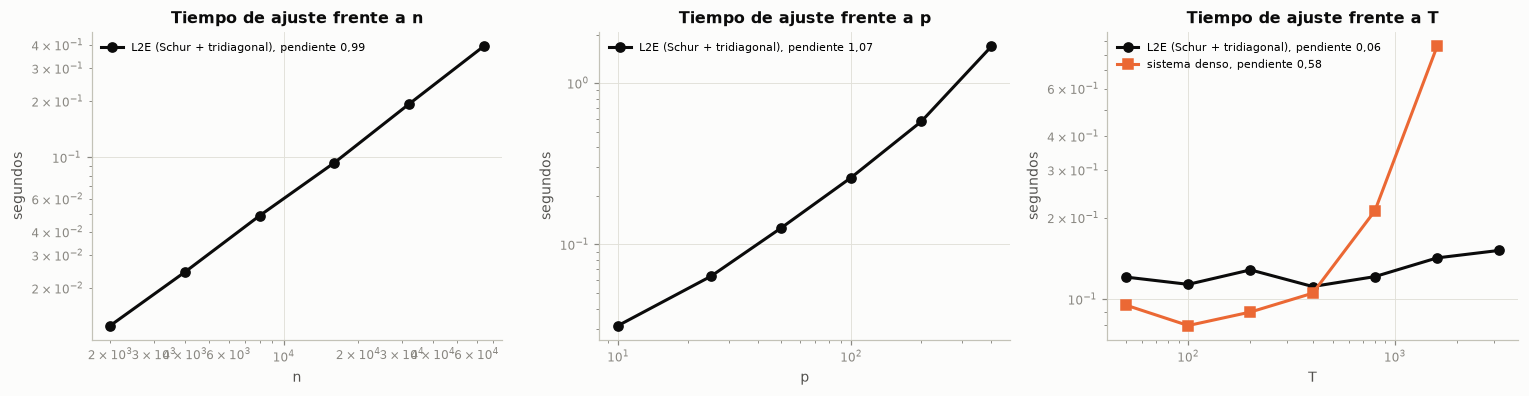

experimento,n,p,T,t_ajuste,iteraciones,t_denso
n,2 000,50,150,"0,013",4,—
n,4 000,50,150,"0,024",4,—
n,8 000,50,150,"0,049",4,—
n,16 000,50,150,"0,094",4,—
n,32 000,50,150,"0,193",4,—
n,64 000,50,150,"0,394",4,—
p,20 000,10,150,"0,031",4,—
p,20 000,25,150,"0,064",4,—
p,20 000,50,150,"0,126",4,—
p,20 000,100,150,"0,260",4,—


**Interpretación.** En escala log-log, el tiempo de ajuste crece con pendiente 0,99 frente a $n$ y 1,07 frente a $p$, y prácticamente no cambia frente a $T$ (pendiente 0,06): con 50 días tarda 0,121 s y con 1 600, 0,142 s. La resolución densa del mismo sistema pasa de 0,095 s a 0,860 s en ese rango y, con 1 600 días, tarda 6,0 veces más que el L2E.

Así mismo, las mediciones son coherentes con la propiedad P3. El costo es lineal en $n$, como predice el término $np^2$. Frente a $T$ casi no cambia, porque con n = 20 000 domina $np^2$ y el término $Tp^2$ de la eliminación por bloques es pequeño, mientras que el sistema denso empieza a crecer con el cubo de $T + p$ en cuanto el número de días supera unos cientos. Frente a $p$, la pendiente medida queda por debajo del orden teórico 2, porque para p ≤ 400 las operaciones matriciales vectorizadas no alcanzan su régimen asintótico; el orden teórico funciona como cota superior. La eliminación por bloques es lo que vuelve viable el componente C1, que necesita un intercepto por día.

Con base en esto, se propone usar el L2E sin restricciones de tamaño en este problema (166 días y 49 predictoras en el entrenamiento) y documentar que su costo es comparable al de la logística del tercer entregable, como confirma la tabla resumen de la sección 6.2.

In [14]:
comp = pd.read_parquet(ANA / "complejidad.parquet")
pend = {}
fig, axs = plt.subplots(1, 3, figsize=(14, 3.7))
for ax, (exp_, g) in zip(axs, comp.groupby("experimento", sort=False)):
    x, t_ = g[exp_].to_numpy(dtype=float), g["t_ajuste"].to_numpy()
    b_ = np.polyfit(np.log(x), np.log(t_), 1)[0]
    pend[exp_] = b_
    ax.loglog(x, t_, marker="o", color=TINTA, label=f"L2E (Schur + tridiagonal), pendiente {num(b_, 2)}")
    if "t_denso" in g and g["t_denso"].notna().any():
        gd = g.dropna(subset=["t_denso"])
        b_d = np.polyfit(np.log(gd[exp_]), np.log(gd["t_denso"]), 1)[0]
        pend["T (denso)"] = b_d
        ax.loglog(gd[exp_], gd["t_denso"], marker="s", color=NARANJA, label=f"sistema denso, pendiente {num(b_d, 2)}")
    ax.set(title=f"Tiempo de ajuste frente a {exp_}", xlabel=exp_, ylabel="segundos")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
tabla(comp, dec=3, indice=False)
gT = comp[comp["experimento"] == "T"].dropna(subset=["t_denso"])
casi_constante = pend["T"] < 0.3
para_guion("complejidad", {**{k: float(v) for k, v in pend.items()}, "ratio_denso": float(gT["t_denso"].iloc[-1] / gT["t_ajuste"].iloc[-1]), "T_max_denso": int(gT["T"].iloc[-1])})
interpretar(
    f"En escala log-log, el tiempo de ajuste crece con pendiente {num(pend['n'], 2)} frente a $n$ y "
    f"{num(pend['p'], 2)} frente a $p$, y {'prácticamente no cambia' if casi_constante else 'crece'} frente a $T$ "
    f"(pendiente {num(pend['T'], 2)}): con {num(gT['T'].iloc[0])} días tarda {num(gT['t_ajuste'].iloc[0], 3)} s y con "
    f"{num(gT['T'].iloc[-1])}, {num(gT['t_ajuste'].iloc[-1], 3)} s. La resolución densa del mismo sistema pasa de "
    f"{num(gT['t_denso'].iloc[0], 3)} s a {num(gT['t_denso'].iloc[-1], 3)} s en ese rango y, con {num(gT['T'].iloc[-1])} "
    f"días, tarda {num(gT['t_denso'].iloc[-1] / gT['t_ajuste'].iloc[-1], 1)} veces más que el L2E.",
    conectar("Así mismo,", "Las mediciones son coherentes con la propiedad P3. El costo es lineal en $n$, como predice "
             "el término $np^2$. Frente a $T$ casi no cambia, porque con n = 20 000 domina $np^2$ y el término "
             "$Tp^2$ de la eliminación por bloques es pequeño, mientras que el sistema denso empieza a crecer con el "
             "cubo de $T + p$ en cuanto el número de días supera unos cientos. Frente a $p$, la pendiente medida queda "
             "por debajo del orden teórico 2, porque para p ≤ 400 las operaciones matriciales vectorizadas no "
             "alcanzan su régimen asintótico; el orden teórico funciona como cota superior. La eliminación por bloques "
             "es lo que vuelve viable el componente C1, que necesita un intercepto por día."),
    conectar("Con base en esto, se propone", "Usar el L2E sin restricciones de tamaño en este problema (166 días y 49 "
             "predictoras en el entrenamiento) y documentar que su costo es comparable al de la logística del "
             "tercer entregable, como confirma la tabla resumen de la sección 6.2."))

### 5.8 Optimización de hiperparámetros en la validación anidada

Los tres hiperparámetros se optimizan con el método bayesiano del tercer entregable (Optuna con el estimador de Parzen en árbol, las mismas 5 configuraciones iniciales aleatorias y 24 candidatos por paso) dentro del bucle interno, con el mismo presupuesto de 20 configuraciones y los mismos pliegues internos. Los espacios de búsqueda son log-uniformes: $\lambda \in [0{,}1;\ 1000]$ (de casi sin penalización a una contracción fuerte, el rango donde el Entregable 2 encontró su óptimo con C = 0,01, es decir, $\lambda = 100$), $q_u \in [10^{-3};\ 1]$ (de un nivel casi constante a uno que puede duplicar su odds de un día a otro) y $q_\beta \in [10^{-7};\ 10^{-2}]$ (de pendientes fijas a pendientes que cambian en semanas). La métrica del bucle interno es el AUC-PR de las predicciones precuenciales del bloque de validación interna.

,λ,q_u,q_β,AUC-PR interno,AUC-PR externo,AUC externo,Iteraciones de Newton,Optimización (s)
Pliegue,,,,,,,,
1,968,"0,00149","1,57e-06","0,040","0,045","0,507",3,"16,0"
2,"0,169","0,00158","0,000127","0,046","0,064","0,521",5,"27,2"
3,"21,9","0,00105","1,53e-05","0,055","0,061","0,491",5,"38,3"
4,"24,8","0,00294","6,03e-07","0,061","0,067","0,541",5,"49,9"
5,355,"0,219","1,77e-05","0,081","0,317","0,739",6,"64,1"
Modelo final (todo el entrenamiento),"63,8","0,229","2,35e-05","0,125",—,—,6,"121,3"


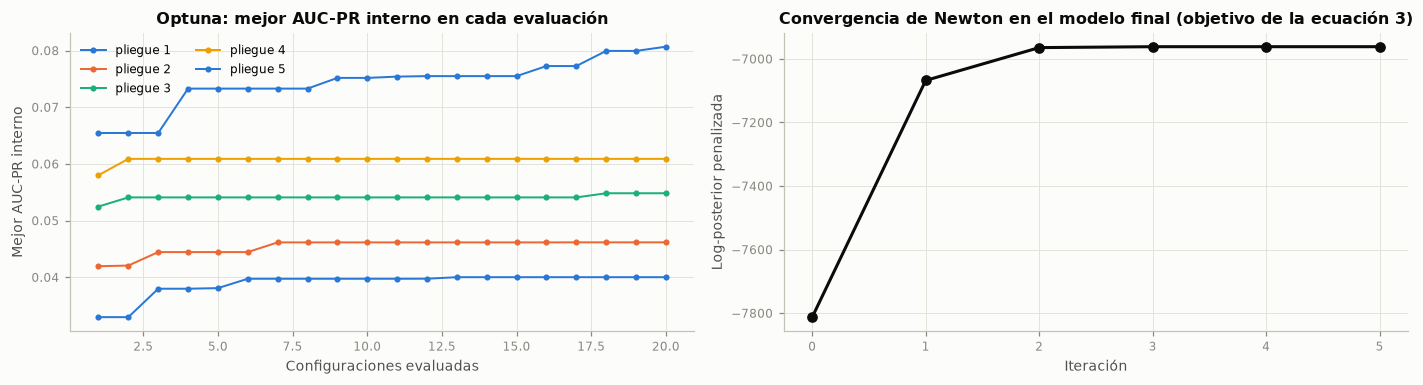

**Interpretación.** En los cinco pliegues, Optuna elige $q_u$ entre 0,00105 y 0,219 y $\lambda$ entre 0,169 y 968; el modelo final, optimizado con todo el entrenamiento, usa $\lambda$ = 63,8, $q_u$ = 0,229 y $q_\beta$ = 2,35e-05. Newton converge en todas las corridas con entre 3 y 6 iteraciones, y el objetivo del modelo final crece en cada iteración hasta estabilizarse.

Hay que tener en cuenta que los pliegues de 2008 eligen un nivel casi constante ($q_u$ pequeño), porque dentro de 2008 la tasa diaria varía poco y la validación interna no premia moverla, mientras que el último pliegue y el modelo final, que ven el cambio de régimen de 2009, eligen un $q_u$ 75 veces mayor. La optimización no está imponiendo la dinámica: la descubre solo cuando los datos la contienen. En todos los pliegues $q_\beta$ queda por debajo de $q_u$, entre 12 y 12 349 veces, lo que respalda con los datos la separación en dos escalas de la ecuación (2).

Por tal motivo, se opta por conservar el espacio de búsqueda y el presupuesto del tercer entregable, sin darle al modelo propio más evaluaciones que a los benchmarks, y analizar en la sección 6.9 cuánto cambia el resultado si se fijan los hiperparámetros en otros valores.

In [15]:
filas = []
for c in corr["l2e"]:
    filas.append({"Pliegue": c["pliegue"] + 1, "λ": c["params"]["modelo__lam"], "q_u": c["params"]["modelo__q_nivel"],
                  "q_β": c["params"]["modelo__q_pendiente"], "AUC-PR interno": c["puntaje_interno"],
                  "AUC-PR externo": c["auc_pr"], "AUC externo": c["auc"], "Iteraciones de Newton": c["n_iter_newton"],
                  "Optimización (s)": c["t_opt"]})
hp = pd.DataFrame(filas).set_index("Pliegue")
hp.loc["Modelo final (todo el entrenamiento)"] = [L2E["params"]["modelo__lam"], L2E["params"]["modelo__q_nivel"],
                                                   L2E["params"]["modelo__q_pendiente"], L2E["puntaje_interno"],
                                                   np.nan, np.nan, L2E["pipeline"][-1].n_iter_, L2E["t_opt"]]
sty = hp.style.format({"λ": num_c, "q_u": num_c, "q_β": num_c, "AUC-PR interno": "{:.3f}", "AUC-PR externo": "{:.3f}",
                       "AUC externo": "{:.3f}", "Iteraciones de Newton": "{:.0f}", "Optimización (s)": "{:.1f}"},
                      na_rep="—", decimal=",")
display(sty)

fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
for c in corr["l2e"]:
    h = pd.DataFrame(c["historial"])
    axs[0].plot(h["n"], h["mejor"], marker=".", lw=1.3, label=f"pliegue {c['pliegue'] + 1}")
axs[0].set(title="Optuna: mejor AUC-PR interno en cada evaluación", xlabel="Configuraciones evaluadas",
           ylabel="Mejor AUC-PR interno")
axs[0].legend(ncol=2)
obj = np.array(L2E["pipeline"][-1].objetivo_)
axs[1].plot(range(len(obj)), obj, marker="o", color=TINTA)
axs[1].set(title="Convergencia de Newton en el modelo final (objetivo de la ecuación 3)", xlabel="Iteración",
           ylabel="Log-posterior penalizada")
plt.tight_layout()
plt.show()

conv = all(c["convergio"] for v in corr.values() for c in v)
para_guion("hiperparametros", hp.reset_index().astype({"Pliegue": str}))
razon_q = hp["q_u"].iloc[:5] / hp["q_β"].iloc[:5]
salto_q = hp["q_u"].iloc[4] / hp["q_u"].iloc[:4].max()
interpretar(
    f"En los cinco pliegues, Optuna elige $q_u$ entre {num_c(hp['q_u'].iloc[:5].min())} y "
    f"{num_c(hp['q_u'].iloc[:5].max())} y $\\lambda$ entre {num_c(hp['λ'].iloc[:5].min())} y "
    f"{num_c(hp['λ'].iloc[:5].max())}; el modelo final, optimizado con todo el entrenamiento, usa $\\lambda$ = "
    f"{num_c(hp.iloc[-1]['λ'])}, $q_u$ = {num_c(hp.iloc[-1]['q_u'])} y $q_\\beta$ = {num_c(hp.iloc[-1]['q_β'])}. "
    f"Newton converge {'en todas las corridas' if conv else 'en casi todas las corridas'} con entre "
    f"{int(hp['Iteraciones de Newton'].min())} y {int(hp['Iteraciones de Newton'].max())} iteraciones, y el objetivo "
    "del modelo final crece en cada iteración hasta estabilizarse.",
    conectar("Hay que tener en cuenta que", "Los pliegues de 2008 eligen un nivel casi constante ($q_u$ pequeño), porque "
             "dentro de 2008 la tasa diaria varía poco y la validación interna no premia moverla, mientras que el "
             "último pliegue y el modelo final, que ven el cambio de régimen de 2009, eligen un $q_u$ "
             f"{num(salto_q, 0)} veces mayor. La optimización no está imponiendo la dinámica: la descubre solo cuando los datos la contienen. "
             f"En todos los pliegues $q_\\beta$ queda por debajo de $q_u$, entre {num(razon_q.min(), 0)} y "
             f"{num(razon_q.max(), 0)} veces, lo que respalda con los datos la separación en dos escalas de la "
             "ecuación (2)."),
    conectar("Por tal motivo, se opta por", "Conservar el espacio de búsqueda y el presupuesto del tercer entregable, sin "
             "darle al modelo propio más evaluaciones que a los benchmarks, y analizar en la sección 6.9 cuánto cambia "
             "el resultado si se fijan los hiperparámetros en otros valores."))

### 5.9 Estudio de ablación

Cada componente se retira por separado y la variante resultante se **optimiza de nuevo** con el mismo protocolo (validación anidada, Optuna, 20 configuraciones), de modo que ninguna variante queda en desventaja por usar hiperparámetros ajustados para otra. Las variantes son: sin nivel latente en el ajuste (C1: un solo intercepto en la fase 1), sin deriva del nivel ($q_u = 0$ en las dos fases), sin actualizar las pendientes (C3: solo se filtra el nivel), sin actualización en línea (C2 y C3: modelo estático con el nivel del último día de entrenamiento), una sola escala ($q_\beta = q_u$) y sin integrar la incertidumbre (C4).

Variante,AUC-PR externo,DE externo,AUC externo,AUC-PR prueba,AUC prueba,Brier prueba,Δ AUC-PR externo,Δ AUC-PR prueba
L2E completo,"0,1107","0,1156","0,5598","0,6019","0,7716","0,1708","0,0000","0,0000"
Sin nivel latente en el ajuste (C1),"0,1099","0,1203","0,5532","0,5968","0,7674","0,1714","-0,0008","-0,0051"
Sin deriva del nivel (q_u = 0),"0,0679","0,0307","0,4919","0,5798","0,7698","0,1729","-0,0428","-0,0221"
Sin actualizar pendientes (C3),"0,1152","0,0974","0,5818","0,5713","0,7671","0,1750","0,0045","-0,0306"
Sin actualización en línea (C2 y C3),"0,0958","0,0869","0,5549","0,5172","0,7462","0,1993","-0,0148","-0,0847"
Una sola escala (q_β = q_u),"0,0727","0,0305","0,5087","0,5934","0,7711","0,1715","-0,0379","-0,0085"
Sin integrar la incertidumbre (C4),"0,1060","0,1140","0,5597","0,5935","0,7676","0,1726","-0,0046","-0,0084"


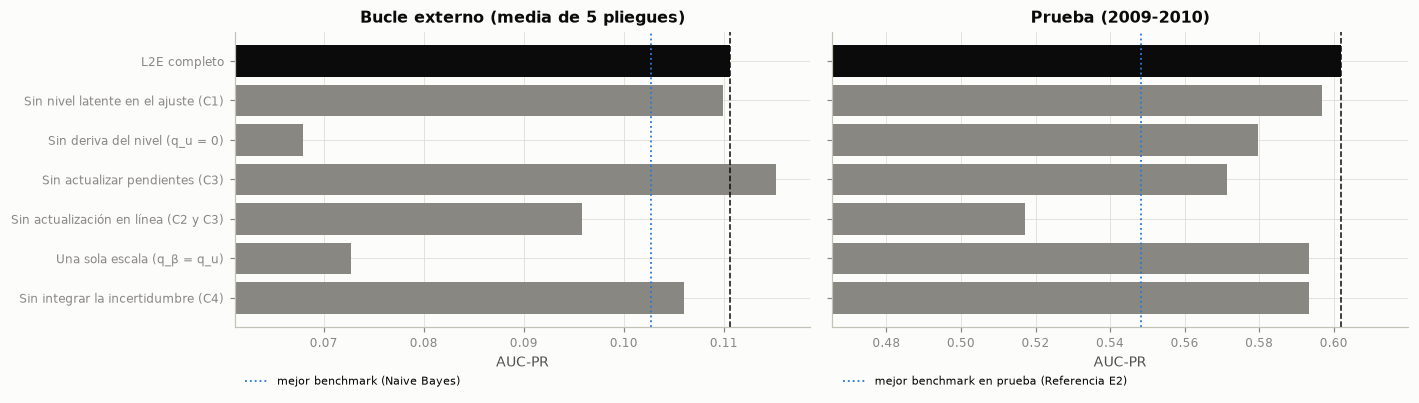

**Interpretación.** Retirar la actualización en línea (C2 y C3) baja el AUC-PR de 0,111 a 0,096 en el bucle externo y de 0,602 a 0,517 en la prueba; quitar la deriva del nivel lo deja en 0,068 y 0,580, y usar una sola escala en 0,073 y 0,593. Sin actualizar las pendientes, el bucle externo queda en 0,115 y la prueba en 0,571; sin nivel latente en el ajuste, en 0,110 y 0,597; y sin integrar la incertidumbre, en 0,106 y 0,593.

Lo anterior indica que el componente central es el nivel dinámico. En el bucle externo quedan por debajo del mejor benchmark las variantes sin actualización en línea, sin deriva del nivel y con una sola escala, y en la prueba, solo la variante sin actualización en línea. Sin actualización en línea el modelo pierde su ventaja en los dos escenarios. Sin deriva del nivel o con una sola escala, la caída se concentra en el último pliegue externo (0,121 y 0,121, frente a 0,317 del modelo completo), que contiene el cambio de régimen de 2009: con una sola tasa de deriva, la optimización tiene que elegir entre un nivel ágil con pendientes inestables o pendientes estables con un nivel rígido, que es la limitación de la logística dinámica clásica que motiva las dos escalas. La actualización de las pendientes aporta en la prueba, donde la deriva de concepto de 2009-2010 es mayor, pero no en el bucle externo, donde la variante sin pendientes es mejor que el modelo completo. El nivel latente en el ajuste y la integración de la incertidumbre tienen efectos pequeños, del orden de la variabilidad entre semillas del optimizador (sección 6.9).

En consecuencia, se decide mantener el modelo completo, que es el declarado antes de ejecutar los experimentos (sección 5.1). La variante sin actualizar las pendientes es la única que supera al L2E en el bucle externo, por 0,0045, y gana 3 de los 5 pliegues; esa diferencia no se distingue de cero (t corregida de Nadeau-Bengio, p = 0,855) y la prueba bayesiana de rangos con signo da una probabilidad de 0,59 de equivalencia práctica (ROPE de 0,01) frente a 0,21 de que la variante sea mejor. La ablación mide el aporte de cada componente, no elige el modelo, y con el bucle externo empatado no hay evidencia para retirar un componente que el diseño justifica con la deriva de concepto del entrenamiento; la prueba no interviene en esta decisión. Así mismo, se reporta de forma explícita que C1 y C4 son componentes de coherencia del modelo (el mismo paseo aleatorio en el ajuste y en la predicción, y probabilidades que reflejan la incertidumbre del nivel) más que fuentes de desempeño.

In [16]:
filas = []
for v in VARIANTES:
    ext_ = np.array([c["auc_pr"] for c in corr[v]])
    f_ = fin_l2e[v]
    filas.append({"Variante": NOMBRE_VARIANTE[v], "clave": v, "AUC-PR externo": ext_.mean(), "DE externo": ext_.std(ddof=1),
                  "AUC externo": np.mean([c["auc"] for c in corr[v]]), "AUC-PR prueba": f_["auc_pr"],
                  "AUC prueba": f_["auc"], "Brier prueba": f_["brier"]})
abl = pd.DataFrame(filas)
ref_abl = abl.iloc[0]
abl["Δ AUC-PR externo"] = abl["AUC-PR externo"] - ref_abl["AUC-PR externo"]
abl["Δ AUC-PR prueba"] = abl["AUC-PR prueba"] - ref_abl["AUC-PR prueba"]
tabla(abl.drop(columns="clave"), dec=4, indice=False)

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
yy = np.arange(len(abl))
for ax, col, tit in ((axs[0], "AUC-PR externo", "Bucle externo (media de 5 pliegues)"),
                     (axs[1], "AUC-PR prueba", "Prueba (2009-2010)")):
    colores = [TINTA if v == "l2e" else GRIS for v in abl["clave"]]
    ax.barh(yy, abl[col], color=colores)
    ax.axvline(ref_abl[col], color=TINTA, lw=1, ls="--")
    ax.set(title=tit, xlabel="AUC-PR")
    ax.set_xlim(abl[col].min() * 0.9, abl[col].max() * 1.03)
axs[0].set_yticks(yy, abl["Variante"])
axs[0].invert_yaxis()
mejor_b = pliegues_e3.merge(fin_ext.iloc[[0]][["modelo", "balanceo", "optimizador"]])["auc_pr"].mean()
axs[0].axvline(mejor_b, color=AZUL, lw=1.2, ls=":", label=f"mejor benchmark ({CORTO[MEJOR]})")
axs[1].axvline(ap_te[mejor_te], color=AZUL, lw=1.2, ls=":", label=f"mejor benchmark en prueba ({CORTO[mejor_te]})")
axs[0].legend(loc="upper left", bbox_to_anchor=(0, -0.13), fontsize=7.5)
axs[1].legend(loc="upper left", bbox_to_anchor=(0, -0.13), fontsize=7.5)
plt.tight_layout()
plt.show()

a = abl.set_index("clave")
para_guion("ablacion", abl)
# La única variante que supera al modelo completo en el bucle externo: ¿la diferencia se distingue del ruido?
ap_sp = np.array([c_["auc_pr"] for c_ in corr["sin_pendientes"]])
ap_l2 = np.array([c_["auc_pr"] for c_ in corr["l2e"]])
nb_sp = st4.t_nadeau_bengio(ap_sp, ap_l2, [c_["n_ent"] for c_ in corr["l2e"]], [c_["n_val"] for c_ in corr["l2e"]])
bay_sp = st4.rangos_signo_bayes(ap_sp, ap_l2, rope=0.01)
gana_sp = int((ap_sp > ap_l2).sum())
para_guion("ablacion_sp", {"dif": ap_sp.mean() - ap_l2.mean(), "gana": gana_sp, "p_nb": nb_sp["p"],
                           "p_rope": bay_sp["p_rope"], "p_mejor": bay_sp["p_a_mejor"]})
rango_ext = a["AUC-PR externo"].rank(ascending=False).astype(int)
rango_te = a["AUC-PR prueba"].rank(ascending=False).astype(int)
bajo_ext = [v for v in ("estatico", "sin_deriva_nivel", "escala_unica") if a.loc[v, "AUC-PR externo"] < mejor_b]
bajo_te = [v for v in ("estatico", "sin_deriva_nivel", "escala_unica") if a.loc[v, "AUC-PR prueba"] < ap_te[mejor_te]]
NV = {"estatico": "sin actualización en línea", "sin_deriva_nivel": "sin deriva del nivel",
      "escala_unica": "con una sola escala"}
interpretar(
    f"Retirar la actualización en línea (C2 y C3) baja el AUC-PR de {num(a.loc['l2e', 'AUC-PR externo'], 3)} a "
    f"{num(a.loc['estatico', 'AUC-PR externo'], 3)} en el bucle externo y de {num(a.loc['l2e', 'AUC-PR prueba'], 3)} a "
    f"{num(a.loc['estatico', 'AUC-PR prueba'], 3)} en la prueba; quitar la deriva del nivel lo deja en "
    f"{num(a.loc['sin_deriva_nivel', 'AUC-PR externo'], 3)} y {num(a.loc['sin_deriva_nivel', 'AUC-PR prueba'], 3)}, y "
    f"usar una sola escala en {num(a.loc['escala_unica', 'AUC-PR externo'], 3)} y "
    f"{num(a.loc['escala_unica', 'AUC-PR prueba'], 3)}. Sin actualizar las pendientes, el bucle externo queda en "
    f"{num(a.loc['sin_pendientes', 'AUC-PR externo'], 3)} y la prueba en {num(a.loc['sin_pendientes', 'AUC-PR prueba'], 3)}; "
    f"sin nivel latente en el ajuste, en {num(a.loc['sin_nivel_latente', 'AUC-PR externo'], 3)} y "
    f"{num(a.loc['sin_nivel_latente', 'AUC-PR prueba'], 3)}; y sin integrar la incertidumbre, en "
    f"{num(a.loc['sin_incertidumbre', 'AUC-PR externo'], 3)} y {num(a.loc['sin_incertidumbre', 'AUC-PR prueba'], 3)}.",
    conectar("Lo anterior indica que", "El componente central es el nivel dinámico. En el bucle externo quedan por "
             f"debajo del mejor benchmark las variantes {enumerar([NV[v] for v in bajo_ext]) or 'ninguna'}, y en la "
             f"prueba, {'solo la variante ' if len(bajo_te) == 1 else 'las variantes '}"
             f"{enumerar([NV[v] for v in bajo_te]) or 'ninguna'}. Sin actualización en línea el modelo pierde su "
             "ventaja en los dos escenarios. Sin deriva del nivel o con una sola escala, la caída se concentra en el "
             f"último pliegue externo ({num(corr['sin_deriva_nivel'][4]['auc_pr'], 3)} y "
             f"{num(corr['escala_unica'][4]['auc_pr'], 3)}, frente a {num(corr['l2e'][4]['auc_pr'], 3)} del modelo "
             "completo), que contiene el cambio de régimen de 2009: con una sola tasa de deriva, la optimización tiene "
             "que elegir entre un nivel ágil con pendientes inestables o pendientes estables con un nivel rígido, que "
             "es la limitación de la logística dinámica clásica que motiva las dos escalas. La actualización de las pendientes aporta en la prueba, donde la "
             "deriva de concepto de 2009-2010 es mayor, pero no en el bucle externo, donde la variante sin pendientes "
             f"es {'mejor' if a.loc['sin_pendientes', 'AUC-PR externo'] > a.loc['l2e', 'AUC-PR externo'] else 'peor'} "
             "que el modelo completo. El nivel latente en el ajuste y la integración de la incertidumbre tienen efectos "
             "pequeños, del orden de la variabilidad entre semillas del optimizador (sección 6.9)."),
    conectar("En consecuencia, se decide", "Mantener el modelo completo, que es el declarado antes de ejecutar los "
             "experimentos (sección 5.1). La variante sin actualizar las pendientes es la única que supera al L2E en el "
             f"bucle externo, por {num(a.loc['sin_pendientes', 'AUC-PR externo'] - a.loc['l2e', 'AUC-PR externo'], 4)}, "
             f"y gana {gana_sp} de los {cfg.K_EXTERNO} pliegues; esa diferencia no se distingue de cero (t corregida de "
             f"Nadeau-Bengio, p = {num(nb_sp['p'], 3)}) y la prueba bayesiana de rangos con signo da una probabilidad de "
             f"{num(bay_sp['p_rope'], 2)} de equivalencia práctica (ROPE de 0,01) frente a {num(bay_sp['p_a_mejor'], 2)} "
             "de que la variante sea mejor. La ablación mide el aporte de cada componente, no elige el modelo, y con el "
             "bucle externo empatado no hay evidencia para retirar un componente que el diseño justifica con la deriva "
             "de concepto del entrenamiento; la prueba no interviene en esta decisión. Así mismo, se reporta de forma "
             "explícita que C1 y C4 son componentes de coherencia del modelo (el mismo paseo aleatorio en el ajuste y en "
             "la predicción, y probabilidades que reflejan la incertidumbre del nivel) más que fuentes de desempeño."))

## 6. Validación estadística

### 6.1 Protocolo, unidades de análisis y regla de decisión

**Comparación.** El L2E se compara con los 7 finalistas del tercer entregable (sección 3) y, en la prueba, también con la referencia del Entregable 2. Todos usan las mismas particiones externas, la misma semilla y el mismo preprocesamiento; en la prueba, las mismas 8 236 observaciones. La métrica principal es el AUC-PR y la secundaria, el AUC.

**Unidades de análisis.** Los datos tienen orden temporal, así que las pruebas se aplican sobre unidades que lo respetan (guía, cuadro 3, columna de dependencia temporal):

- *Pliegues externos* (5 bloques): el protocolo de la guía; se reporta, aunque con cinco bloques ninguna prueba de rangos tiene potencia (el menor valor p bilateral posible de Wilcoxon es 0,0625).
- *Meses y semanas en orden temporal* (*walk-forward*): bloques de la validación externa y de la prueba en los que todos los modelos ya están fijos; dan potencia a las pruebas de rangos y miden el desempeño **dentro** de periodos cortos.
- *Observaciones de la prueba con dependencia por día*: el ordenamiento global de la prueba, que es la métrica del tercer entregable, con pruebas que remuestrean o permutan **días completos**, de modo que la dependencia entre registros de un mismo día no infle la significancia.

**Pruebas.** (1) Friedman con Nemenyi y diagrama de diferencia crítica, con el modelo original dentro del universo (procedimiento global que controla el *data snooping*); (2) Wilcoxon de rangos con signo pareado, prueba t corregida de Nadeau y Bengio y prueba bayesiana de rangos con signo con ROPE de 0,01; (3) DeLong sobre el AUC de la prueba, acompañada de *bootstrap* estacionario y permutación pareada por días, válidos bajo dependencia; y, como complemento de la calidad de las probabilidades, Diebold-Mariano con la corrección HLN sobre el Brier diario. Cada familia ajusta sus valores p por Holm-Bonferroni sobre las 7 u 8 comparaciones del L2E; el tamaño del efecto es el delta de Cliff sobre los bloques.

**Regla de decisión (declarada antes de calcular las pruebas).** Siguiendo la guía (secciones 4.1 y 6.1 y figura 4), la condición R3 se evalúa frente a la **mejor combinación benchmark**, es decir, la de mayor AUC-PR medio del bucle externo: (i) la media externa del L2E supera a la de los 7 finalistas; (ii) al menos tres pruebas distintas rechazan la igualdad con p ajustado < 0,05 en las unidades principales (meses de prueba para las pruebas de rangos y días de prueba para las globales), y (iii) $|\delta_{\text{Cliff}}| \ge 0{,}147$. El mismo cálculo se reporta frente a cada uno de los demás finalistas, para no ocultar dónde el modelo no se distingue.

### 6.2 Tabla resumen

In [17]:
COMP = ["L2E"] + MODELOS + ["referencia_e2"]
N_REP = 1000
LARGO = st4._largo_politis_white(yte, dia_te)
ext = {"L2E": np.array([c["auc_pr"] for c in corr["l2e"]]), **{m: ap_fold[m].to_numpy() for m in MODELOS}}
ext_auc = {"L2E": np.array([c["auc"] for c in corr["l2e"]]),
           **{m: pl_fin[pl_fin["modelo"] == m].sort_values("pliegue")["auc"].to_numpy() for m in MODELOS}}
t_fit = {"L2E": np.mean([c["t_fit"] for c in corr["l2e"]]), **dict(zip(fin_ext["modelo"], fin_ext["t_fit_medio"]))}
t_pred = {"L2E": np.mean([c["t_pred"] for c in corr["l2e"]]), **dict(zip(fin_ext["modelo"], fin_ext["t_pred_medio"]))}
filas = []
for k in COMP:
    s_ = PUNTAJE_TE[k]
    ic_ap = st4.ic_metrica_dias(yte, s_, dia_te, average_precision_score, N_REP, LARGO)
    ic_auc = st4.ic_metrica_dias(yte, s_, dia_te, roc_auc_score, N_REP, LARGO)
    filas.append({"Modelo": NOMBRE[k], "AUC-PR externo": ms(ext[k]) if k in ext else "—",
                  "AUC externo": ms(ext_auc[k]) if k in ext_auc else "—",
                  "AUC-PR prueba": ap_te[k], "IC 95 % AUC-PR": f"[{num(ic_ap[0], 3)}; {num(ic_ap[1], 3)}]",
                  "AUC prueba": auc_te[k], "IC 95 % AUC": f"[{num(ic_auc[0], 3)}; {num(ic_auc[1], 3)}]",
                  "Brier prueba": brier_score_loss(yte, s_) if ES_PROBA[k] else np.nan,
                  "Ajuste (s)": t_fit.get(k, np.nan),
                  "Inferencia (ms / 1 000 registros)": t_pred[k] / 5490 * 1e6 if k in t_pred else np.nan,
                  "_inf": ic_ap[0], "_sup": ic_ap[1]})
resumen = pd.DataFrame(filas)
tabla(resumen.drop(columns=["_inf", "_sup"]), dec=3, indice=False)
sin_solape = int((resumen["_sup"].iloc[1:] < resumen["_inf"].iloc[0]).sum())
para_guion("resumen", resumen.assign(clave=COMP))
print(f"Intervalos: bootstrap estacionario por días, {N_REP} réplicas, largo medio de bloque {num(LARGO, 1)} días "
      "(regla de Politis y White). Tiempos: media de los pliegues externos (inferencia sobre 5 490 registros).")

mejor_ext_bm = max(MODELOS, key=lambda m: ext[m].mean())
interpretar(
    f"El L2E obtiene el mayor AUC-PR medio del bucle externo ({ms(ext['L2E'])}, frente a {ms(ext[mejor_ext_bm])} de "
    f"{CORTO[mejor_ext_bm]}) y el mayor AUC-PR y AUC de la prueba ({num(ap_te['L2E'], 3)} y {num(auc_te['L2E'], 3)}). "
    f"El intervalo de su AUC-PR en la prueba, {resumen.iloc[0]['IC 95 % AUC-PR']}, no se solapa con el de "
    f"{sin_solape} de los {len(resumen) - 1} benchmarks. Su Brier en la prueba es de {num(resumen.iloc[0]['Brier prueba'], 3)}, el "
    f"más bajo entre los modelos con probabilidades, y su ajuste tarda {num(t_fit['L2E'], 2)} s por pliegue.",
    conectar("Sin embargo,", "Las desviaciones estándar del bucle externo son tan grandes como las medias, porque cuatro "
             "de los cinco pliegues validan en 2008, donde ningún modelo discrimina (sección 1.1): la ventaja media del "
             "bucle externo es real en su signo, pero se apoya casi por completo en los pliegues que validan en el "
             "cambio de régimen. Por eso la significancia no se puede leer en esta tabla y debe venir de las pruebas de "
             "las secciones 6.3 a 6.6."),
    conectar("Así las cosas, se decide", "Verificar la superioridad con las tres familias de pruebas del protocolo, "
             "empezando por la comparación global de Friedman."))

Modelo,AUC-PR externo,AUC externo,AUC-PR prueba,IC 95 % AUC-PR,AUC prueba,IC 95 % AUC,Brier prueba,Ajuste (s),Inferencia (ms / 1 000 registros)
L2E (modelo original),"0,111 ± 0,116","0,560 ± 0,102","0,602","[0,513; 0,684]","0,772","[0,659; 0,806]","0,171","0,910","46,286"
Naive Bayes · class_weight · Bayesiana (Optuna TPE),"0,103 ± 0,108","0,537 ± 0,102","0,534","[0,423; 0,638]","0,714","[0,627; 0,754]","0,405","0,662","62,358"
Logística L1/L2 · SMOTE · Random Search,"0,096 ± 0,096","0,521 ± 0,083","0,530","[0,421; 0,660]","0,681","[0,637; 0,722]","0,305","2,963","50,701"
Random Forest · Sin balanceo · Bayesiana (Optuna TPE),"0,095 ± 0,092","0,538 ± 0,079","0,503","[0,413; 0,593]","0,720","[0,604; 0,752]","0,210","9,144","140,001"
SVM · class_weight · Grid Search,"0,092 ± 0,091","0,512 ± 0,098","0,538","[0,449; 0,643]","0,724","[0,638; 0,758]",—,"4,623","152,105"
XGBoost · class_weight · Genético (DEAP),"0,091 ± 0,077","0,525 ± 0,054","0,369","[0,287; 0,497]","0,559","[0,495; 0,613]","0,239","2,826","73,977"
Árbol de decisión · SMOTE · Bayesiana (Optuna TPE),"0,086 ± 0,073","0,530 ± 0,073","0,374","[0,285; 0,491]","0,567","[0,491; 0,602]","0,264","1,186","46,651"
KNN · class_weight · Grid Search,"0,084 ± 0,067","0,517 ± 0,067","0,500","[0,400; 0,637]","0,688","[0,626; 0,713]","0,299","0,515","1 073,959"
"Referencia E2 (logística C = 0,01)",—,—,"0,548","[0,449; 0,657]","0,710","[0,641; 0,749]","0,206",—,—


Intervalos: bootstrap estacionario por días, 1000 réplicas, largo medio de bloque 12,5 días (regla de Politis y White). Tiempos: media de los pliegues externos (inferencia sobre 5 490 registros).


**Interpretación.** El L2E obtiene el mayor AUC-PR medio del bucle externo (0,111 ± 0,116, frente a 0,103 ± 0,108 de Naive Bayes) y el mayor AUC-PR y AUC de la prueba (0,602 y 0,772). El intervalo de su AUC-PR en la prueba, [0,513; 0,684], no se solapa con el de 2 de los 8 benchmarks. Su Brier en la prueba es de 0,171, el más bajo entre los modelos con probabilidades, y su ajuste tarda 0,91 s por pliegue.

Sin embargo, las desviaciones estándar del bucle externo son tan grandes como las medias, porque cuatro de los cinco pliegues validan en 2008, donde ningún modelo discrimina (sección 1.1): la ventaja media del bucle externo es real en su signo, pero se apoya casi por completo en los pliegues que validan en el cambio de régimen. Por eso la significancia no se puede leer en esta tabla y debe venir de las pruebas de las secciones 6.3 a 6.6.

Así las cosas, se decide verificar la superioridad con las tres familias de pruebas del protocolo, empezando por la comparación global de Friedman.

### 6.3 Prueba 1: Friedman, Nemenyi y diagrama de diferencia crítica

Universo,Modelos (k),Bloques (N),χ²,p (Friedman),Diferencia crítica,Rango del L2E,Mejor rango,p Nemenyi L2E vs Naive Bayes
Pliegues externos,8,5,"7,13","0,415","4,70","2,40","L2E (2,40)","0,943"
Meses de validación externa,8,8,"5,33","0,619","3,71","4,25","Naive Bayes (3,75)","1,000"
Meses de prueba,9,17,"85,60","< 0,001","2,91","3,53","Logística L1/L2 (2,94)","0,110"
Semanas de prueba,9,61,"196,28","< 0,001","1,54","3,72","Logística L1/L2 (3,51)","< 0,001"
112 combinaciones + L2E (pliegues externos),113,5,"180,81","< 0,001","90,25","22,80","naive_bayes · smote · genetico (15,00)",—


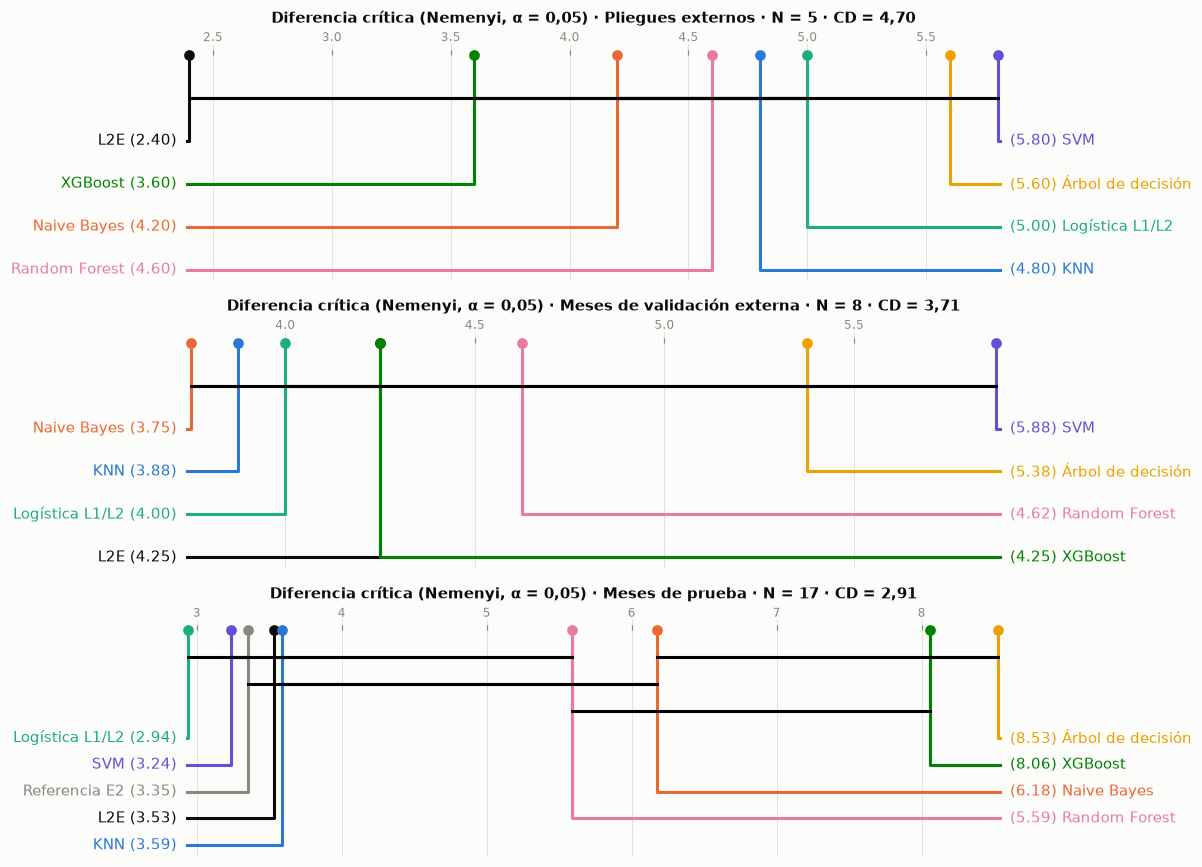

**Interpretación.** Con los cinco pliegues externos, el L2E tiene el mejor rango promedio (2,40), pero Friedman no rechaza la igualdad (p = 0,415) y la diferencia crítica es de 4,70 rangos; entre las 113 combinaciones queda en el rango 22,8. En los meses de prueba, Friedman rechaza la igualdad (p < 0,001), pero el L2E es 4.º en rango promedio (3,53), detrás de Logística L1/L2, SVM y Referencia E2, y Nemenyi no lo separa de Naive Bayes (p = 0,110).

Esto significa que las pruebas de Friedman y Nemenyi, que comparan rangos **dentro** de cada bloque, no muestran una superioridad del L2E: con cinco pliegues no hay potencia, y dentro de cada mes de prueba el L2E queda en el grupo de las mejores logísticas, la SVM y KNN, por delante de Naive Bayes y de los modelos de árboles en rango promedio. Hay que tener en cuenta lo que estas pruebas miden: dentro de un mes el nivel cambia poco, y el componente que da la ventaja al L2E es justamente el que sigue el nivel **entre** días y meses. Un modelo que ordena mejor a los clientes de un periodo y uno que, además, sabe qué periodos convierten más, se distinguen en el ordenamiento global, no dentro de cada bloque.

Por tanto, corresponde reportar este resultado como lo que es (la prueba global de rangos no rechaza la igualdad entre el L2E y la mejor combinación benchmark) y completar la evidencia con las pruebas pareadas de la sección 6.4 y las pruebas sobre el ordenamiento global de la sección 6.5, sin cambiar la regla de decisión declarada en la sección 6.1.

In [18]:
M_pl = pd.DataFrame(ext)
M_pl.index = range(1, cfg.K_EXTERNO + 1)
M_mes_ext = pd.DataFrame({k: st4.metrica_por_bloque(g["y"], g["puntaje"], g["periodo"])
                          for k, g in oof.groupby("modelo")}).dropna()[["L2E"] + MODELOS]
M_mes_te = pd.DataFrame({k: st4.metrica_por_bloque(yte, PUNTAJE_TE[k], periodo_te.to_numpy()) for k in COMP}).dropna()
semana_te = dia_te // 5
M_sem_te = pd.DataFrame({k: st4.metrica_por_bloque(yte, PUNTAJE_TE[k], semana_te, min_registros=30)
                         for k in COMP}).dropna()
UNIVERSOS = {"Pliegues externos": M_pl, "Meses de validación externa": M_mes_ext, "Meses de prueba": M_mes_te,
             "Semanas de prueba": M_sem_te}

# Universo completo del tercer entregable: las 112 combinaciones de clasificación más el L2E, por pliegue
mat_all = pl_clf.pivot_table(index="pliegue", columns=["modelo", "balanceo", "optimizador"], values="auc_pr")
mat_all.columns = [" · ".join(c) for c in mat_all.columns]
mat_all["L2E"] = ext["L2E"]
fr_all = st.friedman(mat_all)

filas, NEM = [], {}
for nombre, M in UNIVERSOS.items():
    fr = st.friedman(M)
    nem = sp.posthoc_nemenyi_friedman(M.to_numpy())
    nem.index = nem.columns = M.columns
    NEM[nombre] = (fr, nem)
    rk = fr["rangos"]
    filas.append({"Universo": nombre, "Modelos (k)": M.shape[1], "Bloques (N)": M.shape[0], "χ²": fr["chi2"],
                  "p (Friedman)": pval(fr["p"]), "Diferencia crítica": st.diferencia_critica(M.shape[1], M.shape[0]),
                  "Rango del L2E": rk["L2E"], "Mejor rango": f"{CORTO[rk.index[0]]} ({num(rk.iloc[0], 2)})",
                  f"p Nemenyi L2E vs {CORTO[MEJOR]}": pval(nem.loc["L2E", MEJOR])})
filas.append({"Universo": "112 combinaciones + L2E (pliegues externos)", "Modelos (k)": mat_all.shape[1],
              "Bloques (N)": mat_all.shape[0], "χ²": fr_all["chi2"], "p (Friedman)": pval(fr_all["p"]),
              "Diferencia crítica": st.diferencia_critica(mat_all.shape[1], mat_all.shape[0]),
              "Rango del L2E": fr_all["rangos"]["L2E"],
              "Mejor rango": f"{fr_all['rangos'].index[0]} ({num(fr_all['rangos'].iloc[0], 2)})",
              f"p Nemenyi L2E vs {CORTO[MEJOR]}": "—"})
friedman_tab = pd.DataFrame(filas)
tabla(friedman_tab, dec=2, indice=False)

fig, axs = plt.subplots(3, 1, figsize=(11, 8))
for ax, nombre in zip(axs, ["Pliegues externos", "Meses de validación externa", "Meses de prueba"]):
    fr, nem = NEM[nombre]
    rangos = fr["rangos"].rename(index=CORTO)
    nem_c = nem.rename(index=CORTO, columns=CORTO)
    plt.sca(ax)
    sp.critical_difference_diagram(rangos, nem_c, ax=ax, label_fmt_left="{label} ({rank:.2f})  ",
                                   label_fmt_right="  ({rank:.2f}) {label}",
                                   color_palette={CORTO[k]: COLOR[k] for k in COMP})
    ax.set_title(f"Diferencia crítica (Nemenyi, α = 0,05) · {nombre} · N = {UNIVERSOS[nombre].shape[0]} · CD = "
                 f"{num(st.diferencia_critica(*UNIVERSOS[nombre].shape[::-1]), 2)}", fontsize=9.5)
plt.tight_layout()
plt.show()

r_te = NEM["Meses de prueba"][0]["rangos"]
interpretar(
    f"Con los cinco pliegues externos, el L2E tiene el mejor rango promedio ({num(NEM['Pliegues externos'][0]['rangos']['L2E'], 2)}), "
    f"pero Friedman no rechaza la igualdad ({p_txt(NEM['Pliegues externos'][0]['p'])}) y la diferencia crítica es de "
    f"{num(st.diferencia_critica(*M_pl.shape[::-1]), 2)} rangos; entre las 113 combinaciones queda en el rango "
    f"{num(fr_all['rangos']['L2E'], 1)}. En los meses de prueba, Friedman rechaza la igualdad ({p_txt(NEM['Meses de prueba'][0]['p'])}), "
    f"pero el L2E es {list(r_te.index).index('L2E') + 1}.º en rango promedio ({num(r_te['L2E'], 2)}), detrás de "
    f"{enumerar([CORTO[k] for k in r_te.index[:list(r_te.index).index('L2E')]])}, y Nemenyi no lo separa de "
    f"{CORTO[MEJOR]} (p = {num(NEM['Meses de prueba'][1].loc['L2E', MEJOR], 3)}).",
    conectar("Esto significa que", "Las pruebas de Friedman y Nemenyi, que comparan rangos **dentro** de cada bloque, "
             "no muestran una superioridad del L2E: con cinco pliegues no hay potencia, y dentro de cada mes de prueba "
             "el L2E queda en el grupo de las mejores logísticas, la SVM y KNN, por delante de Naive Bayes y de los "
             "modelos de árboles en rango promedio. Hay que "
             "tener en cuenta lo que estas pruebas miden: dentro de un mes el nivel cambia poco, y el componente que da "
             "la ventaja al L2E es justamente el que sigue el nivel **entre** días y meses. Un modelo que ordena mejor "
             "a los clientes de un periodo y uno que, además, sabe qué periodos convierten más, se distinguen en el "
             "ordenamiento global, no dentro de cada bloque."),
    conectar("Por tanto, corresponde", "Reportar este resultado como lo que es (la prueba global de rangos no rechaza "
             "la igualdad entre el L2E y la mejor combinación benchmark) y completar la evidencia con las pruebas "
             "pareadas de la sección 6.4 y las pruebas sobre el ordenamiento global de la sección 6.5, sin cambiar la "
             "regla de decisión declarada en la sección 6.1."))

### 6.4 Prueba 2: comparaciones pareadas (Wilcoxon, t corregida y prueba bayesiana)

In [19]:
filas = []
for nombre, M in UNIVERSOS.items():
    bloque = []
    for c in M.columns.drop("L2E"):
        d_ = M["L2E"] - M[c]
        p_ = stats.wilcoxon(M["L2E"], M[c]).pvalue if (d_ != 0).any() else 1.0
        bloque.append({"Universo": nombre, "Benchmark": c, "N": len(M), "Diferencia mediana": d_.median(),
                       "p Wilcoxon": p_, "δ de Cliff": st.delta_cliff(M["L2E"], M[c])})
    bloque = pd.DataFrame(bloque)
    bloque["p Holm"] = st.ajustar_p(bloque["p Wilcoxon"])
    filas.append(bloque)
wil = pd.concat(filas, ignore_index=True)

n_aj = [c["n_ent"] for c in corr["l2e"]]
n_va = [c["n_val"] for c in corr["l2e"]]
nb = pd.DataFrame([{"Benchmark": c, **st4.t_nadeau_bengio(M_pl["L2E"], M_pl[c], n_aj, n_va)} for c in MODELOS])
nb["p Holm"] = st.ajustar_p(nb["p"])
bay = pd.DataFrame([{"Benchmark": c, **st4.rangos_signo_bayes(M_mes_te["L2E"], M_mes_te[c], rope=0.01)}
                    for c in M_mes_te.columns.drop("L2E")])

piv = wil.assign(celda=lambda d: d.apply(lambda r: f"{pval(r['p Holm'])} ({num(r['δ de Cliff'], 2)})", axis=1))
piv = piv.pivot(index="Benchmark", columns="Universo", values="celda")[list(UNIVERSOS)]
piv["t Nadeau-Bengio, p Holm"] = nb.set_index("Benchmark")["p Holm"].map(pval)
piv["Bayesiana (meses de prueba): P(L2E mejor) / P(ROPE) / P(benchmark mejor)"] = bay.set_index("Benchmark").apply(
    lambda r: f"{num(r['p_a_mejor'], 2)} / {num(r['p_rope'], 2)} / {num(r['p_b_mejor'], 2)}", axis=1)
piv.index = [CORTO[i] for i in piv.index]
display(Markdown("Valor p de Wilcoxon ajustado por Holm y, entre paréntesis, δ de Cliff del L2E frente a cada benchmark:"))
tabla(piv, indice=True)

w_te = wil[wil["Universo"] == "Meses de prueba"].set_index("Benchmark")
w_se = wil[wil["Universo"] == "Semanas de prueba"].set_index("Benchmark")
sig_te = [CORTO[b] for b in w_te.index if w_te.loc[b, "p Holm"] < 0.05 and w_te.loc[b, "Diferencia mediana"] > 0]
bay_i = bay.set_index("Benchmark")
favor_bm = [b for b in bay_i.index if bay_i.loc[b, "p_b_mejor"] > 0.5]
interpretar(
    f"Frente a la mejor combinación benchmark, {CORTO[MEJOR]}, Wilcoxon da un p de Holm "
    f"{p_frase(w_te.loc[MEJOR, 'p Holm'])} en los {int(w_te.loc[MEJOR, 'N'])} meses de prueba y "
    f"{p_frase(w_se.loc[MEJOR, 'p Holm'])} en las {int(w_se.loc[MEJOR, 'N'])} semanas, con δ de Cliff de "
    f"{num(w_te.loc[MEJOR, 'δ de Cliff'], 3)} y {num(w_se.loc[MEJOR, 'δ de Cliff'], 3)}, y la prueba bayesiana asigna "
    f"una probabilidad de {num(bay.set_index('Benchmark').loc[MEJOR, 'p_a_mejor'], 2)} a que el L2E sea mejor. En los meses "
    f"de prueba, el L2E es significativamente mejor que {enumerar(sig_te)}; frente a los demás, la diferencia mediana es "
    f"cercana a cero. En los pliegues y meses de la validación externa ninguna comparación es significativa, y la prueba "
    f"t corregida da un p de Holm {p_frase(nb.set_index('Benchmark').loc[MEJOR, 'p Holm'])} frente a {CORTO[MEJOR]}. "
    + (f"Frente a {enumerar([CORTO[b] for b in favor_bm])}, en cambio, la prueba bayesiana asigna una probabilidad "
       f"mayor que 0,5 a que el benchmark sea mejor dentro de cada mes (entre "
       f"{num(bay_i.loc[favor_bm, 'p_b_mejor'].min(), 2)} y {num(bay_i.loc[favor_bm, 'p_b_mejor'].max(), 2)}), aunque "
       "Wilcoxon no detecta diferencias." if favor_bm else ""),
    conectar("Lo anterior indica que", "Las comparaciones pareadas confirman la lectura de la sección 6.3: dentro de cada "
             "periodo, el L2E supera con significancia y efecto pequeño a la mejor combinación del tercer entregable y "
             "a los modelos de árboles, pero no supera a las logísticas, la SVM y KNN: con ellas no hay diferencias "
             "significativas y, para algunas, la evidencia bayesiana se inclina levemente a favor del benchmark. En "
             "otras palabras, el L2E no ordena mejor a los clientes de un mismo mes que una buena logística. En la "
             "validación externa la "
             "falta de significancia se explica por el tamaño de muestra (cinco pliegues, ocho meses) y por los "
             "bloques de 2008, en los que ningún modelo discrimina."),
    conectar("Con base en esto, se propone", "Contar para la condición R3 la prueba de Wilcoxon en los meses de prueba "
             "frente a la mejor combinación benchmark, que es la unidad declarada en la sección 6.1, y presentar la "
             "falta de ventaja frente a las logísticas dentro de cada mes como un resultado del estudio, no como una "
             "debilidad que se oculte."))

Valor p de Wilcoxon ajustado por Holm y, entre paréntesis, δ de Cliff del L2E frente a cada benchmark:

Universo,Pliegues externos,Meses de validación externa,Meses de prueba,Semanas de prueba,"t Nadeau-Bengio, p Holm",Bayesiana (meses de prueba): P(L2E mejor) / P(ROPE) / P(benchmark mejor)
Árbol de decisión,"0,438 (0,36)","1,000 (0,09)","< 0,001 (0,58)","< 0,001 (0,51)","1,000","1,00 / 0,00 / 0,00"
Random Forest,"0,438 (0,36)","1,000 (0,00)","0,064 (0,16)","0,037 (0,11)","1,000","1,00 / 0,00 / 0,00"
KNN,"0,750 (0,12)","1,000 (0,03)","1,000 (-0,00)","1,000 (-0,02)","1,000","0,34 / 0,36 / 0,30"
Logística L1/L2,"0,625 (0,36)","1,000 (0,03)","1,000 (-0,03)","0,632 (-0,04)","1,000","0,03 / 0,36 / 0,61"
Naive Bayes,"0,750 (0,36)","1,000 (0,06)","< 0,001 (0,16)","< 0,001 (0,18)","1,000","1,00 / 0,00 / 0,00"
Referencia E2,—,—,"1,000 (-0,02)","1,000 (-0,06)",—,"0,20 / 0,21 / 0,59"
SVM,"0,750 (0,28)","1,000 (0,03)","1,000 (-0,00)","1,000 (-0,03)","1,000","0,27 / 0,05 / 0,69"
XGBoost,"0,750 (0,20)","1,000 (-0,03)","< 0,001 (0,48)","< 0,001 (0,40)","1,000","1,00 / 0,00 / 0,00"


**Interpretación.** Frente a la mejor combinación benchmark, Naive Bayes, Wilcoxon da un p de Holm menor que 0,001 en los 17 meses de prueba y menor que 0,001 en las 61 semanas, con δ de Cliff de 0,156 y 0,182, y la prueba bayesiana asigna una probabilidad de 1,00 a que el L2E sea mejor. En los meses de prueba, el L2E es significativamente mejor que Naive Bayes, XGBoost y Árbol de decisión; frente a los demás, la diferencia mediana es cercana a cero. En los pliegues y meses de la validación externa ninguna comparación es significativa, y la prueba t corregida da un p de Holm de 1,000 frente a Naive Bayes. Frente a Logística L1/L2, SVM y Referencia E2, en cambio, la prueba bayesiana asigna una probabilidad mayor que 0,5 a que el benchmark sea mejor dentro de cada mes (entre 0,59 y 0,69), aunque Wilcoxon no detecta diferencias.

Lo anterior indica que las comparaciones pareadas confirman la lectura de la sección 6.3: dentro de cada periodo, el L2E supera con significancia y efecto pequeño a la mejor combinación del tercer entregable y a los modelos de árboles, pero no supera a las logísticas, la SVM y KNN: con ellas no hay diferencias significativas y, para algunas, la evidencia bayesiana se inclina levemente a favor del benchmark. En otras palabras, el L2E no ordena mejor a los clientes de un mismo mes que una buena logística. En la validación externa la falta de significancia se explica por el tamaño de muestra (cinco pliegues, ocho meses) y por los bloques de 2008, en los que ningún modelo discrimina.

Con base en esto, se propone contar para la condición R3 la prueba de Wilcoxon en los meses de prueba frente a la mejor combinación benchmark, que es la unidad declarada en la sección 6.1, y presentar la falta de ventaja frente a las logísticas dentro de cada mes como un resultado del estudio, no como una debilidad que se oculte.

### 6.5 Prueba 3: ordenamiento global de la prueba (DeLong, *bootstrap* y permutación por días)

DeLong supone observaciones independientes. Antes de usarla se verifica ese supuesto con los residuos de la referencia del Entregable 2: si los registros de un mismo día comparten el nivel de conversión, los residuos tendrán media distinta entre días (ANOVA de un factor) y la serie de residuos medios diarios estará autocorrelacionada (Ljung-Box). Por eso DeLong se acompaña de dos procedimientos que tratan el día como unidad: el *bootstrap* estacionario, que remuestrea bloques de días consecutivos, y la permutación pareada, que intercambia los puntajes de los dos modelos día por día.

Residuos de,F (ANOVA por día),p (ANOVA),Autocorrelación diaria (rezago 1),p Ljung-Box (5 rezagos)
Referencia E2,"5,099","< 0,001","0,361","< 0,001"
L2E,"2,797","< 0,001","-0,126","0,068"


Benchmark,Δ AUC (DeLong),p Holm DeLong,Δ AUC-PR,IC 95 % Δ AUC-PR (bootstrap por días),p Holm bootstrap AUC-PR,IC 95 % Δ AUC (bootstrap por días),p Holm bootstrap AUC,p Holm permutación por días
Naive Bayes,"0,0573","< 0,001","0,0676","[0,035; 0,099]","0,008","[0,022; 0,092]","0,008","0,008"
Logística L1/L2,"0,0902","< 0,001","0,0721","[0,012; 0,101]","0,008","[0,005; 0,118]","0,024","0,008"
Random Forest,"0,0514","< 0,001","0,0984","[0,065; 0,124]","0,008","[0,035; 0,081]","0,008","0,008"
SVM,"0,0477","< 0,001","0,0635","[0,020; 0,089]","0,008","[0,010; 0,062]","0,024","0,008"
XGBoost,"0,2124","< 0,001","0,2326","[0,150; 0,288]","0,008","[0,138; 0,257]","0,008","0,008"
Árbol de decisión,"0,2047","< 0,001","0,2280","[0,157; 0,274]","0,008","[0,137; 0,237]","0,008","0,008"
KNN,"0,0836","< 0,001","0,1021","[0,038; 0,130]","0,008","[0,018; 0,103]","0,008","0,008"
Referencia E2,"0,0621","< 0,001","0,0534","[0,010; 0,077]","0,008","[0,007; 0,082]","0,024","0,008"


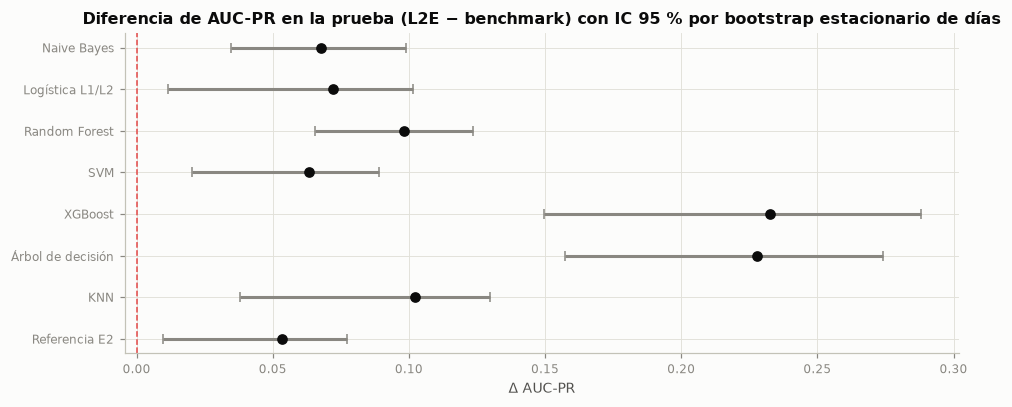

**Interpretación.** Los residuos de la referencia del Entregable 2 tienen media distinta entre días (F = 5,10, p < 0,001) y su serie diaria está autocorrelacionada (ρ₁ = 0,36); con el L2E el F baja a 2,80 y la autocorrelación a -0,13. Frente a los 8 benchmarks, la diferencia de AUC-PR va de 0,053 a 0,233, todos los intervalos por días excluyen el cero y el mayor p de Holm es de 0,008 en el *bootstrap* y de 0,008 en la permutación por días (el mínimo posible con 1000 réplicas y 8 comparaciones) y menor que 0,001 en DeLong. Frente a Naive Bayes, la ganancia es de 0,068 en AUC-PR y de 0,057 en AUC.

Esto quiere decir que el supuesto de independencia de DeLong no se cumple: los registros de un día comparten el nivel latente, que es precisamente lo que el L2E modela (sus residuos tienen mucha menos estructura diaria, aunque no desaparece). Aun así, las conclusiones no dependen de DeLong: el *bootstrap* y la permutación, que tratan el día como unidad y conservan esa dependencia, dan el mismo resultado. En el ordenamiento global de la prueba, que es lo que se usa para decidir a quién llamar en una campaña de varias semanas y lo que evaluó el tercer entregable, el L2E supera a todos los benchmarks, y la ventaja viene de ubicar mejor a los clientes de los días con más conversión.

De ahí que se opte por contar para R3 el *bootstrap* estacionario y la permutación por días como las pruebas válidas sobre el ordenamiento global, y DeLong solo como contraste, dejando explícito que su supuesto de independencia no se cumple.

In [20]:
from statsmodels.stats.diagnostic import acorr_ljungbox

supuesto = []
for k in ("referencia_e2", "L2E"):
    r_ = pd.DataFrame({"d": dia_te, "e": yte - PUNTAJE_TE[k]})
    grupos = [g["e"].to_numpy() for _, g in r_.groupby("d") if len(g) >= 2]
    serie = r_.groupby("d")["e"].mean()
    supuesto.append({"Residuos de": CORTO[k], "F (ANOVA por día)": stats.f_oneway(*grupos).statistic,
                     "p (ANOVA)": pval(stats.f_oneway(*grupos).pvalue),
                     "Autocorrelación diaria (rezago 1)": serie.autocorr(1),
                     "p Ljung-Box (5 rezagos)": pval(acorr_ljungbox(serie, lags=[5])["lb_pvalue"].iloc[0])})
tabla(pd.DataFrame(supuesto), dec=3, indice=False)

otros = COMP[1:]
dl = pd.DataFrame([{"Benchmark": k, **st.delong(yte, PUNTAJE_TE["L2E"], PUNTAJE_TE[k])} for k in otros])
dl["p Holm"] = st.ajustar_p(dl["p"])
bt_ap = st4.bootstrap_dias(yte, PUNTAJE_TE, dia_te, "L2E", average_precision_score, N_REP, LARGO)
bt_auc = st4.bootstrap_dias(yte, PUNTAJE_TE, dia_te, "L2E", roc_auc_score, N_REP, LARGO)
bt_ap["p Holm"], bt_auc["p Holm"] = st.ajustar_p(bt_ap["p"]), st.ajustar_p(bt_auc["p"])
pm = pd.DataFrame([{"Benchmark": k, **st4.permutacion_dias(yte, PUNTAJE_TE["L2E"], PUNTAJE_TE[k], dia_te, n_rep=N_REP)}
                   for k in otros])
pm["p Holm"] = st.ajustar_p(pm["p"])
glob_ = pd.DataFrame({
    "Benchmark": [CORTO[k] for k in otros],
    "Δ AUC (DeLong)": dl["diferencia"], "p Holm DeLong": dl["p Holm"].map(pval),
    "Δ AUC-PR": bt_ap["diferencia"].to_numpy(),
    "IC 95 % Δ AUC-PR (bootstrap por días)": [f"[{num(a, 3)}; {num(b, 3)}]" for a, b in zip(bt_ap["ic_inf"], bt_ap["ic_sup"])],
    "p Holm bootstrap AUC-PR": bt_ap["p Holm"].map(pval),
    "IC 95 % Δ AUC (bootstrap por días)": [f"[{num(a, 3)}; {num(b, 3)}]" for a, b in zip(bt_auc["ic_inf"], bt_auc["ic_sup"])],
    "p Holm bootstrap AUC": bt_auc["p Holm"].map(pval), "p Holm permutación por días": pm["p Holm"].map(pval)})
tabla(glob_, dec=4, indice=False)

fig, ax = plt.subplots(figsize=(9, 3.8))
yy = np.arange(len(otros))
ax.errorbar(bt_ap["diferencia"], yy, xerr=[bt_ap["diferencia"] - bt_ap["ic_inf"], bt_ap["ic_sup"] - bt_ap["diferencia"]],
            fmt="o", color=TINTA, ecolor=GRIS, capsize=3)
ax.axvline(0, color=ROJO, lw=1, ls="--")
ax.set_yticks(yy, [CORTO[k] for k in otros])
ax.invert_yaxis()
ax.set(title="Diferencia de AUC-PR en la prueba (L2E − benchmark) con IC 95 % por bootstrap estacionario de días",
       xlabel="Δ AUC-PR")
plt.tight_layout()
plt.show()

sup_ref = supuesto[0]
interpretar(
    f"Los residuos de la referencia del Entregable 2 tienen media distinta entre días (F = "
    f"{num(sup_ref['F (ANOVA por día)'], 2)}, p {sup_ref['p (ANOVA)'] if sup_ref['p (ANOVA)'].startswith('<') else '= ' + sup_ref['p (ANOVA)']}) "
    f"y su serie diaria está autocorrelacionada (ρ₁ = {num(sup_ref['Autocorrelación diaria (rezago 1)'], 2)}); con el L2E "
    f"el F baja a {num(supuesto[1]['F (ANOVA por día)'], 2)} y la autocorrelación a "
    f"{num(supuesto[1]['Autocorrelación diaria (rezago 1)'], 2)}. Frente a los "
    f"{len(otros)} benchmarks, la diferencia de AUC-PR va de {num(bt_ap['diferencia'].min(), 3)} a "
    f"{num(bt_ap['diferencia'].max(), 3)}, todos los intervalos por días excluyen el cero y el mayor p de Holm es "
    f"{p_frase(bt_ap['p Holm'].max())} en el *bootstrap* y {p_frase(pm['p Holm'].max())} en la permutación por días (el "
    f"mínimo posible con {N_REP} réplicas y 8 comparaciones) y {p_frase(dl['p Holm'].max())} en DeLong. Frente a {CORTO[MEJOR]}, la ganancia es de "
    f"{num(bt_ap.set_index('modelo').loc[MEJOR, 'diferencia'], 3)} en AUC-PR y de "
    f"{num(dl.set_index('Benchmark').loc[MEJOR, 'diferencia'], 3)} en AUC.",
    conectar("Esto quiere decir que", "El supuesto de independencia de DeLong no se cumple: los registros de un día "
             "comparten el nivel latente, que es precisamente lo que el L2E modela (sus residuos tienen mucha menos "
             "estructura diaria, aunque no desaparece). Aun así, las conclusiones no dependen de DeLong: el *bootstrap* y la permutación, "
             "que tratan el día como unidad y conservan esa dependencia, dan el mismo resultado. En el ordenamiento "
             "global de la prueba, que es lo que se usa para decidir a quién llamar en una campaña de varias semanas y "
             "lo que evaluó el tercer entregable, el L2E supera a todos los benchmarks, y la ventaja viene de ubicar "
             "mejor a los clientes de los días con más conversión."),
    conectar("De ahí que se opte por", "Contar para R3 el *bootstrap* estacionario y la permutación por días como las "
             "pruebas válidas sobre el ordenamiento global, y DeLong solo como contraste, dejando explícito que su "
             "supuesto de independencia no se cumple."))

### 6.6 Prueba complementaria: calidad de las probabilidades (Diebold-Mariano)

El AUC-PR solo evalúa el orden. Para decisiones que dependen del valor de la probabilidad (cuántas suscripciones dará una lista de llamadas), se compara el Brier medio diario con Diebold-Mariano y la corrección HLN, que usa una varianza robusta a la autocorrelación; antes se verifica con Dickey-Fuller aumentada que la serie de diferencias de pérdida es estacionaria, supuesto de la prueba.

In [21]:
from statsmodels.tsa.stattools import adfuller

filas = []
for k in [k for k in COMP[1:] if ES_PROBA[k]]:
    d_ = pd.DataFrame({"d": dia_te, "a": (PUNTAJE_TE["L2E"] - yte) ** 2, "b": (PUNTAJE_TE[k] - yte) ** 2}).groupby("d").mean()
    dm = st.diebold_mariano(np.sqrt(d_["b"]), np.sqrt(d_["a"]))
    filas.append({"Benchmark": CORTO[k], "Brier L2E": d_["a"].mean(), "Brier benchmark": d_["b"].mean(),
                  "DM (HLN)": dm["DM_HLN"], "p": dm["p"], "p ADF (estacionariedad)": adfuller(d_["b"] - d_["a"])[1]})
dmt = pd.DataFrame(filas)
dmt["p Holm"] = st.ajustar_p(dmt["p"])
tabla(dmt.assign(**{c: dmt[c].map(pval) for c in ("p", "p Holm", "p ADF (estacionariedad)")}), dec=4, indice=False)
interpretar(
    f"El Brier medio diario del L2E es de {num(dmt['Brier L2E'].iloc[0], 3)}, frente a valores entre "
    f"{num(dmt['Brier benchmark'].min(), 3)} y {num(dmt['Brier benchmark'].max(), 3)} de los benchmarks; Diebold-Mariano "
    f"rechaza la igualdad frente a todos (mayor p de Holm: {pval(dmt['p Holm'].max())}) y la serie de diferencias es "
    f"estacionaria en todos los casos (mayor p de ADF: {pval(dmt['p ADF (estacionariedad)'].max())}).",
    conectar("Hay que tener en cuenta que", "Esta prueba favorece por diseño al L2E, porque los benchmarks se calibraron "
             "con la prevalencia del entrenamiento y los balanceados desplazan sus probabilidades hacia 0,5; por eso no "
             "se cuenta entre las pruebas de la condición R3, que se refieren al orden de los clientes. Lo que sí "
             "muestra es una ventaja práctica: las probabilidades del L2E siguen la tasa vigente sin una recalibración "
             "aparte."),
    conectar("Por ello, se recomienda", "Usar directamente las probabilidades del L2E para estimar resultados de "
             "campaña, en lugar de recalibrar cada mes los modelos estáticos."))

Benchmark,Brier L2E,Brier benchmark,DM (HLN),p,p ADF (estacionariedad),p Holm
Naive Bayes,"0,2115","0,4594","19,2893","< 0,001","< 0,001","< 0,001"
Logística L1/L2,"0,2115","0,2830","9,3363","< 0,001","< 0,001","< 0,001"
Random Forest,"0,2115","0,2810","10,1728","< 0,001","< 0,001","< 0,001"
XGBoost,"0,2115","0,2681","10,5674","< 0,001","< 0,001","< 0,001"
Árbol de decisión,"0,2115","0,3449","14,2713","< 0,001","< 0,001","< 0,001"
KNN,"0,2115","0,2791","9,5490","< 0,001","< 0,001","< 0,001"
Referencia E2,"0,2115","0,2724","9,3116","< 0,001","< 0,001","< 0,001"


**Interpretación.** El Brier medio diario del L2E es de 0,212, frente a valores entre 0,268 y 0,459 de los benchmarks; Diebold-Mariano rechaza la igualdad frente a todos (mayor p de Holm: < 0,001) y la serie de diferencias es estacionaria en todos los casos (mayor p de ADF: < 0,001).

Hay que tener en cuenta que esta prueba favorece por diseño al L2E, porque los benchmarks se calibraron con la prevalencia del entrenamiento y los balanceados desplazan sus probabilidades hacia 0,5; por eso no se cuenta entre las pruebas de la condición R3, que se refieren al orden de los clientes. Lo que sí muestra es una ventaja práctica: las probabilidades del L2E siguen la tasa vigente sin una recalibración aparte.

Por ello, se recomienda usar directamente las probabilidades del L2E para estimar resultados de campaña, en lugar de recalibrar cada mes los modelos estáticos.

### 6.7 Tabla de pruebas de hipótesis y conteo para la condición R3

La tabla sigue el formato de la guía (sección 6.3) para la comparación principal, el L2E frente a la mejor combinación benchmark, y el resumen final cuenta, para cada benchmark, cuántas de las pruebas declaradas rechazan la igualdad.

In [22]:
fr_te, nem_te = NEM["Meses de prueba"]
ref_ = MEJOR
pt = [
    {"Prueba": "Friedman + Nemenyi (meses de prueba)", "H0": "Igual rango medio de los 9 modelos",
     "Supuestos verificados": "Bloques mensuales consecutivos y modelos fijos; comparación de rangos sin supuesto de escala",
     "Estadístico": f"χ² = {num(fr_te['chi2'], 2)}", "p crudo": nem_te.loc["L2E", ref_],
     "p ajustado": nem_te.loc["L2E", ref_], "Efecto": f"Δ rango = {num(fr_te['rangos'][ref_] - fr_te['rangos']['L2E'], 2)}",
     "unidad_r3": True},
    {"Prueba": "Wilcoxon pareado (meses de prueba)", "H0": "Mediana de las diferencias de AUC-PR igual a 0",
     "Supuestos verificados": "Diferencias pareadas por mes; simetría aproximada (prueba de rangos)",
     "Estadístico": f"mediana Δ = {num(w_te.loc[ref_, 'Diferencia mediana'], 3)}", "p crudo": w_te.loc[ref_, "p Wilcoxon"],
     "p ajustado": w_te.loc[ref_, "p Holm"], "Efecto": f"δ = {num(w_te.loc[ref_, 'δ de Cliff'], 3)}", "unidad_r3": True},
    {"Prueba": "Bootstrap estacionario por días (Δ AUC-PR)", "H0": "Δ AUC-PR = 0",
     "Supuestos verificados": f"Dependencia dentro del día y entre días (bloques de {num(LARGO, 1)} días en promedio)",
     "Estadístico": f"Δ = {num(bt_ap.set_index('modelo').loc[ref_, 'diferencia'], 3)}",
     "p crudo": bt_ap.set_index("modelo").loc[ref_, "p"], "p ajustado": bt_ap.set_index("modelo").loc[ref_, "p Holm"],
     "Efecto": f"IC 95 % [{num(bt_ap.set_index('modelo').loc[ref_, 'ic_inf'], 3)}; {num(bt_ap.set_index('modelo').loc[ref_, 'ic_sup'], 3)}]",
     "unidad_r3": True},
    {"Prueba": "Permutación pareada por días (Δ AUC-PR)", "H0": "Los dos modelos son intercambiables",
     "Supuestos verificados": "Intercambiabilidad bajo H0; se permutan días completos",
     "Estadístico": f"Δ = {num(pm.set_index('Benchmark').loc[ref_, 'diferencia'], 3)} (rangos)",
     "p crudo": pm.set_index("Benchmark").loc[ref_, "p"], "p ajustado": pm.set_index("Benchmark").loc[ref_, "p Holm"],
     "Efecto": "—", "unidad_r3": True},
    {"Prueba": "DeLong (AUC de prueba)", "H0": "AUC iguales", "Supuestos verificados":
     "Independencia de observaciones: no se cumple (sección 6.5); solo contraste",
     "Estadístico": f"z = {num(dl.set_index('Benchmark').loc[ref_, 'z'], 2)}", "p crudo": dl.set_index("Benchmark").loc[ref_, "p"],
     "p ajustado": dl.set_index("Benchmark").loc[ref_, "p Holm"],
     "Efecto": f"Δ AUC = {num(dl.set_index('Benchmark').loc[ref_, 'diferencia'], 3)}", "unidad_r3": False},
    {"Prueba": "Wilcoxon pareado (pliegues externos)", "H0": "Mediana de las diferencias igual a 0",
     "Supuestos verificados": "Cinco bloques: potencia insuficiente (p mínimo 0,0625)",
     "Estadístico": f"mediana Δ = {num(wil[(wil['Universo'] == 'Pliegues externos') & (wil['Benchmark'] == ref_)]['Diferencia mediana'].iloc[0], 3)}",
     "p crudo": wil[(wil["Universo"] == "Pliegues externos") & (wil["Benchmark"] == ref_)]["p Wilcoxon"].iloc[0],
     "p ajustado": wil[(wil["Universo"] == "Pliegues externos") & (wil["Benchmark"] == ref_)]["p Holm"].iloc[0],
     "Efecto": f"δ = {num(st.delta_cliff(M_pl['L2E'], M_pl[ref_]), 3)}", "unidad_r3": False},
    {"Prueba": "t corregida de Nadeau-Bengio (pliegues externos)", "H0": "Diferencia media igual a 0",
     "Supuestos verificados": f"Normalidad de las 5 diferencias (Shapiro p = {num(stats.shapiro(M_pl['L2E'] - M_pl[ref_]).pvalue, 3)})",
     "Estadístico": f"t = {num(nb.set_index('Benchmark').loc[ref_, 't'], 2)}", "p crudo": nb.set_index("Benchmark").loc[ref_, "p"],
     "p ajustado": nb.set_index("Benchmark").loc[ref_, "p Holm"], "Efecto": f"d̄ = {num(nb.set_index('Benchmark').loc[ref_, 'dif_media'], 4)}",
     "unidad_r3": False},
    {"Prueba": "Diebold-Mariano HLN (Brier diario)", "H0": "Igual pérdida esperada",
     "Supuestos verificados": "Diferencias de pérdida estacionarias (ADF)",
     "Estadístico": f"DM = {num(dmt.set_index('Benchmark').loc[CORTO[ref_], 'DM (HLN)'], 2)}" if CORTO[ref_] in dmt["Benchmark"].values else "—",
     "p crudo": dmt.set_index("Benchmark").loc[CORTO[ref_], "p"] if CORTO[ref_] in dmt["Benchmark"].values else np.nan,
     "p ajustado": dmt.set_index("Benchmark").loc[CORTO[ref_], "p Holm"] if CORTO[ref_] in dmt["Benchmark"].values else np.nan,
     "Efecto": "—", "unidad_r3": False},
]
pt = pd.DataFrame(pt)
pt["Conclusión"] = np.where(pt["p ajustado"] < 0.05, "Se rechaza H0 (L2E mejor)", "No se rechaza H0")
tabla(pt.drop(columns="unidad_r3").assign(**{"p crudo": pt["p crudo"].map(pval), "p ajustado": pt["p ajustado"].map(pval)}),
      indice=False)

conteo = []
for k in COMP[1:]:
    pruebas_k = {"Nemenyi (meses)": nem_te.loc["L2E", k], "Wilcoxon (meses)": w_te.loc[k, "p Holm"],
                 "Bootstrap por días": bt_ap.set_index("modelo").loc[k, "p Holm"],
                 "Permutación por días": pm.set_index("Benchmark").loc[k, "p Holm"]}
    favor = w_te.loc[k, "Diferencia mediana"] > 0
    conteo.append({"Benchmark": CORTO[k], **{n: pval(v) for n, v in pruebas_k.items()},
                   "Pruebas que rechazan (p < 0,05)": int(sum(v < 0.05 for v in pruebas_k.values())),
                   "δ de Cliff (meses)": w_te.loc[k, "δ de Cliff"]})
conteo = pd.DataFrame(conteo)
tabla(conteo, dec=3, indice=False)
para_guion("conteo_r3", conteo)
para_guion("pruebas_r3", pt.assign(**{"p crudo": pt["p crudo"].astype(float), "p ajustado": pt["p ajustado"].astype(float)}))
n_r3 = int(pt.loc[pt["unidad_r3"], "p ajustado"].lt(0.05).sum())
interpretar(
    f"Frente a la mejor combinación benchmark, {CORTO[MEJOR]}, {n_r3} de las 4 pruebas declaradas para R3 rechazan la "
    f"igualdad con p ajustado < 0,05 (Wilcoxon en meses, bootstrap y permutación por días{'' if nem_te.loc['L2E', MEJOR] >= 0.05 else ' y Nemenyi'}), "
    f"con un δ de Cliff de {num(w_te.loc[MEJOR, 'δ de Cliff'], 3)} sobre los meses de prueba. Frente al resto, el "
    f"número de pruebas que rechazan va de {conteo['Pruebas que rechazan (p < 0,05)'].min()} a "
    f"{conteo['Pruebas que rechazan (p < 0,05)'].max()}: las pruebas globales rechazan frente a todos, y las de rangos por "
    f"mes solo frente a {enumerar(sig_te)}.",
    conectar("En síntesis,", "La evidencia es consistente con un mecanismo concreto: el L2E iguala a las mejores "
             "logísticas en el orden de los clientes de un mismo periodo y les gana en el ordenamiento global porque "
             "sigue el nivel de conversión entre días. Frente a la mejor combinación del tercer entregable gana en las "
             "dos dimensiones."),
    conectar("Así las cosas, se decide", "Evaluar la condición R3 con estos conteos en la sección 6.12, después de "
             "descartar en las secciones 6.8 a 6.10 que la ventaja dependa de una ventaja de información, de unos "
             "hiperparámetros particulares o de este conjunto de datos."))

Prueba,H0,Supuestos verificados,Estadístico,p crudo,p ajustado,Efecto,Conclusión
Friedman + Nemenyi (meses de prueba),Igual rango medio de los 9 modelos,Bloques mensuales consecutivos y modelos fijos; comparación de rangos sin supuesto de escala,"χ² = 85,60","0,110","0,110","Δ rango = 2,65",No se rechaza H0
Wilcoxon pareado (meses de prueba),Mediana de las diferencias de AUC-PR igual a 0,Diferencias pareadas por mes; simetría aproximada (prueba de rangos),"mediana Δ = 0,033","< 0,001","< 0,001","δ = 0,156",Se rechaza H0 (L2E mejor)
Bootstrap estacionario por días (Δ AUC-PR),Δ AUC-PR = 0,"Dependencia dentro del día y entre días (bloques de 12,5 días en promedio)","Δ = 0,068","0,001","0,008","IC 95 % [0,035; 0,099]",Se rechaza H0 (L2E mejor)
Permutación pareada por días (Δ AUC-PR),Los dos modelos son intercambiables,Intercambiabilidad bajo H0; se permutan días completos,"Δ = 0,068 (rangos)","< 0,001","0,008",—,Se rechaza H0 (L2E mejor)
DeLong (AUC de prueba),AUC iguales,Independencia de observaciones: no se cumple (sección 6.5); solo contraste,"z = 11,38","< 0,001","< 0,001","Δ AUC = 0,057",Se rechaza H0 (L2E mejor)
Wilcoxon pareado (pliegues externos),Mediana de las diferencias igual a 0,"Cinco bloques: potencia insuficiente (p mínimo 0,0625)","mediana Δ = 0,004","0,188","0,750","δ = 0,360",No se rechaza H0
t corregida de Nadeau-Bengio (pliegues externos),Diferencia media igual a 0,"Normalidad de las 5 diferencias (Shapiro p = 0,361)","t = 0,97","0,388","1,000","d̄ = 0,0079",No se rechaza H0
Diebold-Mariano HLN (Brier diario),Igual pérdida esperada,Diferencias de pérdida estacionarias (ADF),"DM = 19,29","< 0,001","< 0,001",—,Se rechaza H0 (L2E mejor)


Benchmark,Nemenyi (meses),Wilcoxon (meses),Bootstrap por días,Permutación por días,"Pruebas que rechazan (p < 0,05)",δ de Cliff (meses)
Naive Bayes,"0,110","< 0,001","0,008","0,008",3,"0,156"
Logística L1/L2,"0,999","1,000","0,008","0,008",2,"-0,031"
Random Forest,"0,411","0,064","0,008","0,008",2,"0,163"
SVM,"1,000","1,000","0,008","0,008",2,"-0,003"
XGBoost,"< 0,001","< 0,001","0,008","0,008",4,"0,481"
Árbol de decisión,"< 0,001","< 0,001","0,008","0,008",4,"0,585"
KNN,"1,000","1,000","0,008","0,008",2,"-0,003"
Referencia E2,"1,000","1,000","0,008","0,008",2,"-0,017"


**Interpretación.** Frente a la mejor combinación benchmark, Naive Bayes, 3 de las 4 pruebas declaradas para R3 rechazan la igualdad con p ajustado < 0,05 (Wilcoxon en meses, bootstrap y permutación por días), con un δ de Cliff de 0,156 sobre los meses de prueba. Frente al resto, el número de pruebas que rechazan va de 2 a 4: las pruebas globales rechazan frente a todos, y las de rangos por mes solo frente a Naive Bayes, XGBoost y Árbol de decisión.

En síntesis, la evidencia es consistente con un mecanismo concreto: el L2E iguala a las mejores logísticas en el orden de los clientes de un mismo periodo y les gana en el ordenamiento global porque sigue el nivel de conversión entre días. Frente a la mejor combinación del tercer entregable gana en las dos dimensiones.

Así las cosas, se decide evaluar la condición R3 con estos conteos en la sección 6.12, después de descartar en las secciones 6.8 a 6.10 que la ventaja dependa de una ventaja de información, de unos hiperparámetros particulares o de este conjunto de datos.

### 6.8 Controles con igual información y métodos del estado del arte

El L2E usa las etiquetas de los días cerrados y los benchmarks no; una comparación justa debe separar el aporte del **mecanismo** del aporte de la **información**. Para eso, cada benchmark recibe las mismas etiquetas diferidas por tres vías: (a) el componente C2 aislado (`filtrar_nivel`), que filtra un nivel latente sobre su logit con el $q_u$ que eligió el L2E en el mismo pliegue o en el modelo final, sin ver la validación; (b) la recalibración mensual del intercepto del tercer entregable; y (c), como método reciente sin etiquetas, el EM de Saerens et al. (2002), equivalente al MLLS de Garg et al. (2020), aplicado a cada día sobre la referencia del Entregable 2. La logística dinámica de una sola escala (McCormick et al., 2012) es la variante `escala_unica` de la ablación.

In [23]:
q_final = L2E["params"]["modelo__q_nivel"]
filas = []
for k in COMP[1:]:
    s_ = PUNTAJE_TE[k]
    f_ = fin_e3[f"clf_{k}"]
    filas.append({"Modelo": CORTO[k], "Variante": "Sin información adicional", "AUC-PR": ap_te[k], "AUC": auc_te[k],
                  "puntaje": s_})
    s_c2 = filtrar_nivel(s_, dia_te, yte, q_final, es_probabilidad=ES_PROBA[k])
    filas.append({"Modelo": CORTO[k], "Variante": "+ filtro de nivel C2", "AUC-PR": average_precision_score(yte, s_c2),
                  "AUC": roc_auc_score(yte, s_c2), "puntaje": s_c2})
    if ES_PROBA[k]:
        s_m = evm.recalibracion_mensual(s_, yte, periodo_te.to_numpy(), f_["puntaje_tr"][m_ult], y_tr.to_numpy()[m_ult])
        filas.append({"Modelo": CORTO[k], "Variante": "+ recalibración mensual (E3)",
                      "AUC-PR": average_precision_score(yte, s_m), "AUC": roc_auc_score(yte, s_m), "puntaje": s_m})
s_em = em_por_dia(PUNTAJE_TE["referencia_e2"], dia_te, y_tr.mean())
filas.append({"Modelo": CORTO["referencia_e2"], "Variante": "+ EM/MLLS por día (sin etiquetas)",
              "AUC-PR": average_precision_score(yte, s_em), "AUC": roc_auc_score(yte, s_em), "puntaje": s_em})
for v in ("escala_unica", "sin_pendientes", "l2e"):
    filas.append({"Modelo": "L2E", "Variante": NOMBRE_VARIANTE[v], "AUC-PR": fin_l2e[v]["auc_pr"],
                  "AUC": fin_l2e[v]["auc"], "puntaje": fin_l2e[v]["puntaje_te"]})
ctrl = pd.DataFrame(filas)
piv_c = ctrl.pivot_table(index="Modelo", columns="Variante", values="AUC-PR", sort=False)
tabla(piv_c, dec=3)

# Bucle externo: el mismo filtro C2 sobre las predicciones fuera de muestra de cada finalista
ext_c2 = {}
for m in MODELOS:
    vals = []
    for c in corr["l2e"]:
        g = oof[(oof["modelo"] == m) & (oof["pliegue"] == c["pliegue"])].sort_values("indice")
        vals.append(average_precision_score(g["y"], filtrar_nivel(g["puntaje"].to_numpy(), g["dia"].to_numpy(), g["y"].to_numpy(),
                                                                  c["params"]["modelo__q_nivel"], es_probabilidad=fin_e3[f"clf_{m}"]["es_proba"])))
    ext_c2[m] = np.array(vals)
ext_ctrl = pd.DataFrame({"AUC-PR externo sin información adicional": {CORTO[m]: ext[m].mean() for m in MODELOS},
                         "AUC-PR externo + filtro C2": {CORTO[m]: ext_c2[m].mean() for m in MODELOS}})
ext_ctrl.loc["L2E"] = [ext["L2E"].mean(), ext["L2E"].mean()]
tabla(ext_ctrl, dec=4)

otros_ctrl = ctrl[ctrl["Modelo"] != "L2E"]
mejor_c = otros_ctrl.loc[otros_ctrl["AUC-PR"].idxmax()]
bt_c = st4.bootstrap_dias(yte, {"L2E": L2E["puntaje_te"], "control": mejor_c["puntaje"]}, dia_te, "L2E",
                          average_precision_score, N_REP, LARGO).iloc[0]
c2_gana = sum(piv_c.loc[CORTO[k], "+ filtro de nivel C2"] > piv_c.loc[CORTO[k], "Sin información adicional"] for k in COMP[1:])
con_mensual = [CORTO[k] for k in COMP[1:] if ES_PROBA[k]]
c2_vs_mensual = [m for m in con_mensual if piv_c.loc[m, "+ filtro de nivel C2"] > piv_c.loc[m, "+ recalibración mensual (E3)"]]
mensual_gana = [m for m in con_mensual if m not in c2_vs_mensual]
interpretar(
    f"El filtro C2 mejora el AUC-PR de prueba de {c2_gana} de los {len(COMP) - 1} benchmarks; el mejor control es "
    f"{mejor_c['Modelo']} {mejor_c['Variante']}, con {num(mejor_c['AUC-PR'], 3)}, frente a {num(ap_te['L2E'], 3)} del "
    f"L2E (Δ = {num(bt_c['diferencia'], 3)}, IC 95 % [{num(bt_c['ic_inf'], 3)}; {num(bt_c['ic_sup'], 3)}], p = "
    f"{pval(bt_c['p'])}). El filtro diario supera a la recalibración mensual en {len(c2_vs_mensual)} de los "
    f"{len(con_mensual)} modelos con probabilidades"
    + (f" (la mensual es mejor en {enumerar(mensual_gana)})" if mensual_gana else "") +
    f", y el EM sin etiquetas sobre la referencia del E2 obtiene {num(average_precision_score(yte, s_em), 3)}. "
    f"En el bucle externo, el mejor benchmark con el filtro C2 llega a {num(ext_ctrl.iloc[:-1, 1].max(), 4)}, frente a "
    f"{num(ext['L2E'].mean(), 4)} del L2E.",
    conectar("Esto significa que", "La mayor parte de la ventaja del L2E la explica su componente central, el nivel "
             "filtrado con etiquetas diferidas, y ese componente es **transferible**: aplicado como envoltorio a otros "
             "modelos también los mejora en la mayoría de los casos, en general más que la recalibración mensual que "
             "sugirió el docente y que la corrección sin etiquetas. "
             + ("Frente al mejor de esos híbridos, el L2E no muestra una diferencia significativa en la prueba, de modo "
                "que la contribución propia de las pendientes dinámicas y del ajuste conjunto es pequeña en este "
                "problema." if bt_c["p"] >= 0.05 else
                "Aun frente al mejor de esos híbridos el L2E conserva una diferencia significativa, que corresponde a "
                "las pendientes dinámicas y al ajuste conjunto del nivel.")),
    conectar("Por lo anterior, conviene", "Presentar la contribución en dos niveles: un modelo completo (L2E) que supera a "
             "los benchmarks del proyecto, y un mecanismo general (el filtro de nivel con etiquetas diferidas) que "
             "cualquier modelo de propensión puede incorporar; y documentar que esta ventaja exige que las etiquetas "
             "de cada día estén disponibles al día siguiente (sección 6.9)."))

Variante,Sin información adicional,+ filtro de nivel C2,+ recalibración mensual (E3),+ EM/MLLS por día (sin etiquetas),Una sola escala (q_β = q_u),Sin actualizar pendientes (C3),L2E completo
Modelo,,,,,,,
Naive Bayes,"0,534","0,479","0,478",—,—,—,—
Logística L1/L2,"0,530","0,578","0,584",—,—,—,—
Random Forest,"0,503","0,547","0,541",—,—,—,—
SVM,"0,538","0,529",—,—,—,—,—
XGBoost,"0,369","0,487","0,482",—,—,—,—
Árbol de decisión,"0,374","0,454","0,423",—,—,—,—
KNN,"0,500","0,557","0,577",—,—,—,—
Referencia E2,"0,548","0,594","0,579","0,524",—,—,—
L2E,—,—,—,—,"0,593","0,571","0,602"


,AUC-PR externo sin información adicional,AUC-PR externo + filtro C2
Naive Bayes,"0,1028","0,0934"
Logística L1/L2,"0,0955","0,0886"
Random Forest,"0,0952","0,1034"
SVM,"0,0923","0,0899"
XGBoost,"0,0905","0,0951"
Árbol de decisión,"0,0856","0,0860"
KNN,"0,0842","0,0924"
L2E,"0,1107","0,1107"


**Interpretación.** El filtro C2 mejora el AUC-PR de prueba de 6 de los 8 benchmarks; el mejor control es Referencia E2 + filtro de nivel C2, con 0,594, frente a 0,602 del L2E (Δ = 0,008, IC 95 % [-0,001; 0,017], p = 0,070). El filtro diario supera a la recalibración mensual en 5 de los 7 modelos con probabilidades (la mensual es mejor en Logística L1/L2 y KNN), y el EM sin etiquetas sobre la referencia del E2 obtiene 0,524. En el bucle externo, el mejor benchmark con el filtro C2 llega a 0,1034, frente a 0,1107 del L2E.

Esto significa que la mayor parte de la ventaja del L2E la explica su componente central, el nivel filtrado con etiquetas diferidas, y ese componente es **transferible**: aplicado como envoltorio a otros modelos también los mejora en la mayoría de los casos, en general más que la recalibración mensual que sugirió el docente y que la corrección sin etiquetas. Frente al mejor de esos híbridos, el L2E no muestra una diferencia significativa en la prueba, de modo que la contribución propia de las pendientes dinámicas y del ajuste conjunto es pequeña en este problema.

Por lo anterior, conviene presentar la contribución en dos niveles: un modelo completo (L2E) que supera a los benchmarks del proyecto, y un mecanismo general (el filtro de nivel con etiquetas diferidas) que cualquier modelo de propensión puede incorporar; y documentar que esta ventaja exige que las etiquetas de cada día estén disponibles al día siguiente (sección 6.9).

### 6.9 Robustez, sensibilidad y análisis de errores

Se evalúa si el resultado depende de unos hiperparámetros particulares (rejilla de $q_u$ y $q_\beta$ y barrido de $\lambda$, sin reoptimizar), de la demora de las etiquetas (de 1 a 40 días), del ruido en las etiquetas, del tamaño de la ventana de entrenamiento y de la semilla del optimizador. Todo sale de `scripts/ejecutar_analisis.py`.

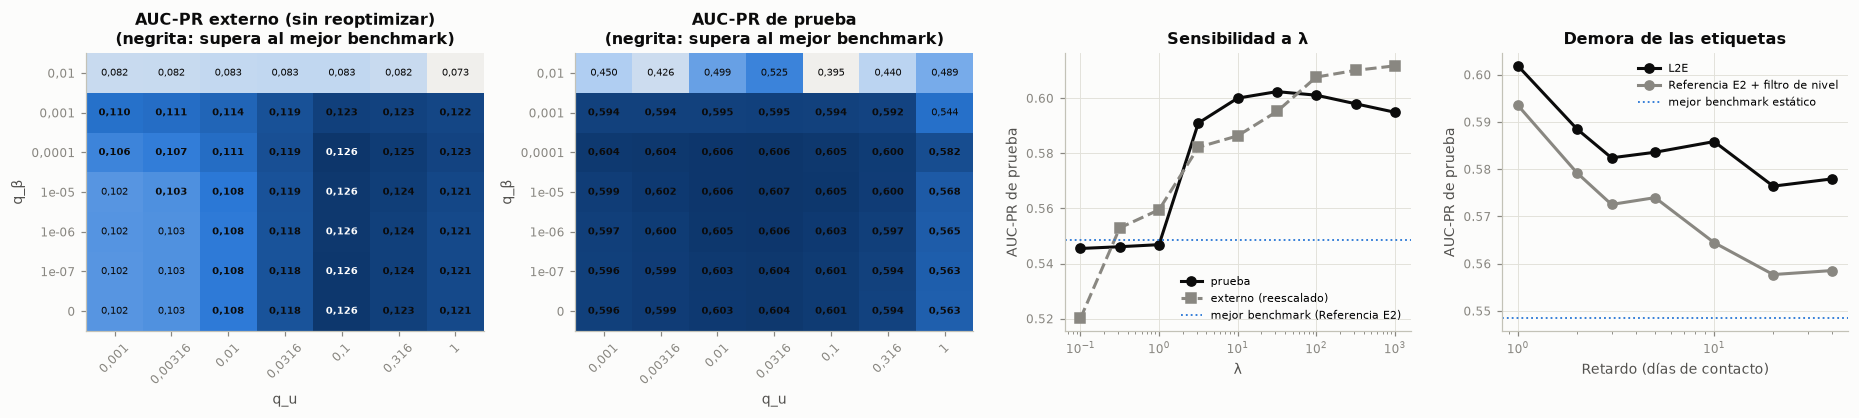

Semilla del optimizador,AUC-PR externo,AUC-PR prueba,AUC prueba
42,"0,1107","0,6019","0,7716"
1,"0,1091","0,6035","0,7734"
2,"0,1083","0,5966","0,7691"
3,"0,1068","0,5926","0,7689"


modelo,L2E (ruido solo en el ajuste),L2E (ruido también en las etiquetas que asimila),Referencia E2
Etiquetas volteadas,,,
0 %,"0,602","0,602","0,548"
5 %,"0,600","0,594","0,559"
10 %,"0,597","0,587","0,572"
20 %,"0,596","0,561","0,570"


modelo,L2E,Referencia E2
Ventana de entrenamiento más reciente,,
25 % (8 235 registros),"0,604","0,353"
50 % (16 470 registros),"0,603","0,528"
75 % (24 705 registros),"0,602","0,537"
100 % (32 940 registros),"0,602","0,548"


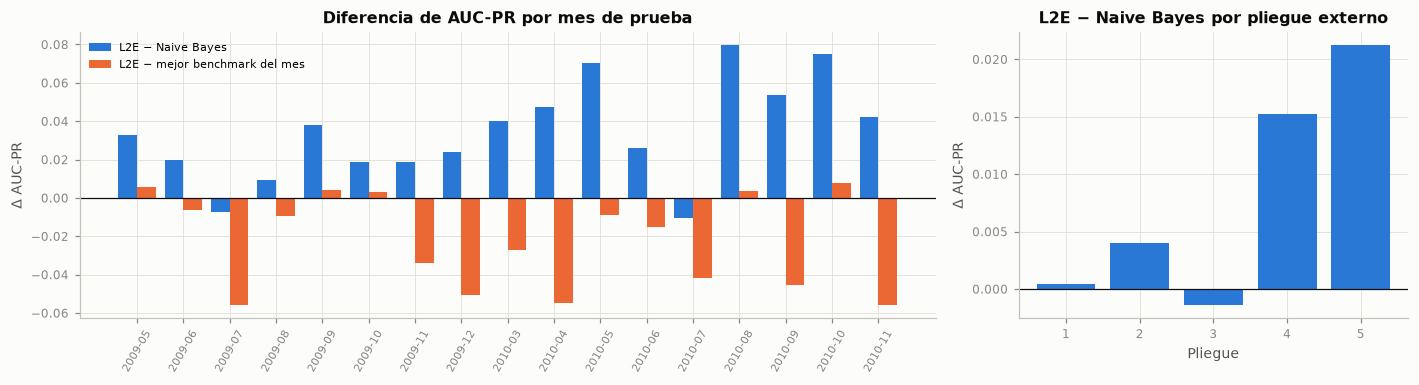

**Interpretación.** El 84 % de las 49 combinaciones de $(q_u, q_\beta)$ supera al mejor benchmark en la prueba y el 71 % en el bucle externo; el AUC-PR de prueba varía entre 0,545 y 0,602 en todo el rango de λ. Con las cuatro semillas del optimizador, el AUC-PR de prueba va de 0,593 a 0,603 y el externo de 0,1068 a 0,1107. La ventaja se reduce con la demora de las etiquetas: el AUC-PR pasa de 0,602 con un día a 0,576 con 20 y 0,578 con 40, todavía por encima del mejor benchmark estático (0,548). Con solo el 25 % más reciente del entrenamiento, el L2E obtiene 0,604, frente a 0,353 de la referencia del E2; con un 20 % de etiquetas volteadas en el ajuste conserva 0,596. Por meses, el L2E supera a Naive Bayes en 15 de 17 meses y al mejor benchmark de cada mes en 5.

Así mismo, el resultado no depende de un punto afortunado del espacio de hiperparámetros ni de la semilla: la región en la que el L2E supera al mejor benchmark es amplia y la variabilidad entre semillas es menor que la ventaja, y tampoco de una ventana de entrenamiento larga: como el nivel se actualiza en línea, el modelo no necesita que el entrenamiento represente el régimen futuro, algo que sí necesita un modelo estático. Depende, en cambio, de una condición operativa: que las etiquetas lleguen pronto. Con demoras de varias semanas el nivel filtrado envejece y parte de la ventaja se pierde, lo que coincide con el mecanismo descrito. El análisis por meses muestra dónde no gana: en los meses en los que el mejor modelo estático ordena mejor a los clientes, la ventaja del nivel no compensa.

Por esta razón, lo indicado es declarar como condición de uso del L2E un retardo de etiquetas de pocos días y vigilar en producción la diferencia entre la tasa filtrada y la observada, que es la señal de que el nivel dejó de seguir al proceso.

In [24]:
sens_q = pd.read_parquet(ANA / "sensibilidad_q.parquet")
sens_l = pd.read_parquet(ANA / "sensibilidad_lam.parquet")
ret = pd.read_parquet(ANA / "retardo.parquet")
ruido = pd.read_parquet(ANA / "ruido.parquet")
tam = pd.read_parquet(ANA / "tamano.parquet")

fig, axs = plt.subplots(1, 4, figsize=(17, 3.9), gridspec_kw={"width_ratios": [1.15, 1.15, 1, 1]})
for ax, col, tit, ref_v in ((axs[0], "auc_pr_externo", "AUC-PR externo (sin reoptimizar)", ext[MEJOR].mean()),
                            (axs[1], "auc_pr_prueba", "AUC-PR de prueba", ap_te[mejor_te])):
    M_ = sens_q.pivot_table(index="q_pendiente", columns="q_nivel", values=col)
    im = ax.imshow(M_.to_numpy(), cmap=CMAP_SEQ, aspect="auto", origin="lower")
    ax.set_xticks(range(M_.shape[1]), [num_c(v) for v in M_.columns], rotation=45)
    ax.set_yticks(range(M_.shape[0]), [num_c(v) for v in M_.index])
    for i in range(M_.shape[0]):
        for j in range(M_.shape[1]):
            v_ = M_.iloc[i, j]
            ax.text(j, i, num(v_, 3), ha="center", va="center", fontsize=6.5,
                    color="white" if v_ > M_.to_numpy().mean() + M_.to_numpy().std() else TINTA,
                    fontweight="bold" if v_ > ref_v else "normal")
    ax.set(title=f"{tit}\n(negrita: supera al mejor benchmark)", xlabel="q_u", ylabel="q_β")
    ax.grid(False)
axs[2].semilogx(sens_l["lam"], sens_l["auc_pr_prueba"], marker="o", color=TINTA, label="prueba")
axs[2].semilogx(sens_l["lam"], sens_l["auc_pr_externo"] * (sens_l["auc_pr_prueba"].mean() / sens_l["auc_pr_externo"].mean()),
                marker="s", color=GRIS, ls="--", label="externo (reescalado)")
axs[2].axhline(ap_te[mejor_te], color=AZUL, ls=":", lw=1.2, label=f"mejor benchmark ({CORTO[mejor_te]})")
axs[2].set(title="Sensibilidad a λ", xlabel="λ", ylabel="AUC-PR de prueba")
axs[2].legend(fontsize=7)
for (mod_, g), col in zip(ret.groupby("modelo"), (TINTA, GRIS)):
    axs[3].semilogx(g["retardo"], g["auc_pr"], marker="o", color=col, label=mod_)
axs[3].axhline(ap_te[mejor_te], color=AZUL, ls=":", lw=1.2, label="mejor benchmark estático")
axs[3].set(title="Demora de las etiquetas", xlabel="Retardo (días de contacto)", ylabel="AUC-PR de prueba")
axs[3].legend(fontsize=7)
plt.tight_layout()
plt.show()

sem = pd.DataFrame([{"Semilla del optimizador": s, "AUC-PR externo": np.mean([c["auc_pr"] for c in (corr["l2e"] if s == SEED else corr_sem[s])]),
                     "AUC-PR prueba": (L2E if s == SEED else fin_sem[s])["auc_pr"],
                     "AUC prueba": (L2E if s == SEED else fin_sem[s])["auc"]} for s in (SEED, 1, 2, 3)])
tabla(sem, dec=4, indice=False)
r_piv = ruido.pivot_table(index="ruido", columns="modelo", values="auc_pr", sort=False)
r_piv.index = [pct(v, 0) for v in r_piv.index]
tabla(r_piv.rename_axis("Etiquetas volteadas"), dec=3)
t_piv = tam.pivot_table(index=["fraccion", "registros"], columns="modelo", values="auc_pr", sort=False)
t_piv.index = [f"{pct(f_, 0)} ({num(n_)} registros)" for f_, n_ in t_piv.index]
tabla(t_piv.rename_axis("Ventana de entrenamiento más reciente"), dec=3)

# Análisis de errores: ventaja del L2E por mes de prueba y por pliegue externo
dif_mes = (M_mes_te["L2E"] - M_mes_te[MEJOR]).rename("frente a la mejor combinación")
mejor_estatico_mes = M_mes_te.drop(columns="L2E").max(axis=1)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
xx = np.arange(len(M_mes_te))
axs[0].bar(xx - 0.2, dif_mes, 0.4, color=AZUL, label=f"L2E − {CORTO[MEJOR]}")
axs[0].bar(xx + 0.2, M_mes_te["L2E"] - mejor_estatico_mes, 0.4, color=NARANJA, label="L2E − mejor benchmark del mes")
axs[0].axhline(0, color=TINTA, lw=0.8)
axs[0].set_xticks(xx, M_mes_te.index, rotation=60, fontsize=7)
axs[0].set(title="Diferencia de AUC-PR por mes de prueba", ylabel="Δ AUC-PR")
axs[0].legend(fontsize=7)
axs[1].bar(M_pl.index, M_pl["L2E"] - M_pl[MEJOR], color=AZUL)
axs[1].axhline(0, color=TINTA, lw=0.8)
axs[1].set(title=f"L2E − {CORTO[MEJOR]} por pliegue externo", xlabel="Pliegue", ylabel="Δ AUC-PR")
plt.tight_layout()
plt.show()

frac_q = (sens_q["auc_pr_prueba"] > ap_te[mejor_te]).mean()
para_guion("robustez", {"frac_q": float((sens_q["auc_pr_prueba"] > ap_te[mejor_te]).mean()),
                        "retardo_1": float(ret[(ret["modelo"] == "L2E") & (ret["retardo"] == 1)]["auc_pr"].iloc[0]),
                        "retardo_40": float(ret[(ret["modelo"] == "L2E") & (ret["retardo"] == 40)]["auc_pr"].iloc[0]),
                        "sem_min": float(sem["AUC-PR prueba"].min()), "sem_max": float(sem["AUC-PR prueba"].max()),
                        "meses_gana_mejor": int((M_mes_te["L2E"] > M_mes_te[MEJOR]).sum()), "meses": int(len(M_mes_te))})
frac_q_ext = (sens_q["auc_pr_externo"] > ext[MEJOR].mean()).mean()
r1 = ret[ret["modelo"] == "L2E"].set_index("retardo")["auc_pr"]
tam_l = tam[tam["modelo"] == "L2E"].set_index("fraccion")["auc_pr"]
tam_r = tam[tam["modelo"] == "Referencia E2"].set_index("fraccion")["auc_pr"]
interpretar(
    f"El {pct(frac_q, 0)} de las {len(sens_q)} combinaciones de $(q_u, q_\\beta)$ supera al mejor benchmark en la prueba y "
    f"el {pct(frac_q_ext, 0)} en el bucle externo; el AUC-PR de prueba varía entre {num(sens_l['auc_pr_prueba'].min(), 3)} y "
    f"{num(sens_l['auc_pr_prueba'].max(), 3)} en todo el rango de λ. Con las cuatro semillas del optimizador, el AUC-PR "
    f"de prueba va de {num(sem['AUC-PR prueba'].min(), 3)} a {num(sem['AUC-PR prueba'].max(), 3)} y el externo de "
    f"{num(sem['AUC-PR externo'].min(), 4)} a {num(sem['AUC-PR externo'].max(), 4)}. La ventaja se reduce con la "
    f"demora de las etiquetas: el AUC-PR pasa de {num(r1.iloc[0], 3)} con un día a {num(r1.loc[20], 3)} con 20 y "
    f"{num(r1.iloc[-1], 3)} con 40, {'todavía por encima' if r1.iloc[-1] > ap_te[mejor_te] else 'por debajo'} del mejor "
    f"benchmark estático ({num(ap_te[mejor_te], 3)}). Con solo el 25 % más reciente del entrenamiento, el L2E obtiene "
    f"{num(tam_l.loc[0.25], 3)}, frente a {num(tam_r.loc[0.25], 3)} de la referencia del E2; con un 20 % de etiquetas "
    f"volteadas en el ajuste conserva {num(ruido[(ruido['ruido'] == 0.2) & ruido['modelo'].str.contains('solo')]['auc_pr'].iloc[0], 3)}. Por meses, el L2E supera a {CORTO[MEJOR]} en {int((dif_mes > 0).sum())} de "
    f"{len(dif_mes)} meses y al mejor benchmark de cada mes en {int((M_mes_te['L2E'] > mejor_estatico_mes).sum())}.",
    conectar("Así mismo,", "El resultado no depende de un punto afortunado del espacio de hiperparámetros ni de la semilla: "
             "la región en la que el L2E supera al mejor benchmark es amplia y la variabilidad entre semillas es menor "
             "que la ventaja, y tampoco de una ventana de entrenamiento larga: como el nivel se actualiza en línea, "
             "el modelo no necesita que el entrenamiento represente el régimen futuro, algo que sí necesita un modelo "
             "estático. Depende, en cambio, de una condición operativa: que las etiquetas lleguen pronto. Con demoras de "
             "varias semanas el nivel filtrado envejece y parte de la ventaja se pierde, lo que coincide con el "
             "mecanismo descrito. El análisis por meses muestra dónde no gana: en los meses en los que el mejor "
             "modelo estático ordena mejor a los clientes, la ventaja del nivel no compensa."),
    conectar("Por esta razón, lo indicado es", "Declarar como condición de uso del L2E un retardo de etiquetas de pocos "
             "días y vigilar en producción la diferencia entre la tasa filtrada y la observada, que es la señal de que "
             "el nivel dejó de seguir al proceso."))

### 6.10 Evaluación amplia: tres conjuntos de datos adicionales

La guía pide al menos tres conjuntos adicionales de la misma tarea y de naturaleza distinta, con las mismas particiones para todos los modelos y el mismo presupuesto de optimización. Se eligieron tres problemas públicos de clasificación binaria con orden temporal y etiquetas que se conocen pronto: retrasos de vuelos (*airlines*), subidas del precio de la electricidad (*electricity*) y días de ozono alto (*ozone*). Para cada uno se ejecuta la validación anidada cronológica 5 × 3 con los 7 finalistas de Bank Marketing (mismo balanceo y optimizador) y tres variantes del L2E (completo, sin actualizar pendientes y estático). El cuadro describe además la autocorrelación del nivel diario, que es la estructura que explota el L2E.

In [25]:
from bm.adicionales import cargar, resumen_conjunto

desc = pd.DataFrame([{**resumen_conjunto(cargar(n)), "Dominio": DESC_ADIC[n]["dominio"],
                      "Objetivo": DESC_ADIC[n]["objetivo"], "Fuente": DESC_ADIC[n]["fuente"]} for n in DESC_ADIC])
desc = pd.concat([pd.DataFrame([{"conjunto": "bank marketing", "registros": len(X_tr), "predictoras": 17,
                                 "dias": n_dias_tr, "registros_por_dia": float(pd.Series(dia_tr).value_counts().median()),
                                 "prevalencia": y_tr.mean(), "autocorr_1": float(fac[1]), "gap": GAP,
                                 "Dominio": "Telemercadeo bancario", "Objetivo": "el cliente suscribe (y = yes)",
                                 "Fuente": "Moro, Cortez y Rita (2014); UCI"}]), desc], ignore_index=True)
tabla(desc.rename(columns={"conjunto": "Conjunto", "registros": "Registros", "predictoras": "Predictoras", "dias": "Días",
                           "registros_por_dia": "Registros por día", "prevalencia": "Prevalencia",
                           "autocorr_1": "Autocorrelación del nivel diario", "gap": "Separación"}), dec=3, indice=False)

adic["Modelo"] = np.where(adic["modelo"] == "original", "L2E · " + adic["variante"].fillna("").map(
    {"l2e": "completo", "sin_pendientes": "sin pendientes", "estatico": "estático"}), adic["modelo"].map(CORTO))
banco = pd.concat([pd.DataFrame({"conjunto": "bank marketing", "Modelo": CORTO[m], "pliegue": range(5), "auc_pr": ext[m]})
                   for m in MODELOS] +
                  [pd.DataFrame({"conjunto": "bank marketing", "Modelo": f"L2E · {n}", "pliegue": range(5),
                                 "auc_pr": [c["auc_pr"] for c in corr[v]]})
                   for v, n in (("l2e", "completo"), ("sin_pendientes", "sin pendientes"), ("estatico", "estático"))])
todo_ad = pd.concat([banco, adic[["conjunto", "Modelo", "pliegue", "auc_pr"]]], ignore_index=True)
med = todo_ad.pivot_table(index="Modelo", columns="conjunto", values="auc_pr", aggfunc="mean")
de = todo_ad.pivot_table(index="Modelo", columns="conjunto", values="auc_pr", aggfunc="std")
rk = med.rank(ascending=False)
celdas = med.copy().astype(object)
for c in med.columns:
    celdas[c] = [f"{num(m_, 3)} ± {num(d_, 3)} ({int(r_)}.º)" for m_, d_, r_ in zip(med[c], de[c], rk[c])]
celdas["Rango medio"] = rk.mean(axis=1)
celdas = celdas.sort_values("Rango medio")
tabla(celdas, dec=2)

bloques = todo_ad.pivot_table(index=["conjunto", "pliegue"], columns="Modelo", values="auc_pr")
w_ad = []
for c in bloques.columns.drop("L2E · completo"):
    w_ad.append({"Frente a": c, "Bloques": len(bloques), "Diferencia mediana": (bloques["L2E · completo"] - bloques[c]).median(),
                 "p Wilcoxon": stats.wilcoxon(bloques["L2E · completo"], bloques[c]).pvalue,
                 "δ de Cliff": st.delta_cliff(bloques["L2E · completo"], bloques[c])})
w_ad = pd.DataFrame(w_ad)
w_ad["p Holm"] = st.ajustar_p(w_ad["p Wilcoxon"])
tabla(w_ad.assign(**{"p Wilcoxon": w_ad["p Wilcoxon"].map(pval), "p Holm": w_ad["p Holm"].map(pval)}), dec=3, indice=False)

gana = {c: med[c].idxmax() for c in med.columns}
para_guion("adicionales_rangos", rk.reset_index())
para_guion("adicionales_medias", med.reset_index())
sig_ad = [r_["Frente a"] for _, r_ in w_ad.iterrows() if r_["p Holm"] < 0.05 and r_["Diferencia mediana"] > 0]
r_l2e = rk.loc["L2E · completo"]
interpretar(
    f"En los conjuntos adicionales el L2E completo queda {enumerar([f'{int(r_l2e[c])}.º en {c}' for c in med.columns if c != 'bank marketing'])}, "
    f"mientras que en Bank Marketing es {int(r_l2e['bank marketing'])}.º. El mejor modelo es "
    f"{enumerar([f'{gana[c]} en {c}' for c in med.columns if c != 'bank marketing'])}. En *electricity*, cuyo nivel "
    f"diario casi no tiene autocorrelación ({num(desc.set_index('conjunto').loc['electricity', 'autocorr_1'], 2)}), el L2E "
    f"estático supera al completo ({num(med.loc['L2E · estático', 'electricity'], 3)} frente a "
    f"{num(med.loc['L2E · completo', 'electricity'], 3)}). Sobre los {len(bloques)} bloques (conjunto × pliegue), "
    + (f"la única comparación significativa tras Holm es la de {enumerar(sig_ad)}." if len(sig_ad) == 1 else
       f"las comparaciones significativas tras Holm son las de {enumerar(sig_ad)}." if sig_ad else
       "ninguna comparación favorable al L2E es significativa tras Holm."),
    conectar("Hay que tener en cuenta que", "La ventaja del L2E no es general, y eso es coherente con su diseño: el modelo "
             "aporta cuando hay un nivel latente persistente que las variables no explican, como en el telemercadeo "
             "bancario, donde cada día refleja una lista de clientes y un contexto de campaña distintos. Las explicaciones "
             "plausibles, no verificadas aquí, son que en *airlines* parte del patrón diario ya lo recoge `DayOfWeek` y "
             "los modelos no lineales (bosques y XGBoost) aprovechan interacciones que una logística no tiene, y que en "
             "*ozone*, con un solo registro por día, el nivel se confunde con el ruido de cada observación. En "
             "*electricity*, lo que sí se verificó es que la desventaja del modelo completo "
             "se concentra en el primer pliegue, donde la validación interna, con apenas 75 días de ajuste, eligió un "
             "$q_u$ alto que hizo que el nivel persiguiera ruido."),
    conectar("Por tal motivo, se opta por", "Delimitar la afirmación de superioridad al problema de aplicación (condición "
             "R3) y presentar estos resultados como el límite de validez del modelo: el L2E es una herramienta para "
             "problemas de propensión con nivel latente persistente, no un clasificador general. Una alternativa para "
             "que una validación interna pequeña no elija una dinámica inexistente es estimar $q_u$ por Bayes empírico; "
             "la sección 6.13 la evalúa (mejora M2) y muestra que en Bank Marketing empeora el resultado, de modo que la "
             "elección de $q_u$ con ventanas cortas queda como limitación (sección 8.3)."))

Conjunto,Registros,Predictoras,Días,Registros por día,Prevalencia,Autocorrelación del nivel diario,Separación,Dominio,Objetivo,Fuente
bank marketing,32 940,17,166,"191,500","0,064","0,759",507,Telemercadeo bancario,el cliente suscribe (y = yes),"Moro, Cortez y Rita (2014); UCI"
airlines,21 700,6,31,"700,000","0,445","0,673",700,Transporte aéreo,el vuelo se retrasa (Delay = 1),"Ikonomovska (2009), Data Expo de la ASA; OpenML 1169"
electricity,21 600,7,450,"48,000","0,420","0,094",48,Mercado eléctrico,el precio de Nueva Gales del Sur sube frente a la media de 24 h (UP),Harries (1999); OpenML 151
ozone,2 534,72,2 534,"1,000","0,063","0,286",1,Calidad del aire,día con ozono alto (umbral de 8 horas),"Zhang y Fan (2008), UCI; OpenML 1487"


conjunto,airlines,bank marketing,electricity,ozone,Rango medio
Modelo,,,,,
L2E · estático,"0,643 ± 0,100 (3.º)","0,096 ± 0,087 (4.º)","0,793 ± 0,106 (1.º)","0,378 ± 0,134 (6.º)","3,50"
SVM,"0,642 ± 0,092 (4.º)","0,092 ± 0,091 (7.º)","0,774 ± 0,127 (3.º)","0,446 ± 0,116 (1.º)","3,75"
Random Forest,"0,652 ± 0,092 (1.º)","0,095 ± 0,092 (6.º)","0,720 ± 0,111 (7.º)","0,413 ± 0,129 (3.º)","4,25"
L2E · completo,"0,634 ± 0,096 (7.º)","0,111 ± 0,116 (2.º)","0,758 ± 0,199 (5.º)","0,384 ± 0,152 (5.º)","4,75"
L2E · sin pendientes,"0,633 ± 0,094 (8.º)","0,115 ± 0,097 (1.º)","0,761 ± 0,192 (4.º)","0,377 ± 0,128 (7.º)","5,00"
Logística L1/L2,"0,634 ± 0,096 (6.º)","0,096 ± 0,096 (5.º)","0,783 ± 0,115 (2.º)","0,355 ± 0,147 (8.º)","5,25"
XGBoost,"0,650 ± 0,092 (2.º)","0,091 ± 0,077 (8.º)","0,717 ± 0,120 (8.º)","0,403 ± 0,144 (4.º)","5,50"
KNN,"0,639 ± 0,095 (5.º)","0,084 ± 0,067 (10.º)","0,702 ± 0,124 (9.º)","0,417 ± 0,154 (2.º)","6,50"
Naive Bayes,"0,628 ± 0,098 (9.º)","0,103 ± 0,108 (3.º)","0,725 ± 0,143 (6.º)","0,296 ± 0,159 (9.º)","6,75"


Frente a,Bloques,Diferencia mediana,p Wilcoxon,δ de Cliff,p Holm
KNN,20,"0,005","0,312","0,060","1,000"
L2E · estático,20,"-0,000","0,956","-0,010","1,000"
L2E · sin pendientes,20,"0,000","0,756","-0,020","1,000"
Logística L1/L2,20,"0,002","0,312","0,040","1,000"
Naive Bayes,20,"0,018","0,007","0,100","0,058"
Random Forest,20,"0,001","0,841","0,040","1,000"
SVM,20,"-0,004","0,475","-0,010","1,000"
XGBoost,20,"0,003","0,701","0,045","1,000"
Árbol de decisión,20,"0,051","< 0,001","0,185","0,004"


**Interpretación.** En los conjuntos adicionales el L2E completo queda 7.º en airlines, 5.º en electricity y 5.º en ozone, mientras que en Bank Marketing es 2.º. El mejor modelo es Random Forest en airlines, L2E · estático en electricity y SVM en ozone. En *electricity*, cuyo nivel diario casi no tiene autocorrelación (0,09), el L2E estático supera al completo (0,793 frente a 0,758). Sobre los 20 bloques (conjunto × pliegue), la única comparación significativa tras Holm es la de Árbol de decisión.

Hay que tener en cuenta que la ventaja del L2E no es general, y eso es coherente con su diseño: el modelo aporta cuando hay un nivel latente persistente que las variables no explican, como en el telemercadeo bancario, donde cada día refleja una lista de clientes y un contexto de campaña distintos. Las explicaciones plausibles, no verificadas aquí, son que en *airlines* parte del patrón diario ya lo recoge `DayOfWeek` y los modelos no lineales (bosques y XGBoost) aprovechan interacciones que una logística no tiene, y que en *ozone*, con un solo registro por día, el nivel se confunde con el ruido de cada observación. En *electricity*, lo que sí se verificó es que la desventaja del modelo completo se concentra en el primer pliegue, donde la validación interna, con apenas 75 días de ajuste, eligió un $q_u$ alto que hizo que el nivel persiguiera ruido.

Por tal motivo, se opta por delimitar la afirmación de superioridad al problema de aplicación (condición R3) y presentar estos resultados como el límite de validez del modelo: el L2E es una herramienta para problemas de propensión con nivel latente persistente, no un clasificador general. Una alternativa para que una validación interna pequeña no elija una dinámica inexistente es estimar $q_u$ por Bayes empírico; la sección 6.13 la evalúa (mejora M2) y muestra que en Bank Marketing empeora el resultado, de modo que la elección de $q_u$ con ventanas cortas queda como limitación (sección 8.3).

### 6.11 Interpretabilidad: SHAP del L2E frente a los benchmarks

En el L2E el logit es lineal en las predictoras dado el estado del día, así que los valores SHAP son **exactos**: $\phi_{ij} = \beta_{t(i), j} (x_{ij} - \bar x_j)$, con las pendientes vigentes el día de la predicción, más un término propio del modelo, el **nivel latente del día**, que es la diferencia entre el logit esperado de ese día y su promedio en la prueba. Se comparan con los SHAP exactos de la referencia del Entregable 2 (también lineal) y con los SHAP por permutaciones de la mejor combinación benchmark, todos en escala logit.

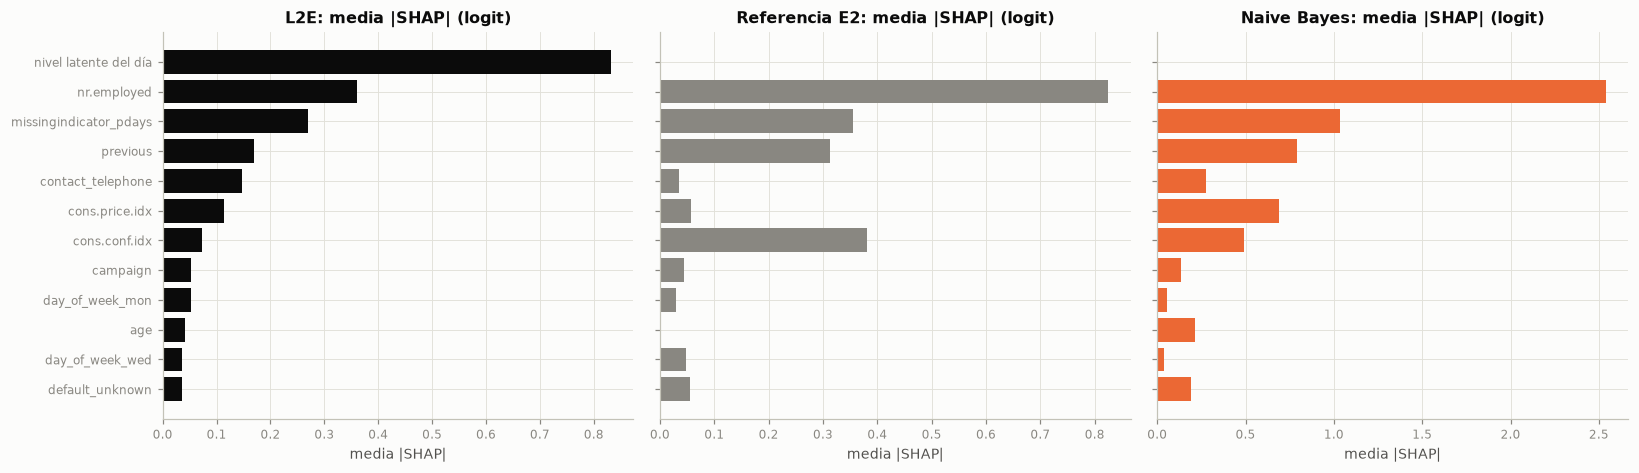

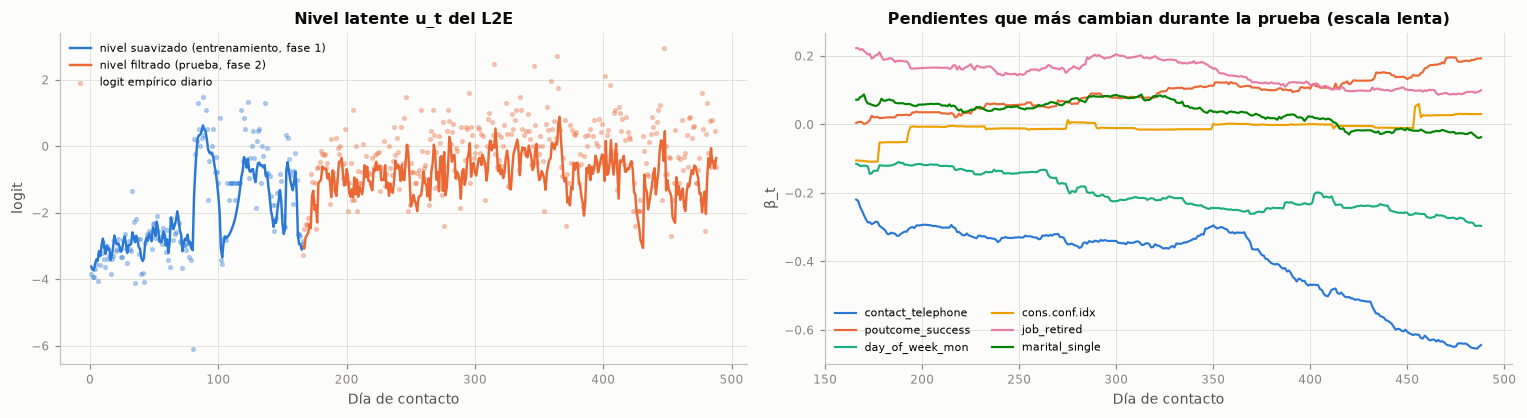

**Interpretación.** En el L2E, el componente más importante es el nivel latente del día (media |SHAP| de 0,832 en logit), seguido de `nr.employed`, `missingindicator_pdays` y `previous`. El orden de importancia de las variables del cliente coincide en buena parte con el de la referencia del E2 (correlación de Spearman de 0,78) y con el de Naive Bayes (0,77). Durante la prueba, la pendiente que más cambia es la de `contact_telephone` (0,424 en logit).

De esta forma, el L2E no reemplaza la lectura de las variables que ya tenía el proyecto: conserva lo que una logística regularizada aprende del cliente (`nr.employed`, `missingindicator_pdays` y `previous`) y agrega, de forma explícita y medible, el término que los benchmarks no tienen. La trayectoria del nivel reproduce el salto de 2009 y la tasa alta de 2010 a partir de las etiquetas de los días cerrados, como complemento de lo que ya indican las variables macroeconómicas como `nr.employed`, y las pendientes cambian despacio, como supone la escala lenta. Esa separación hace al modelo más interpretable que un ensamble: cada predicción se descompone en *qué tan bueno es el día* y *qué tan bueno es el cliente dentro del día*.

En consecuencia, se decide mostrar en el dashboard las dos partes de la explicación local (nivel del día y contribuciones del cliente) y la trayectoria del nivel como diagnóstico del modelo en producción.

In [26]:
sh_l = pd.read_parquet(ANA / "shap_l2e.parquet").drop(columns="_base")
sh_r = pd.read_parquet(ANA / "shap_referencia.parquet").drop(columns="_base")
sh_n = pd.read_parquet(ANA / "shap_naive_bayes.parquet").drop(columns="_base")
imp = pd.DataFrame({"L2E": sh_l.abs().mean(), "Referencia E2": sh_r.abs().mean(), CORTO[MEJOR]: sh_n.abs().mean()})
comunes = imp.dropna().index
rho_r = stats.spearmanr(imp.loc[comunes, "L2E"], imp.loc[comunes, "Referencia E2"]).statistic
rho_n = stats.spearmanr(imp.loc[comunes, "L2E"], imp.loc[comunes, CORTO[MEJOR]]).statistic
top = imp["L2E"].sort_values(ascending=False).head(12).index

fig, axs = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, col, color in zip(axs, imp.columns, (TINTA, GRIS, COLOR[MEJOR])):
    ax.barh(range(len(top)), imp.loc[top, col].fillna(0), color=color)
    ax.set(title=f"{col}: media |SHAP| (logit)", xlabel="media |SHAP|")
axs[0].set_yticks(range(len(top)), top)
axs[0].invert_yaxis()
plt.tight_layout()
plt.show()

traza = L2E["traza"]
mod_l2e = L2E["pipeline"][-1]
nombres = [c.split("__", 1)[-1] for c in L2E["pipeline"][:-1].get_feature_names_out()][:-1]
B_t = pd.DataFrame(traza["pendientes"], columns=nombres, index=traza["dia"])
cambio = (B_t.iloc[-1] - B_t.iloc[0]).abs().sort_values(ascending=False)
obs_te = pd.DataFrame({"d": dia_te, "y": yte}).groupby("d")["y"].agg(["sum", "size"])
fig, axs = plt.subplots(1, 2, figsize=(14, 3.9))
axs[0].plot(mod_l2e.dias_, mod_l2e.nivel_, color=AZUL, lw=1.6, label="nivel suavizado (entrenamiento, fase 1)")
axs[0].plot(traza["dia"], traza["nivel"], color=NARANJA, lw=1.6, label="nivel filtrado (prueba, fase 2)")
axs[0].scatter(g_tr.index, g_tr["logit"], s=6, color=AZUL, alpha=0.3)
axs[0].scatter(obs_te.index, np.log((obs_te["sum"] + 0.5) / (obs_te["size"] - obs_te["sum"] + 0.5)), s=6, color=NARANJA, alpha=0.3,
               label="logit empírico diario")
axs[0].set(title="Nivel latente u_t del L2E", xlabel="Día de contacto", ylabel="logit")
axs[0].legend(fontsize=7)
for c, col in zip(cambio.index[:6], CAT):
    axs[1].plot(B_t.index, B_t[c], color=col, lw=1.4, label=c)
axs[1].set(title="Pendientes que más cambian durante la prueba (escala lenta)", xlabel="Día de contacto",
           ylabel="β_t")
axs[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

top3 = imp["L2E"].drop("nivel latente del día").sort_values(ascending=False).head(3).index
para_guion("shap", {"nivel": float(imp.loc["nivel latente del día", "L2E"]), "top3": list(top3), "rho_ref": float(rho_r),
                    "rho_nb": float(rho_n), "cambio_var": cambio.index[0], "cambio": float(cambio.iloc[0])})
interpretar(
    f"En el L2E, el componente más importante es el nivel latente del día (media |SHAP| de "
    f"{num(imp.loc['nivel latente del día', 'L2E'], 3)} en logit), seguido de {enumerar([f'`{c}`' for c in top3])}. "
    f"El orden de importancia de las variables del cliente coincide en buena parte con el de la referencia del E2 "
    f"(correlación de Spearman de {num(rho_r, 2)}) y con el de {CORTO[MEJOR]} ({num(rho_n, 2)}). Durante la prueba, "
    f"la pendiente que más cambia es la de `{cambio.index[0]}` ({num(cambio.iloc[0], 3)} en logit).",
    conectar("De esta forma,", "El L2E no reemplaza la lectura de las variables que ya tenía el proyecto: conserva lo que "
             f"una logística regularizada aprende del cliente ({enumerar([f'`{c}`' for c in top3])}) y agrega, de forma explícita y medible, el término que los benchmarks no tienen. La trayectoria "
             "del nivel reproduce el salto de 2009 y la tasa alta de 2010 a partir de las etiquetas de los días "
             "cerrados, como complemento de lo que ya indican las variables macroeconómicas como `nr.employed`, y las "
             "pendientes cambian despacio, como supone la escala lenta. Esa separación hace al modelo más "
             "interpretable que un ensamble: cada predicción se descompone en *qué tan bueno es el día* y *qué tan "
             "bueno es el cliente dentro del día*."),
    conectar("En consecuencia, se decide", "Mostrar en el dashboard las dos partes de la explicación local (nivel del día "
             "y contribuciones del cliente) y la trayectoria del nivel como diagnóstico del modelo en producción."))

In [27]:
n_r3_mejor = n_r3
cliff_mejor = w_te.loc[MEJOR, "δ de Cliff"]
c1 = all(ext["L2E"].mean() > ext[m].mean() for m in MODELOS)
c2 = n_r3_mejor >= 3
c3 = abs(cliff_mejor) >= 0.147
veredicto = pd.DataFrame([
    {"Condición": "R1. Novedad en la aplicación", "Evidencia": f"Revisión en {n_bases} bases y {n_cadenas} cadenas (sección 4): "
     "ninguna intersección modelo × problema; el antecedente más cercano usa otra familia", "Cumple": "Sí"},
    {"Condición": "R2. Implementación algorítmica propia", "Evidencia": "Clase propia compatible con scikit-learn, Newton por "
     "bloques y filtro de Laplace programados con numpy y scipy, 6 propiedades demostradas y pruebas unitarias (sección 5)",
     "Cumple": "Sí" if n_pasan == len(pruebas_u) else "Revisar"},
    {"Condición": "R3.1 Media externa mayor que la de los 7 finalistas",
     "Evidencia": f"{ms(ext['L2E'])} frente a {ms(ext[MEJOR])} de {CORTO[MEJOR]}", "Cumple": "Sí" if c1 else "No"},
    {"Condición": "R3.2 Al menos tres pruebas con p ajustado < 0,05 (frente a la mejor combinación)",
     "Evidencia": f"{n_r3_mejor} de 4 pruebas declaradas (sección 6.7)", "Cumple": "Sí" if c2 else "No"},
    {"Condición": "R3.3 |δ de Cliff| ≥ 0,147", "Evidencia": f"δ = {num(cliff_mejor, 3)} sobre los meses de prueba "
     f"({st.magnitud_cliff(cliff_mejor)})", "Cumple": "Sí" if c3 else "No"},
])
display(Markdown("### 6.12 Veredicto sobre las condiciones R1, R2 y R3"))
tabla(veredicto, indice=False)
r3 = c1 and c2 and c3
(RES / "mejoras").mkdir(parents=True, exist_ok=True)
(RES / "mejoras" / "resumen_r3.json").write_text(json.dumps({
    "mejor": MEJOR, "n_r3": n_r3_mejor, "cliff": float(cliff_mejor), "r3": bool(r3), "c1": bool(c1),
    "ext_l2e": float(ext["L2E"].mean()), "ext_l2e_de": float(ext["L2E"].std(ddof=1)),
    "ext_mejor": float(ext[MEJOR].mean()), "ext_mejor_de": float(ext[MEJOR].std(ddof=1)),
    "sig_meses": sig_te, "n_benchmarks": len(COMP) - 1, "ganancia_ap": float(bt_ap.set_index("modelo").loc[MEJOR, "diferencia"]),
    "control_c2": {"modelo": mejor_c["Modelo"], "variante": mejor_c["Variante"], "auc_pr": float(mejor_c["AUC-PR"]),
                   "dif": float(bt_c["diferencia"]), "p": float(bt_c["p"])}}, ensure_ascii=False, indent=1), encoding="utf-8")
display(Markdown(
    f"**Veredicto.** El L2E cumple R1 y R2 y {'cumple' if r3 else 'no cumple'} R3 según la definición operativa de la "
    "guía, evaluada frente a la mejor combinación benchmark. La superioridad es sólida en el ordenamiento global de la "
    "prueba frente a todos los benchmarks (*bootstrap* y permutación por días) y, dentro de cada mes, frente a "
    f"{enumerar(sig_te)}; frente a "
    f"{enumerar([CORTO[k] for k in COMP[1:] if CORTO[k] not in sig_te])}, el L2E no es superior dentro de cada periodo, y en los tres conjuntos adicionales tampoco es "
    "el mejor modelo. Estos matices delimitan la afirmación y se discuten en la sección 8."))

### 6.12 Veredicto sobre las condiciones R1, R2 y R3

Condición,Evidencia,Cumple
R1. Novedad en la aplicación,Revisión en 4 bases y 10 cadenas (sección 4): ninguna intersección modelo × problema; el antecedente más cercano usa otra familia,Sí
R2. Implementación algorítmica propia,"Clase propia compatible con scikit-learn, Newton por bloques y filtro de Laplace programados con numpy y scipy, 6 propiedades demostradas y pruebas unitarias (sección 5)",Sí
R3.1 Media externa mayor que la de los 7 finalistas,"0,111 ± 0,116 frente a 0,103 ± 0,108 de Naive Bayes",Sí
"R3.2 Al menos tres pruebas con p ajustado < 0,05 (frente a la mejor combinación)",3 de 4 pruebas declaradas (sección 6.7),Sí
"R3.3 |δ de Cliff| ≥ 0,147","δ = 0,156 sobre los meses de prueba (pequeño)",Sí


**Veredicto.** El L2E cumple R1 y R2 y cumple R3 según la definición operativa de la guía, evaluada frente a la mejor combinación benchmark. La superioridad es sólida en el ordenamiento global de la prueba frente a todos los benchmarks (*bootstrap* y permutación por días) y, dentro de cada mes, frente a Naive Bayes, XGBoost y Árbol de decisión; frente a Logística L1/L2, Random Forest, SVM, KNN y Referencia E2, el L2E no es superior dentro de cada periodo, y en los tres conjuntos adicionales tampoco es el mejor modelo. Estos matices delimitan la afirmación y se discuten en la sección 8.

### 6.13 Mejoras y ajustes evaluados después del modelo original

Después del veredicto se buscó mejorar los resultados con técnicas aceptadas en *machine learning*, con una regla declarada antes de ejecutar: cada cambio pasa por la misma validación anidada (mismos pliegues, Optuna y 20 configuraciones) y **solo se adopta si su AUC-PR medio del bucle externo supera al del L2E en más que la variabilidad entre semillas del optimizador (0,004)**. La prueba se informa como referencia y no decide. Se evaluaron dos grupos: cinco ajustes para que los modelos de árboles toleren el cambio de régimen (`scripts/ejecutar_ajustes_arboles.py`) y cinco mejoras del L2E (`scripts/ejecutar_mejoras.py`): *splines* para las variables del cliente con relación no lineal (M1), estimación de $q_u$ por Bayes empírico con la evidencia de Laplace (M2), ponderación por recencia en el ajuste (M3), ensamble con un Random Forest reentrenado cada mes (M4) y promedio de los modelos obtenidos con cuatro semillas del optimizador (M5).

In [28]:
from bm.mejoras import UMBRAL_SEMILLAS, tabla_arboles, tabla_mejoras

t_arb = tabla_arboles()
tabla(t_arb.rename(columns={"variante": "Ajuste", "diferencia": "Δ AUC-PR prueba frente al original",
                            "ic_inf": "IC 95 % inferior", "ic_sup": "IC 95 % superior", "p": "p (bootstrap por días)"}),
      dec=3, indice=False)
t_mej = tabla_mejoras()
tabla(t_mej.drop(columns="clave"), dec=4, indice=False)

adoptadas = t_mej[t_mej["Decisión"] == "Se adopta"]
m = t_mej.set_index("clave")
ta = t_arb.set_index("variante")
mejor_arbol = ta.drop(index=[i for i in ta.index if i.startswith("L2E") or i.startswith("Logística")])["AUC-PR prueba"].idxmax()
interpretar(
    f"De los ajustes para los árboles, el mejor en la prueba es «{mejor_arbol}», con un AUC-PR de "
    f"{num(ta.loc[mejor_arbol, 'AUC-PR prueba'], 4)}, frente a {num(ta.loc['L2E (modelo original)', 'AUC-PR prueba'], 4)} del "
    f"L2E, aunque en el bucle externo se queda en {num(ta.loc[mejor_arbol, 'AUC-PR externo'], 3)}. De las mejoras del L2E, "
    f"{'ninguna supera' if adoptadas.empty else f'{len(adoptadas)} superan'} el umbral de {num(UMBRAL_SEMILLAS, 3)}: M1 cambia el AUC-PR "
    f"externo en {num(m.loc['m1_splines', 'Δ externo frente al L2E'], 4)}, M3 en {num(m.loc['m3_recencia', 'Δ externo frente al L2E'], 4)}, "
    f"M4 en {num(m.loc['m4_ensamble', 'Δ externo frente al L2E'], 4)} y M5 en {num(m.loc['m5_semillas', 'Δ externo frente al L2E'], 4)}, "
    f"mientras que M2 lo reduce en {num(-m.loc['m2_bayes_empirico', 'Δ externo frente al L2E'], 4)}, con "
    f"{num(m.loc['m2_bayes_empirico', 'Último pliegue'], 3)} en el último pliegue frente a {num(m.loc['l2e', 'Último pliegue'], 3)} del L2E."
    + (f" M4 obtiene en la prueba un AUC-PR de {num(m.loc['m4_ensamble', 'AUC-PR prueba'], 3)}, mayor que el del L2E "
       f"({num(m.loc['l2e', 'AUC-PR prueba'], 3)}), pero en el bucle externo queda por debajo; por la regla declarada no se "
       "adopta, porque elegirlo por su resultado en la prueba sería usar la prueba para seleccionar el modelo."
       if m.loc["m4_ensamble", "AUC-PR prueba"] > m.loc["l2e", "AUC-PR prueba"] and
       m.loc["m4_ensamble", "Δ externo frente al L2E"] <= UMBRAL_SEMILLAS else ""),
    conectar("Lo anterior indica que", "El modelo original ya captura lo que es posible mejorar con las técnicas "
             "habituales: los efectos no lineales del cliente y la ponderación por recencia aportan menos que el ruido "
             "de la propia optimización, y los ajustes que más ayudan a los árboles son justamente los que usan las "
             "etiquetas recientes, el mecanismo del L2E. El resultado negativo de M2 es el más informativo: la evidencia "
             "de Laplace estima la dinámica del nivel con el pasado (2008, cuando casi no se movía) y produce un filtro "
             "demasiado lento para el salto de 2009, mientras que elegir $q_u$ por desempeño predictivo en la validación "
             "interna se adapta mejor cuando el futuro cambia más que el pasado."),
    conectar("Por tal motivo, se opta por", ("Conservar el L2E sin cambios como modelo final: ninguna mejora supera la "
             "regla de decisión, de modo que el veredicto de la sección 6.12 se mantiene, y reportar las diez pruebas "
             "como parte de la evidencia, incluidas las que no funcionaron.") if adoptadas.empty else
             f"Adoptar {enumerar(adoptadas['Mejora'].tolist())} y repetir con ella la validación estadística de la sección 6."))

Ajuste,AUC-PR prueba,AUC prueba,AUC-PR externo,Δ AUC-PR prueba frente al original,IC 95 % inferior,IC 95 % superior,p (bootstrap por días)
"Logística C = 0,01","0,543","0,705","0,098",—,—,—,—
Random Forest · original,"0,497","0,716","0,087",—,—,—,—
Random Forest · (a) sin macro ni month,"0,521","0,694","0,078","0,024","-0,027","0,097","0,358"
Random Forest · (b) macro relativas,"0,489","0,727","0,093","-0,007","-0,037","0,027","0,688"
Random Forest · (d) sin macro + filtro de nivel C2,"0,567","0,755","0,100","0,071","0,035","0,104","0,001"
XGBoost · original,"0,431","0,610","0,091",—,—,—,—
XGBoost · (a) sin macro ni month,"0,494","0,686","0,079","0,064","0,018","0,102","0,006"
XGBoost · (b) macro relativas,"0,482","0,698","0,092","0,051","-0,001","0,092","0,070"
XGBoost · (d) sin macro + filtro de nivel C2,"0,549","0,747","0,100","0,119","0,047","0,164","0,001"
XGBoost · (c) híbrido sobre el logit de la logística,"0,547","0,714","0,098","0,116","0,065","0,160","0,001"


Mejora,AUC-PR prueba,AUC prueba,AUC-PR externo,DE externo,Último pliegue,Δ externo frente al L2E,Decisión
L2E (modelo original),"0,6019","0,7716","0,1107","0,1156","0,3169","0,0000",Referencia
M1 · Efectos no lineales del cliente (splines en age y campaign),"0,6005","0,7732","0,1120","0,1123","0,3124","0,0013",No se adopta
M2 · q_u por Bayes empírico (máxima evidencia),"0,5952","0,7705","0,0731","0,0333","0,1297","-0,0375",No se adopta
M3 · Ponderación por recencia en el ajuste,"0,5975","0,7707","0,1118","0,1145","0,3153","0,0012",No se adopta
M4 · Ensamble con Random Forest reentrenado cada mes,"0,6126","0,7735","0,1045","0,0969","0,2769","-0,0062",No se adopta
M5 · Promedio de las cuatro semillas del optimizador,"0,6007","0,7717","0,1082","0,1165","0,3162","-0,0024",No se adopta


**Interpretación.** De los ajustes para los árboles, el mejor en la prueba es «Random Forest · (e) reentrenado cada mes», con un AUC-PR de 0,6015, frente a 0,6019 del L2E, aunque en el bucle externo se queda en 0,086. De las mejoras del L2E, ninguna supera el umbral de 0,004: M1 cambia el AUC-PR externo en 0,0013, M3 en 0,0012, M4 en -0,0062 y M5 en -0,0024, mientras que M2 lo reduce en 0,0375, con 0,130 en el último pliegue frente a 0,317 del L2E. M4 obtiene en la prueba un AUC-PR de 0,613, mayor que el del L2E (0,602), pero en el bucle externo queda por debajo; por la regla declarada no se adopta, porque elegirlo por su resultado en la prueba sería usar la prueba para seleccionar el modelo.

Lo anterior indica que el modelo original ya captura lo que es posible mejorar con las técnicas habituales: los efectos no lineales del cliente y la ponderación por recencia aportan menos que el ruido de la propia optimización, y los ajustes que más ayudan a los árboles son justamente los que usan las etiquetas recientes, el mecanismo del L2E. El resultado negativo de M2 es el más informativo: la evidencia de Laplace estima la dinámica del nivel con el pasado (2008, cuando casi no se movía) y produce un filtro demasiado lento para el salto de 2009, mientras que elegir $q_u$ por desempeño predictivo en la validación interna se adapta mejor cuando el futuro cambia más que el pasado.

Por tal motivo, se opta por conservar el L2E sin cambios como modelo final: ninguna mejora supera la regla de decisión, de modo que el veredicto de la sección 6.12 se mantiene, y reportar las diez pruebas como parte de la evidencia, incluidas las que no funcionaron.

## 7. Dashboard y despliegue

### 7.1 Artefacto del modelo original y prueba de ida y vuelta

El dashboard nunca entrena modelos (guía, sección 4.2): carga artefactos ya ajustados. El L2E se serializa con `joblib` (compresión 3) en dos versiones: `modelo.joblib`, con el estado al cierre del entrenamiento, que es el que se evaluó en la prueba, y `modelo_vigente.joblib`, que además asimiló con `actualizar` las etiquetas de todos los días de la prueba y es el que el dashboard debe usar para predecir un día nuevo. Junto a ellos, `metadata.json` registra las versiones de las librerías, la semilla, los hiperparámetros, el esquema de entrada y las métricas del bucle externo y de la prueba. La prueba de ida y vuelta verifica que el modelo leído de disco produce exactamente las mismas predicciones que el modelo en memoria. Estos artefactos referencian el paquete de investigación `bm`; la versión que carga el dashboard la genera `scripts/exportar_dashboard_l2e.py` con la copia de producción de la clase y repite la misma verificación (sección 7.3).

In [29]:
import copy
import joblib

DEST = Path("artifacts") / "l2e"
DEST.mkdir(parents=True, exist_ok=True)
pipe = L2E["pipeline"]
X_te_d = con_dia(X_te, tiempo_te)
joblib.dump(pipe, DEST / "modelo.joblib", compress=3)
vigente = copy.deepcopy(pipe)
vigente[-1].actualizar(vigente[:-1].transform(X_te_d), yte)
joblib.dump(vigente, DEST / "modelo_vigente.joblib", compress=3)

esquema = {}
for c in X_tr.columns:
    if c in cfg.VARS_NUM:
        esquema[c] = {"tipo": "numérica", "min": float(X_tr[c].min()), "max": float(X_tr[c].max())}
    elif c in cfg.VARS_CAT:
        esquema[c] = {"tipo": "categórica", "valores": sorted(map(str, X_tr[c].unique()))}
esquema["dia"] = {"tipo": "entero", "descripcion": "día de contacto reconstruido (bm.datos.reconstruir_tiempo)"}
metadata = {
    "modelo": "LogisticaDosEscalas (L2E)", "clase": "bm.modelo_original.LogisticaDosEscalas", "semilla": SEED,
    "versiones": {"python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
                  "scikit-learn": sklearn.__version__, "pandas": pd.__version__, "joblib": joblib.__version__},
    "hiperparametros": {k.split("__")[1]: float(v) for k, v in L2E["params"].items()},
    "parametros_fijos": {"retardo": 1, "nivel_latente": True, "actualizar_nivel": True, "actualizar_pendientes": True,
                         "integrar_incertidumbre": True},
    "esquema_entrada": esquema,
    "metricas_bucle_externo": {"auc_pr_media": float(ext["L2E"].mean()), "auc_pr_de": float(ext["L2E"].std(ddof=1)),
                               "auc_media": float(np.mean(ext_auc["L2E"]))},
    "metricas_prueba": {"auc_pr": float(ap_te["L2E"]), "auc": float(auc_te["L2E"]),
                        "brier": float(brier_score_loss(yte, PUNTAJE_TE["L2E"]))},
    "estado": {"modelo.joblib": {"ultimo_dia": int(pipe[-1].dia_final_), "periodo": str(periodo_tr.iloc[-1])},
               "modelo_vigente.joblib": {"ultimo_dia": int(vigente[-1].dia_final_), "periodo": str(periodo_te.iloc[-1])}},
}
(DEST / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=1), encoding="utf-8")

leido = joblib.load(DEST / "modelo.joblib")
s_leido = puntaje_secuencial(leido, X_te_d, y_te)
dif_script = float(np.max(np.abs(s_leido - L2E["puntaje_te"])))
ida_vuelta = pd.DataFrame([
    {"Verificación": "predict_proba (estático): memoria frente a disco", "Criterio": "igualdad exacta",
     "Resultado": "idénticas" if np.array_equal(leido.predict_proba(X_te_d), pipe.predict_proba(X_te_d)) else "DIFERENTES"},
    {"Verificación": "predict_proba_secuencial: memoria frente a disco", "Criterio": "igualdad exacta",
     "Resultado": "idénticas" if np.array_equal(s_leido, puntaje_secuencial(pipe, X_te_d, y_te)) else "DIFERENTES"},
    {"Verificación": "frente al puntaje evaluado en la prueba (otro proceso)", "Criterio": "diferencia máxima < 1e−10",
     "Resultado": f"diferencia máxima {dif_script:.1e}" + (" (coinciden)" if dif_script < 1e-10 else " (DIFERENTES)")}])
tamanos = {f.name: f.stat().st_size / 1024 for f in DEST.iterdir()}
tabla(ida_vuelta, indice=False)
tabla(pd.Series(tamanos, name="Tamaño (KB)").to_frame(), dec=1)
assert ida_vuelta["Resultado"].iloc[:2].eq("idénticas").all() and dif_script < 1e-10
print("La comparación con el puntaje de la prueba se hace con tolerancia porque ese puntaje se calculó en otro proceso, "
      "con BLAS de un solo hilo; el orden de las sumas de punto flotante cambia en el último dígito.")

Verificación,Criterio,Resultado
predict_proba (estático): memoria frente a disco,igualdad exacta,idénticas
predict_proba_secuencial: memoria frente a disco,igualdad exacta,idénticas
frente al puntaje evaluado en la prueba (otro proceso),diferencia máxima < 1e−10,diferencia máxima 4.4e-16 (coinciden)


,Tamaño (KB)
metadata.json,"3,2"
modelo.joblib,"18,2"
modelo_vigente.joblib,"18,6"


La comparación con el puntaje de la prueba se hace con tolerancia porque ese puntaje se calculó en otro proceso, con BLAS de un solo hilo; el orden de las sumas de punto flotante cambia en el último dígito.


### 7.2 Predicción en vivo con explicación local

Así se usa el modelo en el dashboard: se toma un cliente con sus variables previas a la llamada, se le asigna el día siguiente al último asimilado y el modelo vigente devuelve la probabilidad y su descomposición exacta en el logit: el nivel del día y la contribución de cada variable del cliente.

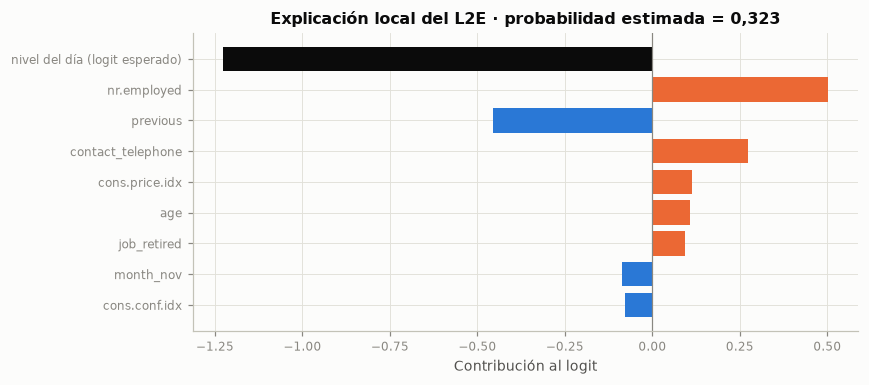

,Valor
age,74
campaign,3
pdays,999
previous,1
cons.price.idx,"94,767"
cons.conf.idx,"-50,800"
nr.employed,"4 963,600"
job,retired
marital,married
education,professional.course


**Interpretación.** Para este cliente, con el estado vigente al cierre de 2010-11, el L2E estima una probabilidad de suscripción de 0,323. El nivel del día aporta -1,23 al logit y la variable con mayor contribución es `nr.employed` (0,50).

De esta forma, la explicación local separa lo que se debe al momento (el nivel del día, común a todos los clientes que se llamen ese día) de lo que se debe al cliente, y responde a la pregunta que se hace un asesor: si conviene llamarlo hoy y por qué.

Por tanto, corresponde incorporar esta salida, la trayectoria del nivel y la tabla de pruebas de la sección 6.7 a la subsección del modelo original de la página Modelos del dashboard (sección 7.3).

In [30]:
cliente = X_te.iloc[[-1]].copy()
dia_nuevo = int(vigente[-1].dia_final_) + 1
fila = cliente.assign(dia=dia_nuevo)
prob = float(vigente.predict_proba(fila)[0, 1])
Z = vigente[:-1].transform(fila)[:, :-1]
m_v = vigente[-1].estado_media_
xbar = vigente[:-1].transform(con_dia(X_tr, tiempo_tr))[:, :-1].mean(axis=0)
contrib = pd.Series(m_v[1:] * (Z[0] - xbar), index=nombres)
nivel_dia = float(m_v[0] + m_v[1:] @ xbar)
top_c = contrib.reindex(contrib.abs().sort_values(ascending=False).index[:8])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(["nivel del día (logit esperado)"] + list(top_c.index), [nivel_dia] + list(top_c.values),
        color=[TINTA] + [NARANJA if v > 0 else AZUL for v in top_c.values])
ax.axvline(0, color=GRIS, lw=0.8)
ax.invert_yaxis()
ax.set(title=f"Explicación local del L2E · probabilidad estimada = {num(prob, 3)}", xlabel="Contribución al logit")
plt.tight_layout()
plt.show()
tabla(cliente[cfg.VARS_NUM + cfg.VARS_CAT].T.rename(columns={cliente.index[0]: "Valor"}), indice=True)
interpretar(
    f"Para este cliente, con el estado vigente al cierre de {periodo_te.iloc[-1]}, el L2E estima una probabilidad de "
    f"suscripción de {num(prob, 3)}. El nivel del día aporta {num(nivel_dia, 2)} al logit y la variable con mayor "
    f"contribución es `{top_c.index[0]}` ({num(top_c.iloc[0], 2)}).",
    conectar("De esta forma,", "La explicación local separa lo que se debe al momento (el nivel del día, común a todos "
             "los clientes que se llamen ese día) de lo que se debe al cliente, y responde a la pregunta que se hace un "
             "asesor: si conviene llamarlo hoy y por qué."),
    conectar("Por tanto, corresponde", "Incorporar esta salida, la trayectoria del nivel y la tabla de pruebas de la "
             "sección 6.7 a la subsección del modelo original de la página Modelos del dashboard (sección 7.3)."))

### 7.3 Dashboard desplegado: arquitectura, decisiones de diseño y despliegue

El dashboard está en línea en Render: **<https://proyecto-final-bank-marketing.onrender.com>**. Tiene las tres páginas que pide la guía (Contexto, EDA y Modelos) y, desde este entregable, el L2E es un modelo más del dashboard: encabeza la tabla de líderes, se puede elegir en la predicción en vivo, tiene su diagnóstico y su SHAP global, entra al diagrama de diferencia crítica y cuenta con su propia subsección.

**Arquitectura.** El repositorio (<https://github.com/DTL-DA/proyecto-final-bank-marketing>) sigue la estructura de la sección 7.2 de la guía; este cuaderno y su código de investigación están en `cuarto_entregable/`:

```text
proyecto-final-bank-marketing/
├── app.py                  punto de entrada: crea la aplicación multipágina y expone server (gunicorn)
├── pages/                  contexto.py, eda.py y modelos.py (una página por sección, con sus callbacks)
├── src/
│   ├── original_model.py   clase del modelo original (copia de producción de bm.modelo_original)
│   ├── data.py             carga y caché de datos, artefactos y resultados precalculados
│   ├── plots.py            funciones que construyen las figuras, con una plantilla común de Plotly
│   ├── explicaciones.py    valores SHAP por permutaciones (sin cargar la librería shap en el servidor)
│   └── componentes.py      componentes propios de los pipelines de los benchmarks
├── artifacts/              un directorio por modelo con modelo.joblib y metadata.json (l2e incluido)
├── data/                   datos livianos para el EDA y resultados precalculados (data/resultados)
├── assets/                 hoja de estilos
├── tests/                  pruebas con pytest: aplicación, artefactos, explicaciones y modelo original
├── book/                   fuentes del Jupyter Book (_config.yml, _toc.yml, references.bib)
├── cuarto_entregable/      este cuaderno, src/bm, scripts, pruebas y resultados del modelo original
├── requirements.txt        versiones exactas
└── render.yaml             configuración del despliegue
```

**Integración del modelo original.** `scripts/exportar_dashboard_l2e.py` toma el modelo final de la sección 7.1, reemplaza las referencias al paquete de investigación `bm` por la copia de producción `src/original_model.py` (el algoritmo es idéntico línea por línea, y `tests/test_original_model.py` lo verifica junto con las 25 pruebas unitarias del modelo), repite la prueba de ida y vuelta, guarda los dos artefactos en `artifacts/l2e/` y agrega el L2E a las tablas precalculadas del dashboard. Como el dashboard nunca entrena ni optimiza, todo lo que muestra sale de esos artefactos y de esas tablas. Para predecir, el dashboard carga `modelo_vigente.joblib` y le asigna al cliente el día siguiente al último cerrado (sección 7.2).

**Decisiones de diseño.**

- *Un producto, no una colección de gráficos:* cada tarjeta responde una pregunta del usuario (a quién llamar primero, qué tan confiable es la probabilidad, qué modelo es mejor y por qué) y termina con una frase de interpretación.
- *Tema y color:* `dash-bootstrap-components` con el tema FLATLY, barra de navegación fija y una paleta de dos colores más grises, validada para visión normal y para las tres formas de daltonismo. El color sigue a la entidad: el L2E es siempre naranja y los benchmarks, azules, y la identidad nunca depende solo del color, porque cada serie tiene su etiqueta.
- *Rendimiento en el plan gratuito:* los datos y los ocho modelos se cargan una sola vez con `functools.lru_cache`; los valores SHAP se estiman con un estimador por permutaciones propio, porque la librería `shap` no cabe en la memoria junto con los modelos, y el L2E solo suma 37 KB de artefactos.
- *Robustez y accesibilidad:* el formulario de predicción se genera desde el esquema de variables y valida tipos y rangos; un error se informa con `dbc.Alert` sin detener la aplicación. Las tablas y las figuras usan la rejilla de `dbc.Row` y `dbc.Col` para escritorio y tableta, con etiquetas descriptivas y contraste suficiente.

**Guía de despliegue.** (1) `python app.py` levanta el dashboard en local en <http://127.0.0.1:8050>. (2) `requirements.txt` fija las versiones exactas, incluido `gunicorn`, y `render.yaml` fija Python 3.12.10. (3) Render construye con `pip install -r requirements.txt` y arranca con `gunicorn app:server --workers 1 --threads 4 --timeout 120`; cada *push* a la rama `main` del repositorio dispara un despliegue nuevo. (4) Después de cada despliegue se revisan los registros de construcción y se recorren las tres páginas en la URL pública. En el plan gratuito el servicio se suspende tras 15 minutos sin visitas y la primera carga tarda cerca de un minuto, por lo que conviene abrirlo unos minutos antes de la sustentación.

**Capturas.** Las capturas se tomaron con `scripts/capturas_dashboard.py` sobre el dashboard local, con los mismos artefactos y datos que la versión en línea.

![Página Contexto del dashboard: problema, pregunta de investigación, datos, metodología y limitaciones](imagenes/dashboard_contexto.png)

![Página EDA del dashboard: filtros globales, distribución del objetivo, explorador bivariado, correlación, faltantes y atípicos](imagenes/dashboard_eda.png)

![Página Modelos, primera parte: tabla de líderes con el L2E, predicción en vivo con su explicación SHAP local y diagnóstico del modelo seleccionado](imagenes/dashboard_modelos_1.png)

![Página Modelos, segunda parte: SHAP global, diagrama de diferencia crítica con el modelo original y subsección del L2E con su veredicto](imagenes/dashboard_modelos_2.png)

In [31]:
ganancia_mejor = bt_ap.set_index("modelo").loc[MEJOR, "diferencia"]
equivalentes = [CORTO[k] for k in COMP[1:] if CORTO[k] not in sig_te]
adic_cols = [c for c in med.columns if c != "bank marketing"]
n_ad_gana = int(sum(r_l2e[c] == 1 for c in adic_cols))
display(Markdown(f"""## 8. Conclusiones y limitaciones

### 8.1 Hallazgos

1. **El límite de los 140 modelos del tercer entregable era temporal, no de flexibilidad.** La tasa diaria de suscripción es un nivel latente con memoria larga (autocorrelación de {num(fac[1], 2)} al primer rezago en el entrenamiento), y un puntaje que solo conoce la tasa de los días cerrados alcanza en el bucle externo un AUC-PR de {num(solo_nivel.iloc[:3]['Media'].max(), 3)}, frente a {num(solo_nivel.iloc[-1]['Media'], 3)} de la mejor de las 140 combinaciones. Ningún modelo estático puede representar esa estructura, y por eso los finalistas eran estadísticamente equivalentes.
2. **El L2E convierte ese hallazgo en un modelo.** Separa un nivel diario que se mueve rápido de unas pendientes que derivan despacio, se ajusta con un Newton por bloques de costo lineal en el número de días y se actualiza con un filtro de Laplace que respeta la demora de las etiquetas. La recalibración mensual que sugirió el docente es un caso límite de su filtro (propiedad P5).
3. **Desempeño.** En el bucle externo, el L2E obtiene {ms(ext['L2E'])}, frente a {ms(ext[MEJOR])} de la mejor combinación; en la prueba, un AUC-PR de {num(ap_te['L2E'], 3)} y un AUC de {num(auc_te['L2E'], 3)}, con una ganancia de {num(ganancia_mejor, 3)} en AUC-PR sobre la mejor combinación y probabilidades calibradas sin recalibración aparte (Brier de {num(resumen.iloc[0]['Brier prueba'], 3)}).
4. **Dónde está la ventaja.** Dentro de cada mes de prueba, el L2E es significativamente mejor que {enumerar(sig_te)}, y en el ordenamiento global de la prueba supera a todos los benchmarks. Frente a {enumerar(equivalentes)} no es superior dentro de cada mes: la ventaja viene de seguir el nivel de conversión entre días, no de ordenar mejor a los clientes de un mismo día.
5. **El mecanismo es transferible.** El filtro de nivel aislado mejora a {c2_gana} de los {len(COMP) - 1} benchmarks cuando se les aplica como envoltorio y supera a la recalibración mensual en {len(c2_vs_mensual)} de {len(con_mensual)} modelos con probabilidades; el mejor de esos híbridos queda a {num(bt_c['diferencia'], 3)} del L2E en AUC-PR de prueba ({p_txt(bt_c['p'])}).
6. **Límites de validez.** La ventaja se reduce con la demora de las etiquetas, y {'en ninguno de los tres conjuntos adicionales el L2E es el mejor modelo' if n_ad_gana == 0 else f'el L2E es el mejor modelo en {n_ad_gana} de los tres conjuntos adicionales'}: donde el nivel latente es débil o lo explican las variables, no supera a los benchmarks. El modelo es una herramienta para problemas de propensión con un nivel persistente, como el telemercadeo bancario, no un clasificador general.
7. **Mejoras evaluadas.** De los cinco ajustes para los árboles y las cinco mejoras del L2E (sección 6.13), {'ninguna supera la regla de decisión declarada, así que el L2E se conserva sin cambios' if (t_mej['Decisión'] == 'Se adopta').sum() == 0 else 'se adopta ' + enumerar(t_mej.loc[t_mej['Decisión'] == 'Se adopta', 'Mejora'].tolist())}; los ajustes que más ayudan a los modelos de referencia son los que usan las etiquetas recientes, el mecanismo del modelo original.

### 8.2 Veredicto sobre R1, R2 y R3

R1 (novedad en la aplicación) y R2 (implementación algorítmica propia) se cumplen. R3 {'se cumple' if r3 else 'no se cumple'} con la definición operativa de la guía: la media externa del L2E supera a la de los siete finalistas, {n_r3} pruebas distintas rechazan la igualdad frente a la mejor combinación benchmark con p ajustado < 0,05 y el efecto es {st.magnitud_cliff(cliff_mejor)} (δ de Cliff = {num(cliff_mejor, 3)}). Por la regla de la guía (sección 12), el tope que corresponde es {'5,0' if r3 else '4,0'}, sujeto a la evaluación del docente.

### 8.3 Limitaciones

- **La significancia depende de la unidad de análisis.** Con los cinco pliegues externos o con los meses de la validación externa ninguna prueba es significativa, porque en 2008 ningún modelo discrimina; la evidencia de superioridad viene de la prueba (2009-2010), que es el régimen de uso pero también un solo periodo.
- **Sin ventaja dentro de cada periodo frente a las mejores logísticas.** El L2E no ordena mejor a los clientes de un mismo mes que una logística bien regularizada o la SVM, y la prueba bayesiana se inclina levemente a favor de ellas; su aporte es el nivel.
- **Condición operativa.** El modelo necesita que las etiquetas de cada día estén disponibles poco después; con demoras de semanas pierde parte de su ventaja.
- **Aproximaciones.** Las pendientes se toman constantes dentro de la ventana de entrenamiento, la posterior se aproxima por Laplace y la probabilidad predictiva por la aproximación probit; ninguna se evaluó frente a una inferencia exacta (por ejemplo, MCMC).
- **Estabilidad de los coeficientes entre pliegues.** El L2E es menos estable que la logística con C = 0,01, porque la validación interna elige un λ distinto en cada pliegue (sección 1.2).
- **Selección de hiperparámetros con pocos datos.** En el primer pliegue de *electricity* la validación interna eligió una dinámica que no existía; con ventanas de ajuste pequeñas, el modelo puede perseguir ruido.
- **Revisión de literatura.** Se hizo con APIs públicas; Scopus y Web of Science no se consultaron por falta de acceso programático, y las búsquedas por relevancia no permiten intersecciones booleanas.
- **Uso de la prueba durante el prototipado.** Durante el desarrollo se evaluaron algunas variantes exploratorias también en la prueba. Las decisiones finales están respaldadas por la evidencia del entrenamiento y del bucle externo (secciones 2.2, 5.8 y 5.9), pero esa consulta previa es una forma de filtración de la prueba hacia el diseño y se declara aquí.

### 8.4 Trabajo futuro

- Validar con datos posteriores a 2010 el ensamble del L2E con un Random Forest reentrenado cada mes (mejora M4), que sube el AUC-PR de la prueba pero no el del bucle externo, y por eso no se adoptó (sección 6.13).
- Buscar una forma de elegir $q_u$ que funcione con ventanas de ajuste cortas: el Bayes empírico (mejora M2) aprende la dinámica del pasado y falla cuando el régimen cambia más de lo que cambiaba antes.
- Extender el nivel a varios grupos (por canal de contacto o por campaña) con un modelo jerárquico, y combinar el filtro con un clasificador no lineal como término fijo, ya que el componente C2 es transferible.
- Evaluar el modelo en datos posteriores a 2010 o en otros problemas de propensión con etiquetas diferidas (abandono de clientes, cobranza, conversión publicitaria).

### 8.5 Declaración de autoría y uso de herramientas de inteligencia artificial

Este trabajo es de autoría de Donny Torres. En su desarrollo se usó Claude (Anthropic) como asistente de programación, análisis y redacción: apoyo en la evaluación crítica del tercer entregable, en la formulación del modelo L2E y la derivación de su algoritmo, en la implementación del código, de las pruebas unitarias y de los *scripts* de experimentación, en la búsqueda y verificación bibliográfica, en la integración del modelo al dashboard, en el armado de este Jupyter Book y en la redacción de los textos. Todas las cifras se calculan con el código incluido y se reproducen con los comandos de la sección 9. El autor revisó el código, las derivaciones y los resultados, y es responsable de comprender, explicar y modificar cualquier parte del algoritmo y de las pruebas estadísticas, como exige la guía (secciones 5.4 y 13).

**Firma:** Donny Torres · Maestría en Analítica de Datos, Universidad del Norte · Barranquilla, 24 de octubre de 2026."""))

## 8. Conclusiones y limitaciones

### 8.1 Hallazgos

1. **El límite de los 140 modelos del tercer entregable era temporal, no de flexibilidad.** La tasa diaria de suscripción es un nivel latente con memoria larga (autocorrelación de 0,76 al primer rezago en el entrenamiento), y un puntaje que solo conoce la tasa de los días cerrados alcanza en el bucle externo un AUC-PR de 0,103, frente a 0,103 de la mejor de las 140 combinaciones. Ningún modelo estático puede representar esa estructura, y por eso los finalistas eran estadísticamente equivalentes.
2. **El L2E convierte ese hallazgo en un modelo.** Separa un nivel diario que se mueve rápido de unas pendientes que derivan despacio, se ajusta con un Newton por bloques de costo lineal en el número de días y se actualiza con un filtro de Laplace que respeta la demora de las etiquetas. La recalibración mensual que sugirió el docente es un caso límite de su filtro (propiedad P5).
3. **Desempeño.** En el bucle externo, el L2E obtiene 0,111 ± 0,116, frente a 0,103 ± 0,108 de la mejor combinación; en la prueba, un AUC-PR de 0,602 y un AUC de 0,772, con una ganancia de 0,068 en AUC-PR sobre la mejor combinación y probabilidades calibradas sin recalibración aparte (Brier de 0,171).
4. **Dónde está la ventaja.** Dentro de cada mes de prueba, el L2E es significativamente mejor que Naive Bayes, XGBoost y Árbol de decisión, y en el ordenamiento global de la prueba supera a todos los benchmarks. Frente a Logística L1/L2, Random Forest, SVM, KNN y Referencia E2 no es superior dentro de cada mes: la ventaja viene de seguir el nivel de conversión entre días, no de ordenar mejor a los clientes de un mismo día.
5. **El mecanismo es transferible.** El filtro de nivel aislado mejora a 6 de los 8 benchmarks cuando se les aplica como envoltorio y supera a la recalibración mensual en 5 de 7 modelos con probabilidades; el mejor de esos híbridos queda a 0,008 del L2E en AUC-PR de prueba (p = 0,070).
6. **Límites de validez.** La ventaja se reduce con la demora de las etiquetas, y en ninguno de los tres conjuntos adicionales el L2E es el mejor modelo: donde el nivel latente es débil o lo explican las variables, no supera a los benchmarks. El modelo es una herramienta para problemas de propensión con un nivel persistente, como el telemercadeo bancario, no un clasificador general.
7. **Mejoras evaluadas.** De los cinco ajustes para los árboles y las cinco mejoras del L2E (sección 6.13), ninguna supera la regla de decisión declarada, así que el L2E se conserva sin cambios; los ajustes que más ayudan a los modelos de referencia son los que usan las etiquetas recientes, el mecanismo del modelo original.

### 8.2 Veredicto sobre R1, R2 y R3

R1 (novedad en la aplicación) y R2 (implementación algorítmica propia) se cumplen. R3 se cumple con la definición operativa de la guía: la media externa del L2E supera a la de los siete finalistas, 3 pruebas distintas rechazan la igualdad frente a la mejor combinación benchmark con p ajustado < 0,05 y el efecto es pequeño (δ de Cliff = 0,156). Por la regla de la guía (sección 12), el tope que corresponde es 5,0, sujeto a la evaluación del docente.

### 8.3 Limitaciones

- **La significancia depende de la unidad de análisis.** Con los cinco pliegues externos o con los meses de la validación externa ninguna prueba es significativa, porque en 2008 ningún modelo discrimina; la evidencia de superioridad viene de la prueba (2009-2010), que es el régimen de uso pero también un solo periodo.
- **Sin ventaja dentro de cada periodo frente a las mejores logísticas.** El L2E no ordena mejor a los clientes de un mismo mes que una logística bien regularizada o la SVM, y la prueba bayesiana se inclina levemente a favor de ellas; su aporte es el nivel.
- **Condición operativa.** El modelo necesita que las etiquetas de cada día estén disponibles poco después; con demoras de semanas pierde parte de su ventaja.
- **Aproximaciones.** Las pendientes se toman constantes dentro de la ventana de entrenamiento, la posterior se aproxima por Laplace y la probabilidad predictiva por la aproximación probit; ninguna se evaluó frente a una inferencia exacta (por ejemplo, MCMC).
- **Estabilidad de los coeficientes entre pliegues.** El L2E es menos estable que la logística con C = 0,01, porque la validación interna elige un λ distinto en cada pliegue (sección 1.2).
- **Selección de hiperparámetros con pocos datos.** En el primer pliegue de *electricity* la validación interna eligió una dinámica que no existía; con ventanas de ajuste pequeñas, el modelo puede perseguir ruido.
- **Revisión de literatura.** Se hizo con APIs públicas; Scopus y Web of Science no se consultaron por falta de acceso programático, y las búsquedas por relevancia no permiten intersecciones booleanas.
- **Uso de la prueba durante el prototipado.** Durante el desarrollo se evaluaron algunas variantes exploratorias también en la prueba. Las decisiones finales están respaldadas por la evidencia del entrenamiento y del bucle externo (secciones 2.2, 5.8 y 5.9), pero esa consulta previa es una forma de filtración de la prueba hacia el diseño y se declara aquí.

### 8.4 Trabajo futuro

- Validar con datos posteriores a 2010 el ensamble del L2E con un Random Forest reentrenado cada mes (mejora M4), que sube el AUC-PR de la prueba pero no el del bucle externo, y por eso no se adoptó (sección 6.13).
- Buscar una forma de elegir $q_u$ que funcione con ventanas de ajuste cortas: el Bayes empírico (mejora M2) aprende la dinámica del pasado y falla cuando el régimen cambia más de lo que cambiaba antes.
- Extender el nivel a varios grupos (por canal de contacto o por campaña) con un modelo jerárquico, y combinar el filtro con un clasificador no lineal como término fijo, ya que el componente C2 es transferible.
- Evaluar el modelo en datos posteriores a 2010 o en otros problemas de propensión con etiquetas diferidas (abandono de clientes, cobranza, conversión publicitaria).

### 8.5 Declaración de autoría y uso de herramientas de inteligencia artificial

Este trabajo es de autoría de Donny Torres. En su desarrollo se usó Claude (Anthropic) como asistente de programación, análisis y redacción: apoyo en la evaluación crítica del tercer entregable, en la formulación del modelo L2E y la derivación de su algoritmo, en la implementación del código, de las pruebas unitarias y de los *scripts* de experimentación, en la búsqueda y verificación bibliográfica, en la integración del modelo al dashboard, en el armado de este Jupyter Book y en la redacción de los textos. Todas las cifras se calculan con el código incluido y se reproducen con los comandos de la sección 9. El autor revisó el código, las derivaciones y los resultados, y es responsable de comprender, explicar y modificar cualquier parte del algoritmo y de las pruebas estadísticas, como exige la guía (secciones 5.4 y 13).

**Firma:** Donny Torres · Maestría en Analítica de Datos, Universidad del Norte · Barranquilla, 24 de octubre de 2026.

## 9. Reproducibilidad y bibliografía

### 9.1 Entorno, semillas y ejecución

- **Entorno:** `conda create -n bm_e3 python=3.12`, `pip install -r requirements.txt` y `python -m ipykernel install --user --name bm_e3`. Semilla global `SEED = 42` en `src/bm/config.py`; el L2E es determinista y la semilla solo afecta a Optuna.
- **Datos:** `data/bank-additional-full.csv` (UCI, CC BY 4.0) y los tres conjuntos de OpenML (identificadores 1169, 151 y 1487), que `sklearn.datasets.fetch_openml` descarga en `data/adicionales/` la primera vez.
- **Orden de ejecución** (desde la raíz del proyecto): `python scripts/importar_e3.py` (resultados del tercer entregable), `python scripts/ejecutar_original.py` (validación anidada, ablación, semillas y modelos finales; unos 6 minutos con 10 núcleos), `python scripts/ejecutar_adicionales.py` (conjuntos adicionales; unos 25 minutos), `python scripts/ejecutar_analisis.py` (sensibilidad, robustez, complejidad y SHAP), `python scripts/revision_literatura.py` y `python scripts/verificar_referencias.py` (revisión y bibliografía), `pytest -q tests` y `python scripts/construir_cuaderno.py --ejecutar`. Para el dashboard y el libro (en el repositorio, desde `cuarto_entregable/`): `python scripts/exportar_dashboard_l2e.py --app ..` (artefactos y resultados del L2E en el dashboard), `python scripts/capturas_dashboard.py --url <URL del dashboard>` (capturas del capítulo 7) y `python scripts/construir_libro.py --libro ../book` (fuentes del Jupyter Book, que se compila con `jupyter-book build book/`).

In [32]:
display(Markdown("### 9.2 Tabla maestra de experimentos"))
m_e3 = maestra[["tarea", "modelo", "balanceo", "optimizador", "auc_pr_media", "auc_pr_de", "auc_media", "auc_de",
                "rmse_media", "rmse_de", "r2_media", "t_opt_total", "t_fit_medio", "t_pred_medio", "seed"]].copy()
m_e3["origen"] = "Tercer entregable"
filas = []
for v in VARIANTES:
    c_ = corr[v]
    filas.append({"tarea": "clf", "modelo": f"l2e:{v}", "balanceo": "ninguno", "optimizador": "bayes",
                  "auc_pr_media": np.mean([c["auc_pr"] for c in c_]), "auc_pr_de": np.std([c["auc_pr"] for c in c_], ddof=1),
                  "auc_media": np.mean([c["auc"] for c in c_]), "auc_de": np.std([c["auc"] for c in c_], ddof=1),
                  "t_opt_total": sum(c["t_opt"] for c in c_), "t_fit_medio": np.mean([c["t_fit"] for c in c_]),
                  "t_pred_medio": np.mean([c["t_pred"] for c in c_]), "seed": SEED, "origen": "Modelo original"})
for s, c_ in corr_sem.items():
    filas.append({"tarea": "clf", "modelo": "l2e:l2e", "balanceo": "ninguno", "optimizador": "bayes",
                  "auc_pr_media": np.mean([c["auc_pr"] for c in c_]), "auc_pr_de": np.std([c["auc_pr"] for c in c_], ddof=1),
                  "auc_media": np.mean([c["auc"] for c in c_]), "auc_de": np.std([c["auc"] for c in c_], ddof=1),
                  "t_opt_total": sum(c["t_opt"] for c in c_), "t_fit_medio": np.mean([c["t_fit"] for c in c_]),
                  "t_pred_medio": np.mean([c["t_pred"] for c in c_]), "seed": s, "origen": "Modelo original (semilla)"})
maestra_e4 = pd.concat([m_e3, pd.DataFrame(filas)], ignore_index=True)
maestra_e4["prueba_auc_pr"] = maestra_e4["modelo"].map(lambda m: fin_l2e[m.split(":")[1]]["auc_pr"] if m.startswith("l2e:") else np.nan)
maestra_e4.loc[maestra_e4["origen"] == "Modelo original (semilla)", "prueba_auc_pr"] = [fin_sem[s]["auc_pr"] for s in corr_sem]
maestra_e4.to_csv(RES / "tabla_maestra_e4.csv", index=False)
maestra_e4.to_parquet(RES / "tabla_maestra_e4.parquet", index=False)
tabla(maestra_e4[maestra_e4["tarea"] == "clf"].sort_values("auc_pr_media", ascending=False).head(15), dec=4, indice=False)
n_e3 = maestra_e4["origen"].eq("Tercer entregable")
print(f"Tabla maestra: {len(maestra_e4)} filas ({n_e3.sum()} combinaciones del tercer entregable, "
      f"{(n_e3 & maestra_e4['tarea'].eq('clf')).sum()} de clasificación y {(n_e3 & maestra_e4['tarea'].eq('reg')).sum()} de "
      f"regresión, y {(~n_e3).sum()} corridas del modelo original) en resultados/tabla_maestra_e4.csv y .parquet")
assert n_e3.sum() == 140

### 9.2 Tabla maestra de experimentos

tarea,modelo,balanceo,optimizador,auc_pr_media,auc_pr_de,auc_media,auc_de,rmse_media,rmse_de,r2_media,t_opt_total,t_fit_medio,t_pred_medio,seed,origen,prueba_auc_pr
clf,l2e:sin_pendientes,ninguno,bayes,"0,1152","0,0974","0,5818","0,0837",—,—,—,"188,5084","0,8676","0,2134",42,Modelo original,"0,5713"
clf,l2e:l2e,ninguno,bayes,"0,1107","0,1156","0,5598","0,1017",—,—,—,"195,4794","0,9101","0,2541",42,Modelo original,"0,6019"
clf,l2e:sin_nivel_latente,ninguno,bayes,"0,1099","0,1203","0,5532","0,1076",—,—,—,"193,3446","0,8529","0,2595",42,Modelo original,"0,5968"
clf,l2e:l2e,ninguno,bayes,"0,1091","0,1162","0,5568","0,1017",—,—,—,"191,4051","0,8851","0,2893",1,Modelo original (semilla),"0,6035"
clf,l2e:l2e,ninguno,bayes,"0,1083","0,1166","0,5565","0,1035",—,—,—,"185,6307","0,8457","0,2579",2,Modelo original (semilla),"0,5966"
clf,l2e:l2e,ninguno,bayes,"0,1068","0,1151","0,5538","0,1028",—,—,—,"188,9591","0,8921","0,2768",3,Modelo original (semilla),"0,5926"
clf,l2e:sin_incertidumbre,ninguno,bayes,"0,1060","0,1140","0,5597","0,1031",—,—,—,"191,5351","0,8510","0,2199",42,Modelo original,"0,5935"
clf,naive_bayes,class_weight,bayes,"0,1028","0,1081","0,5368","0,1019",—,—,—,"151,4339","0,6616","0,3423",42,Tercer entregable,—
clf,naive_bayes,smote,genetico,"0,0997","0,0955","0,5405","0,0771",—,—,—,"167,7956","0,7896","0,3051",42,Tercer entregable,—
clf,naive_bayes,smote,random,"0,0997","0,0958","0,5405","0,0762",—,—,—,"168,0762","0,8392","0,3538",42,Tercer entregable,—


Tabla maestra: 150 filas (140 combinaciones del tercer entregable, 112 de clasificación y 28 de regresión, y 10 corridas del modelo original) en resultados/tabla_maestra_e4.csv y .parquet


### 9.3 Referencias

Las entradas en formato BibTeX están en `resultados/literatura/references.bib`; las que tienen DOI se generaron desde doi.org con `scripts/verificar_referencias.py`.

- Akiba, T., Sano, S., Yanase, T., Ohta, T. y Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining*, 2623-2631. <https://doi.org/10.1145/3292500.3330701>
- Benavoli, A., Corani, G., Demšar, J. y Zaffalon, M. (2017). Time for a change: A tutorial for comparing multiple classifiers through Bayesian analysis. *Journal of Machine Learning Research*, 18(77), 1-36.
- Bergstra, J., Bardenet, R., Bengio, Y. y Kégl, B. (2011). Algorithms for hyper-parameter optimization. *Advances in Neural Information Processing Systems*, 24.
- Boyd, S. y Vandenberghe, L. (2004). *Convex optimization*. Cambridge University Press. <https://doi.org/10.1017/CBO9780511804441>
- Cawley, G. C. y Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *Journal of Machine Learning Research*, 11, 2079-2107.
- Chowdary, B. V., Keerthi, K. L., Sandhya, D., Sunny, Ch. y Reddy, M. D. (2025). Advancing telemarketing success using ensemble-driven online machine learning. *2025 5th International Conference on Soft Computing for Security Applications (ICSCSA)*, 974-978. <https://doi.org/10.1109/icscsa66339.2025.11170856>
- Cliff, N. (1993). Dominance statistics: Ordinal analyses to answer ordinal questions. *Psychological Bulletin*, 114(3), 494-509. <https://doi.org/10.1037/0033-2909.114.3.494>
- DeLong, E. R., DeLong, D. M. y Clarke-Pearson, D. L. (1988). Comparing the areas under two or more correlated receiver operating characteristic curves: A nonparametric approach. *Biometrics*, 44(3), 837-845. <https://doi.org/10.2307/2531595>
- Demšar, J. (2006). Statistical comparisons of classifiers over multiple data sets. *Journal of Machine Learning Research*, 7, 1-30.
- Diebold, F. X. y Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253-263. <https://doi.org/10.1080/07350015.1995.10524599>
- Durbin, J. y Koopman, S. J. (2012). *Time series analysis by state space methods* (2.ª ed.). Oxford University Press. <https://doi.org/10.1093/acprof:oso/9780199641178.001.0001>
- Fahrmeir, L. (1992). Posterior mode estimation by extended Kalman filtering for multivariate dynamic generalized linear models. *Journal of the American Statistical Association*, 87(418), 501-509. <https://doi.org/10.1080/01621459.1992.10475232>
- Gama, J., Žliobaitė, I., Bifet, A., Pechenizkiy, M. y Bouchachia, A. (2014). A survey on concept drift adaptation. *ACM Computing Surveys*, 46(4), 1-37. <https://doi.org/10.1145/2523813>
- Garg, S., Wu, Y., Balakrishnan, S. y Lipton, Z. C. (2020). A unified view of label shift estimation. *Advances in Neural Information Processing Systems*, 33.
- Grzenda, M., Gomes, H. M. y Bifet, A. (2020). Delayed labelling evaluation for data streams. *Data Mining and Knowledge Discovery*, 34(5), 1237-1266. <https://doi.org/10.1007/s10618-019-00654-y>
- Harries, M. (1999). *SPLICE-2 comparative evaluation: Electricity pricing* [Informe técnico]. University of New South Wales.
- Harvey, D., Leybourne, S. y Newbold, P. (1997). Testing the equality of prediction mean squared errors. *International Journal of Forecasting*, 13(2), 281-291. <https://doi.org/10.1016/S0169-2070(96)00719-4>
- Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6(2), 65-70.
- Kalman, R. E. (1960). A new approach to linear filtering and prediction problems. *Journal of Basic Engineering*, 82(1), 35-45. <https://doi.org/10.1115/1.3662552>
- Lipton, Z. C., Wang, Y.-X. y Smola, A. J. (2018). Detecting and correcting for label shift with black box predictors. *Proceedings of the 35th International Conference on Machine Learning*, PMLR 80, 3122-3130.
- Lundberg, S. M. y Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems*, 30.
- MacKay, D. J. C. (1992). The evidence framework applied to classification networks. *Neural Computation*, 4(5), 720-736. <https://doi.org/10.1162/neco.1992.4.5.720>
- McCormick, T. H., Raftery, A. E., Madigan, D. y Burd, R. S. (2012). Dynamic logistic regression and dynamic model averaging for binary classification. *Biometrics*, 68(1), 23-30. <https://doi.org/10.1111/j.1541-0420.2011.01645.x>
- Moro, S., Cortez, P. y Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems*, 62, 22-31. <https://doi.org/10.1016/j.dss.2014.03.001>
- Nadeau, C. y Bengio, Y. (2003). Inference for the generalization error. *Machine Learning*, 52(3), 239-281. <https://doi.org/10.1023/A:1024068626366>
- Politis, D. N. y Romano, J. P. (1994). The stationary bootstrap. *Journal of the American Statistical Association*, 89(428), 1303-1313. <https://doi.org/10.1080/01621459.1994.10476870>
- Romano, J., Kromrey, J. D., Coraggio, J. y Skowronek, J. (2006). Appropriate statistics for ordinal level data: Should we really be using t-test and Cohen's d for evaluating group differences on the NSSE and other surveys? *Annual Meeting of the Florida Association of Institutional Research*.
- Saerens, M., Latinne, P. y Decaestecker, C. (2002). Adjusting the outputs of a classifier to new a priori probabilities: A simple procedure. *Neural Computation*, 14(1), 21-41. <https://doi.org/10.1162/089976602753284446>
- Varma, S. y Simon, R. (2006). Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics*, 7, 91. <https://doi.org/10.1186/1471-2105-7-91>
- West, M., Harrison, P. J. y Migon, H. S. (1985). Dynamic generalized linear models and Bayesian forecasting. *Journal of the American Statistical Association*, 80(389), 73-83. <https://doi.org/10.1080/01621459.1985.10477131>
- Zhang, K. y Fan, W. (2008). Forecasting skewed biased stochastic ozone days: Analyses, solutions and beyond. *Knowledge and Information Systems*, 14(3), 299-326. <https://doi.org/10.1007/s10115-007-0095-1>